# Land cover from Sentinel-1 radar

**A Deep-Learning Model, a Monthly-Change Prototype and an Honest Evaluation**

Deep Learning · Final project report · notebook: data, training and evaluation record

Sentinel-1 VV and VH backscatter · FPN with an ImageNet-initialised ResNet-50 · six land-cover classes at 10 m · Streamlit prototype with monthly change maps

| | |
| --- | --- |
| **Under the guidance of** | Prof. Dr.-Ing. Binh Vu |
| **Submitted by** | Shruti Shankar Bhandari |
| **Course** | Deep Learning, SRH University Heidelberg |
| **Date** | 9 November 2026 |
| **Hardware** | MacBook with Apple Silicon (PyTorch on MPS) |

*Data: Copernicus Sentinel-1 via Google Earth Engine · ESA WorldCover 2021 · CORINE Land Cover 2018*

---

This notebook is the recorded run of the whole project: choosing the places, downloading Sentinel-1 and labels, building the training cache, training and comparing the models, the three looks at the test set, the prototype measurements and the exact training exposure. The cells were run in several sessions and the outputs below are the saved results. **Every number in the report comes from an output in this notebook.** The prototype (Streamlit app) and the report are separate deliverables.

> **DO NOT RE-RUN THIS NOTEBOOK. It is a record of a finished run, not a script.** It needs the Google Drive dataset (65.5 GB for the first 300 places), a local cache (24.4 GB) and Earth Engine access. Three cells would delete or overwrite data (Part 1 project folders, Part 3 output folder, Part 3 inventory and statistics). All three are disabled with a safety guard that stops with an error, and their original code is kept only as a commented-out record. Do not use *Run All*.

## Contents

| Part | What happens | Main output | Report section |
| --- | --- | --- | --- |
| 1 | Setup and Earth Engine access | connection check | – |
| 2 | Choosing the 300 places | 187 train, 41 validation, 39 test, 33 in two held-out regions | 2.3 |
| 3 | Download of Sentinel-1 and labels, inventory, training cache | 65.5 GB, 27,695 images, 298 usable places | 2.1 to 2.5 |
| 4 | First models, validation, first and second look at the test set | `v4_fpn_ctx`, `v4_fpn_ctx2`, ensemble and offsets | 4 |
| 5 | 72 extra training places and the five v4b models | 370 places; ImageNet-pretrained FPN | 2.3, 3, 4 |
| 6 | Validation comparison, rules, final test | test OA 0.764, mIoU 0.633 | 4, 5 |
| 7 | Prototype measurements | seam test, false change | 6.4, 6.5 |
| 8 | How much training data the final model saw | 40.7% of the distinct patches | 3.5 |
| 9 | Training curves, generalisation gap, variant comparison, test metrics and confusion matrices | figures, tables | 5.5 |
| 10 | Summary of results and caveats | table | – |


## Part 1: Setup and Earth Engine access

Installs and imports the packages, then authenticates with Google Earth Engine and checks the connection by reading a test image (the output `GEE connected: Image` confirms it). The pip notice in the first output is harmless.

In [1]:
!pip install earthengine-api numpy pandas requests -q
import os, glob, shutil, json
import numpy as np, pandas as pd, ee
print('ready')


ready


In [2]:
ee.Authenticate()
ee.Initialize(project='friendly-aurora-426714-v0')
test = ee.Image('NASA/NASADEM_HGT/001').getInfo()
print('GEE connected:', test['type'])

GEE connected: Image


### Project folders: record only, do not run

Sets the Google Drive paths of the project. The original code **deleted the folder `native_v4_project`** if it existed (the first output line shows that it did when it was first run). Running it again would erase the downloaded dataset, so the cell is disabled and its code is commented out. It is kept only as a record of how the folders were created.


In [3]:
# RECORD ONLY: this cell was run once during the project and is disabled. Do not run it again.
raise RuntimeError('RECORD ONLY: this cell changes or deletes data. It was run once and is disabled.')
# --- original code below, kept as a record of what was run (commented out) ---
# BASE_DIR = os.path.expanduser('~/Google Drive/My Drive/LULC_project')
# if not os.path.isdir(BASE_DIR):
#     BASE_DIR = glob.glob(os.path.expanduser('~/Library/CloudStorage/GoogleDrive-*/My Drive/LULC_project'))[0]
# V4_DIR   = f'{BASE_DIR}/native_v4_project'
# DATA_DIR = f'{V4_DIR}/data'
# OUT_DIR  = f'{DATA_DIR}/native_v4'
# SCENES   = f'{DATA_DIR}/scenes_v4.csv'
#
# if os.path.isdir(V4_DIR):
#     shutil.rmtree(V4_DIR); print('deleted', V4_DIR)
# os.makedirs(OUT_DIR, exist_ok=True)
# print('ready:', DATA_DIR)

deleted /Users/shrutibhandari/Google Drive/My Drive/LULC_project/native_v4_project
ready: /Users/shrutibhandari/Google Drive/My Drive/LULC_project/native_v4_project/data


## Part 2: Choosing the 300 places

One cell builds the list of places from Earth Engine queries and rules written in the code (seed 2026):

- **Candidates:** 10,000 random land points, each looked up in the RESOLVE 2017 ecoregion map, plus 1,000 MODIS urban pixels as a second frame.
- **Filters:** at least 20 Sentinel-1 passes in each of 2020 and 2021 and at least 50 in total (a judgement; 120 images is only an upper limit), at least 50% labelled pixels, places at least 20 km apart.
- **Strata** from the WorldCover class shares of each 10 km box, with quotas: Urban 66, Peri-urban 24, Shrub/Grass 48, Shrub-mixed 24, Cropland 30, Bare/Arid 24, Water/Wetland 18, Forest 30, plus 36 class-blind random places for natural-frequency estimates (300 in total).
- **Splits** by 10° geographic blocks, so no block feeds two splits. Australia and South Asia are held out entirely. The block of Heidelberg and a 100 km radius around it are excluded, so Heidelberg can serve as an independent case study.
- **Outputs:** `scenes_v4.csv` (the 300 places) and `pool_v4.csv` (the eligible pool of 3,623 candidates, used later to pick the extra training places).

In [4]:
CFG = {'OUT_DIR': DATA_DIR, 'N_RANDOM': 10000, 'N_MODIS': 1000}
import math, time, os
import numpy as np, pandas as pd, ee

CFG = globals().get('CFG', {})          
PROJECT = CFG.get('PROJECT', 'friendly-aurora-426714-v0')

def init_ee():
    try:
        ee.Initialize(project=PROJECT); return
    except Exception:
        pass
    import google.auth
    for attempt in range(2):
        try:
            creds, _ = google.auth.default()
            ee.Initialize(creds, project=PROJECT); return
        except Exception:
            if attempt == 1:
                raise
            from google.colab import auth       # only exists on Colab
            auth.authenticate_user()
init_ee()

# ------------------------------------------------------------------ settings
SEED = 2026
N_RANDOM, N_MODIS = CFG.get('N_RANDOM', 400), CFG.get('N_MODIS', 60)     
OUT_DIR = CFG.get('OUT_DIR', '.')
CHUNK = CFG.get('CHUNK', 100)           # points per Earth Engine request; lower it if you see timeouts
HALF, BLOCK_DEG = 5000, 10             # 10 km box (1000 px at 10 m); 10-degree spatial blocks
MIN_PASS = {2020: 20, 2021: 20}        # minimum Sentinel-1 passes at the point in each year (my judgement)
MIN_TOTAL = 50                         # and over both years (my judgement). 120 images (5 per month) is only an upper limit, not a requirement
MIN_LABELLED, MIN_SEP_KM = 0.5, 20
QUOTA = {'Urban': 66, 'Peri-urban': 24, 'Shrub/Grass': 48, 'Shrub-mixed': 24,
         'Cropland': 30, 'Bare/Arid': 24, 'Water/Wetland': 18, 'Forest': 30}      # 264 scenes ...
N_NATURAL = 36                         # ... plus 36 class-blind random scenes = 300                        # class-blind random scenes, for natural-frequency estimates
CASE = {'Heidelberg': (49.41, 8.68)}   # case-study city: its block and a 100 km radius are excluded
HOLDOUT = {'Australia': (-45, -10, 112, 155), 'South_Asia': (5, 35, 68, 98)}   # lat_min, lat_max, lon_min, lon_max

# ==== PURE FUNCTIONS (tested offline) ====
import re
import numpy as np, pandas as pd

NAMES6 = ['Forest', 'Shrub/Grass', 'Cropland', 'Urban', 'Bare/Arid', 'Water/Wetland']

def km(la1, lo1, la2, lo2):
    p = np.pi / 180
    h = np.sin((la2 - la1) * p / 2) ** 2 + np.cos(la1 * p) * np.cos(la2 * p) * np.sin((lo2 - lo1) * p / 2) ** 2
    return 12742 * np.arcsin(np.sqrt(h))

def stratum_of(r):
    others = max(r.f0, r.f2, r.f4)
    if r.f3 >= 0.10: return 'Urban'
    if r.f3 >= 0.03: return 'Peri-urban'
    if r.f5 >= 0.30: return 'Water/Wetland'
    if r.f1 >= 0.40: return 'Shrub/Grass'
    if r.f1 >= 0.15 and others >= 0.20: return 'Shrub-mixed'
    if r.f4 >= 0.40: return 'Bare/Arid'
    if r.f2 >= 0.40: return 'Cropland'
    if r.f0 >= 0.50: return 'Forest'
    return 'Mixed'

def select_scenes(pool, quota, n_natural, min_sep_km):
    """pool: shuffled, reset-index DataFrame. Natural (class-blind, random frame) scenes first, then quotas."""
    clat, clon, sel_as = [], [], {}
    def far(i):
        return not clat or (km(pool.lat[i], pool.lon[i], np.array(clat), np.array(clon)) > min_sep_km).all()
    def take(i, why):
        clat.append(pool.lat[i]); clon.append(pool.lon[i]); sel_as[i] = why
    n = 0
    for i in pool.index[pool.frame == 'random']:
        if n >= n_natural: break
        if far(i): take(i, 'natural'); n += 1
    for st, q in quota.items():
        n = sum(1 for v in sel_as.values() if v == st)
        for i in pool.index[pool.stratum == st]:
            if n >= q: break
            if i not in sel_as and far(i): take(i, st); n += 1
    sel = pool.loc[list(sel_as)].copy()
    sel['selected_as'] = [sel_as[i] for i in sel.index]
    return sel.reset_index(drop=True)

def add_weights(pool, sel):
    """Stratified weights for natural-frequency estimates; random frame only."""
    Nh = pool[pool.frame == 'random'].stratum.value_counts()
    nh = sel[sel.frame == 'random'].stratum.value_counts()
    sel['weight'] = [Nh[s] / nh[s] if f == 'random' else np.nan for s, f in zip(sel.stratum, sel.frame)]
    return sel

def assign_splits(sel, holdout, seed, key_strata=('Urban', 'Peri-urban', 'Shrub/Grass', 'Shrub-mixed')):
    """Two held-out regions; the remaining 10-degree blocks go to train/val/test (70/15/15), balanced per stratum."""
    sel['split'] = ''
    for nm, (a, b, c, d) in holdout.items():
        sel.loc[sel.lat.between(a, b) & sel.lon.between(c, d), 'split'] = f'region_{nm.lower()}'
    free = sel.split == ''
    cnt = pd.crosstab(sel.loc[free, 'block'], sel.loc[free, 'stratum'])          # blocks x strata
    tot = cnt.sum(axis=0).astype(float); w = np.array([3.0 if s in key_strata else 1.0 for s in cnt.columns])
    goal = {'train': .70, 'val': .15, 'test': .15}; got = {k: np.zeros(len(cnt.columns)) for k in goal}
    perm = np.random.default_rng(seed).permutation(len(cnt))
    order = cnt.iloc[perm].sum(axis=1).sort_values(ascending=False, kind='stable').index      # big blocks first, random ties
    assign = {}
    for b in order:
        c = cnt.loc[b].to_numpy(float)
        k = max(goal, key=lambda s: float((w * c * (goal[s] - got[s] / tot.to_numpy())).sum()))
        assign[b] = k; got[k] += c
    sel.loc[free, 'split'] = sel.loc[free, 'block'].map(assign)
    return sel

def slug(s, n=26):
    return re.sub(r'[^A-Za-z0-9]+', '_', str(s)).strip('_')[:n].strip('_')

def add_names(sel):
    sel['name'] = [f'{slug(e)}_{i:04d}' for i, e in enumerate(sel.ecoregion)]
    sel['display'] = sel.ecoregion + ' (' + sel.biome + ')'
    return sel

def build_scenes(cand, ECO, quota, n_natural, min_sep_km, block_deg, holdout, case, min_pass, min_total, min_labelled, seed):
    """Names, strata, eligibility, selection, weights, splits. Returns (selected scenes, eligible pool)."""
    cand = cand.copy(); unk = ('Unknown',) * 3
    for j, col in enumerate(['ecoregion', 'biome', 'realm']):
        cand[col] = cand.eco_id.map(lambda e: ECO.get(int(e), unk)[j])
    cand['stratum'] = cand.apply(stratum_of, axis=1)
    cand['block'] = np.floor(cand.lat / block_deg).astype(int).astype(str) + '_' + np.floor(cand.lon / block_deg).astype(int).astype(str)
    ok = ((cand.n2021 >= min_pass[2021]) & (cand.n2020 >= min_pass[2020]) & ((cand.n2020 + cand.n2021) >= min_total)
          & (cand.labelled >= min_labelled))
    for nm, (la, lo) in case.items():
        cb = f'{int(np.floor(la / block_deg))}_{int(np.floor(lo / block_deg))}'
        ok &= (cand.block != cb) & (km(cand.lat.values, cand.lon.values, la, lo) > 100)
    pool = cand[ok].sample(frac=1, random_state=seed).reset_index(drop=True)
    sel = select_scenes(pool, quota, n_natural, min_sep_km)
    sel = add_weights(pool, sel); sel = assign_splits(sel, holdout, seed); sel = add_names(sel)
    return sel, pool

SCENE_COLS = ['name', 'display', 'ecoregion', 'biome', 'realm', 'lat', 'lon', 'stratum', 'selected_as', 'frame', 'weight',
              'split', 'block', 'n2020', 'n2021'] + [f'f{c}' for c in range(6)]
# ==== END PURE ====

# ------------------------------------------------------------------ Earth Engine queries (not testable offline)
eco_fc = ee.FeatureCollection('RESOLVE/ECOREGIONS/2017')
ECO = {int(i): (e, b, r) for i, e, b, r in zip(eco_fc.aggregate_array('ECO_ID').getInfo(), eco_fc.aggregate_array('ECO_NAME').getInfo(),
                                              eco_fc.aggregate_array('BIOME_NAME').getInfo(), eco_fc.aggregate_array('REALM').getInfo())}
eco_img = eco_fc.reduceToImage(['ECO_ID'], ee.Reducer.first())
print(len(ECO), 'ecoregions loaded')

wc   = ee.ImageCollection('ESA/WorldCover/v200').first().select('Map')                    # 2021 labels
cls6 = wc.remap([10, 20, 30, 40, 50, 60, 70, 80, 90, 95, 100], [0, 1, 1, 2, 3, 4, 4, 5, 5, 5, 4]).rename('c6')
def s1_year(y):
    return (ee.ImageCollection('COPERNICUS/S1_GRD').filterDate(f'{y}-01-01', f'{y + 1}-01-01')
            .filter(ee.Filter.eq('instrumentMode', 'IW'))
            .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VV'))
            .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VH')))
S1 = {y: s1_year(y) for y in (2020, 2021)}
EXPECT_PX = (2 * HALF / 40) ** 2

def describe(f):
    box = f.geometry().buffer(HALF).bounds()
    hist = cls6.reduceRegion(ee.Reducer.frequencyHistogram(), box, scale=40, maxPixels=int(1e9)).get('c6')
    return f.set({'hist': hist, 'n2020': S1[2020].filterBounds(f.geometry()).size(),
                  'n2021': S1[2021].filterBounds(f.geometry()).size()})

def chunks(seq, n=None):
    n = n or CHUNK
    for i in range(0, len(seq), n):
        yield i, seq[i:i + n]

def with_retry(fn, tries=3):
    for a in range(tries):
        try:
            return fn()
        except Exception as e:
            print('   retry', str(e)[:70]); time.sleep(5 * (a + 1))
    return None

def query_eco(points, tag):                      # keep land points, attach the ecoregion id
    out = []
    for i, ch in chunks(points):
        fc = ee.FeatureCollection([ee.Feature(ee.Geometry.Point([lo, la]), {'k': j}) for j, (la, lo) in enumerate(ch)])
        res = with_retry(lambda: eco_img.reduceRegions(fc, ee.Reducer.first().setOutputs(['eco']), scale=1000).getInfo()['features'])
        for f in res or []:
            p = f['properties']
            if p.get('eco') is not None:
                out.append((ch[p['k']][0], ch[p['k']][1], int(p['eco'])))
        print(f'  [{tag}] ecoregion lookup {min(i + CHUNK, len(points))}/{len(points)} -> {len(out)} on land')
    return out

def query_desc(pts, frame):
    rows = []
    for i, ch in chunks(pts):
        fc = ee.FeatureCollection([ee.Feature(ee.Geometry.Point([lo, la]), {'k': j}) for j, (la, lo, e) in enumerate(ch)])
        feats = with_retry(lambda: fc.map(describe).getInfo()['features'])
        for f in feats or []:
            p = f['properties']; h = p.get('hist')
            if not h: continue
            h = {int(float(k)): v for k, v in h.items()}; tot = sum(h.values())
            la, lo, e = ch[p['k']]
            rows.append({'frame': frame, 'lat': la, 'lon': lo, 'eco_id': e, 'n2020': p['n2020'], 'n2021': p['n2021'],
                         'labelled': tot / EXPECT_PX, **{f'f{c}': h.get(c, 0) / tot for c in range(6)}})
        print(f'  [{frame}] class shares {min(i + CHUNK, len(pts))}/{len(pts)}, {len(rows)} usable')
    return pd.DataFrame(rows)


# ------------------------------------------------------------------ run
rng = np.random.default_rng(SEED)
z = rng.uniform(math.sin(math.radians(-56)), math.sin(math.radians(78)), N_RANDOM)          # equal area in latitude
rand_land = query_eco(list(zip(np.degrees(np.arcsin(z)), rng.uniform(-180, 180, N_RANDOM))), 'random')
modis_land = []
try:
    modis = ee.ImageCollection('MODIS/061/MCD12Q1').filterDate('2021-01-01', '2022-01-01').first()
    up = modis.select('LC_Type1').eq(13).rename('urban').toInt().stratifiedSample(
        numPoints=0, classBand='urban', region=ee.Geometry.Rectangle([-180, -56, 180, 78], None, False), scale=500,
        seed=SEED, classValues=[1], classPoints=[N_MODIS], geometries=True, tileScale=8)
    modis_land = query_eco([(f['geometry']['coordinates'][1], f['geometry']['coordinates'][0]) for f in up.getInfo()['features']], 'modis_urban')
except Exception as e:
    print('MODIS urban sampling failed:', str(e)[:150])
cand = pd.concat([query_desc(rand_land, 'random'), query_desc(modis_land, 'modis_urban')], ignore_index=True)
assert len(cand) > 0, 'no candidates returned: check the Earth Engine connection'

sel, pool = build_scenes(cand, ECO, QUOTA, N_NATURAL, MIN_SEP_KM, BLOCK_DEG, HOLDOUT, CASE, MIN_PASS, MIN_TOTAL, MIN_LABELLED, SEED)
os.makedirs(OUT_DIR, exist_ok=True)
sel[SCENE_COLS].to_csv(os.path.join(OUT_DIR, 'scenes_v4.csv'), index=False); pool.to_csv(os.path.join(OUT_DIR, 'pool_v4.csv'), index=False)
print('saved', os.path.join(OUT_DIR, 'scenes_v4.csv'))

print(f'\ncandidates {len(cand)} -> eligible {len(pool)} -> selected {len(sel)} | named {int((sel.ecoregion != "Unknown").sum())} | '
      f'ecoregions {sel.ecoregion.nunique()} | biomes {sel.biome.nunique()}')
print('\nselected_as x split:'); print(pd.crosstab(sel.selected_as, sel.split, margins=True).to_string())
print('\nshortfall vs quota:', {k: q - int((sel.selected_as == k).sum()) for k, q in QUOTA.items() if (sel.selected_as == k).sum() < q} or 'none',
      '| natural:', N_NATURAL - int((sel.selected_as == 'natural').sum()))
core = sel[sel.split.isin(['train', 'val', 'test'])]
print('\nscenes with >=10% Urban / >=10% Shrub-Grass in the box, per split:')
print(pd.DataFrame({'Urban >=10%': core[core.f3 >= .10].split.value_counts(), 'Shrub/Grass >=10%': core[core.f1 >= .10].split.value_counts()}).fillna(0).astype(int).to_string())
print('\nbiomes:'); print(sel.biome.value_counts().to_string())
print('\nmean label share in the boxes (%):', dict(zip(['Forest', 'Shrub', 'Crop', 'Urban', 'Bare', 'Water'], (sel[[f"f{c}" for c in range(6)]].mean() * 100).round(1))))
print('passes at the point, median: ', {y: float(sel[f"n{y}"].median()) for y in (2020, 2021)}, '| both years:', float((sel.n2020 + sel.n2021).median()))
print('frames:', sel.frame.value_counts().to_dict(), '| example names:', sel.name.head(4).tolist())


847 ecoregions loaded
  [random] ecoregion lookup 100/10000 -> 28 on land
  [random] ecoregion lookup 200/10000 -> 53 on land
  [random] ecoregion lookup 300/10000 -> 90 on land
  [random] ecoregion lookup 400/10000 -> 122 on land
  [random] ecoregion lookup 500/10000 -> 155 on land
  [random] ecoregion lookup 600/10000 -> 183 on land
  [random] ecoregion lookup 700/10000 -> 215 on land
  [random] ecoregion lookup 800/10000 -> 241 on land
  [random] ecoregion lookup 900/10000 -> 264 on land
  [random] ecoregion lookup 1000/10000 -> 289 on land
  [random] ecoregion lookup 1100/10000 -> 315 on land
  [random] ecoregion lookup 1200/10000 -> 345 on land
  [random] ecoregion lookup 1300/10000 -> 378 on land
  [random] ecoregion lookup 1400/10000 -> 415 on land
  [random] ecoregion lookup 1500/10000 -> 436 on land
  [random] ecoregion lookup 1600/10000 -> 463 on land
  [random] ecoregion lookup 1700/10000 -> 493 on land
  [random] ecoregion lookup 1800/10000 -> 519 on land
  [random] ecoregi

### Check of the saved list

300 places: train 187, validation 41, test 39, held-out South Asia 23 and Australia 10. Two places turned out to have no Sentinel-1 images (see the inventory in Part 3), so 298 are usable and the training set has 185 places.

In [5]:
d = pd.read_csv(SCENES)
print(len(d), d.split.value_counts().to_dict())     # 300 scenes

300 {'train': 187, 'val': 41, 'test': 39, 'region_south_asia': 23, 'region_australia': 10}


## Part 3: Downloading Sentinel-1 and the labels

For each place and each of the 24 months (2020 and 2021) the code lists the Sentinel-1 GRD images (interferometric wide mode, VV and VH) whose footprint covers the kept area, picks up to five evenly spaced passes, keeps an image only if at least 90% of its pixels in the kept tiles are valid (up to nine tries), and saves the images as float16 arrays together with the ESA WorldCover 2021 labels mapped to six classes. Per place: `s1/<place>/<year>-<month>.npz`, `labels/<place>.npz` and `meta/<place>.json`. The box is 10 km at 10 m (1,000 pixels) and the nine central 256-pixel tiles are kept. Speckle is not filtered here; it is handled later by the monthly median.

The next cell makes sure the output folder exists.

In [6]:
OUT_DIR = f'{DATA_DIR}/native_v4'
os.makedirs(OUT_DIR, exist_ok=True)
print(OUT_DIR, os.path.isdir(OUT_DIR))

/Users/shrutibhandari/Google Drive/My Drive/LULC_project/native_v4_project/data/native_v4 True


### Empties the output folder: record only, do not run

The original code called `shutil.rmtree(OUT_DIR)`, which deletes everything in `native_v4`. It was run once, before the pilot and the full download, when the folder held only trial files. Running it now would delete the downloaded dataset, so the cell is disabled and its code is commented out.


In [7]:
# RECORD ONLY: this cell was run once during the project and is disabled. Do not run it again.
raise RuntimeError('RECORD ONLY: this cell changes or deletes data. It was run once and is disabled.')
# --- original code below, kept as a record of what was run (commented out) ---
# assert OUT_DIR.endswith('native_v4'), OUT_DIR
# shutil.rmtree(OUT_DIR); os.makedirs(OUT_DIR)

### Download functions

Defines the pure functions (tested offline) and the Earth Engine helpers; `RUN = False`, so executing this cell only defines them. Settings: years 2020 and 2021, at most five passes per month (at most 120 images per place), a 10 km box at 10 m with nine 256-pixel tiles, validity threshold 90%. Label map from WorldCover: 10 to Forest; 20 and 30 to Shrub/Grass; 40 to Cropland; 50 to Urban; 60, 70 and 100 to Bare/Arid; 80, 90 and 95 to Water/Wetland. The next small cell prints that the scene list and output folder exist.

In [8]:
CFG = {'SCENES_CSV': SCENES, 'OUT': OUT_DIR}
RUN = False

import os, io, json, time, shutil, zlib
from datetime import datetime, timezone
import numpy as np, pandas as pd, requests, ee
from concurrent.futures import ThreadPoolExecutor

RUN = globals().get('RUN', True)
CFG = globals().get('CFG', {})
PROJECT = CFG.get('PROJECT', 'friendly-aurora-426714-v0')

def init_ee():
    try:
        ee.Initialize(project=PROJECT); return
    except Exception:
        pass
    import google.auth
    for attempt in range(2):
        try:
            creds, _ = google.auth.default()
            ee.Initialize(creds, project=PROJECT); return
        except Exception:
            if attempt == 1:
                raise
            from google.colab import auth       # only exists on Colab
            auth.authenticate_user()
init_ee()

# ------------------------------------------------------------------ settings
SCENES_CSV = CFG.get('SCENES_CSV', 'scenes_v4.csv')
OUT        = CFG.get('OUT', os.path.expanduser('~/lulc_local/native_v4'))
YEARS      = (2020, 2021)
PER_MONTH  = 5                                     # at most 5 Sentinel-1 passes per month, evenly spaced -> at most 120 per location
BOX_PX, TILE, N_TILES = 1000, 256, 9               # 10 km box at 10 m; keep all 9 central 256-px tiles
VALID_MIN, MAX_TRIES = 0.9, 9                      # an image needs >= 90% valid pixels in the kept tiles; at most 9 tries per month
WORKERS    = CFG.get('WORKERS', 6)
PILOT      = CFG.get('PILOT', 3)
LABEL_MAP  = ([10, 20, 30, 40, 50, 60, 70, 80, 90, 95, 100], [0, 1, 1, 2, 3, 4, 4, 5, 5, 5, 4])    # WorldCover 2021 -> 6 classes
CLASS_NAMES = ['Forest', 'Shrub/Grass', 'Cropland', 'Urban', 'Bare/Arid', 'Water/Wetland']
TARGET_CLASS = {'Urban': 3, 'Peri-urban': 3, 'Shrub/Grass': 1, 'Shrub-mixed': 1, 'Cropland': 2, 'Bare/Arid': 4,
                'Water/Wetland': 5, 'Forest': 0}

# ==== PURE FUNCTIONS ====
def tile_origins():
    """3 x 3 grid of 256-px tiles centred in the 1000-px box (margin of 116 px on every side)."""
    m = (BOX_PX - 3 * TILE) // 2
    return [(m + r * TILE, m + c * TILE) for r in range(3) for c in range(3)]

def choose_tiles(label6, stratum, selected_as, seed):
    """Keep all 9 central tiles."""
    return list(range(9))

def tile_shares(label6):
    """Class shares (9 tiles x 6 classes) of the labelled pixels."""
    out = []
    for r, q in tile_origins():
        t = label6[r:r + TILE, q:q + TILE]; v = t[t != 255]
        out.append((np.bincount(v, minlength=6) / max(v.size, 1)).round(4).tolist())
    return out

def evenly_spaced(n, k):
    """The min(n, k) indices spread evenly over n time-ordered candidates."""
    if n == 0:
        return []
    return sorted(set(np.unique(np.linspace(0, n - 1, min(n, k)).round().astype(int)).tolist()))

def pick_month(cands, k, fetch, max_tries):
    """Take up to k usable images, evenly spread in time. If an image is unusable, its nearest unused neighbour in time replaces it."""
    n, used, got, tried = len(cands), set(), [], 0
    for tgt in evenly_spaced(n, k):
        for i in [tgt] + sorted((j for j in range(n) if j != tgt), key=lambda j: (abs(j - tgt), j)):
            if i in used:
                continue
            if tried >= max_tries:
                break
            used.add(i); tried += 1
            r = fetch(cands[i])
            if r is not None:
                got.append((cands[i], r)); break
        if tried >= max_tries:
            break
    got.sort(key=lambda g: g[0]['t'])
    return got, tried

def crop_tiles(arr, tiles):
    """arr: (2, 1000, 1000) with -9999 where there is no data -> (n_tiles, 2, 256, 256) float16 with NaN, valid share."""
    o = tile_origins()
    out = np.stack([arr[:, o[t][0]:o[t][0] + TILE, o[t][1]:o[t][1] + TILE] for t in tiles]).astype(np.float32)
    out[(out <= -9998) | (out == 0)] = np.nan          # no-data and zero-filled areas -> NaN
    valid = float(1 - np.isnan(out).any(axis=1).mean())
    return out.astype(np.float16), valid

def save_atomic(path, **arrays):
    tmp = path + '.tmp.npz'
    np.savez(tmp, **arrays)
    os.replace(tmp, path)

def iso(t_ms):
    return datetime.fromtimestamp(t_ms / 1000, tz=timezone.utc).strftime('%Y-%m-%d')
# ==== END PURE ====

# ------------------------------------------------------------------ Earth Engine helpers
LABEL = (ee.ImageCollection('ESA/WorldCover/v200').first().select('Map').remap(*LABEL_MAP).unmask(255).rename('label').toUint8())

def make_region(lat, lon):
    return ee.Geometry.Point([lon, lat]).buffer(BOX_PX * 5 + 300).bounds()

def grid(lat, lon):
    zone = min(int((lon + 180) // 6) + 1, 60)
    epsg = (32600 if lat >= 0 else 32700) + zone
    cx, cy = ee.Geometry.Point([lon, lat]).transform(f'EPSG:{epsg}', 1).coordinates().getInfo()
    return epsg, [10, 0, round(cx / 10) * 10 - BOX_PX * 5, 0, -10, round(cy / 10) * 10 + BOX_PX * 5]

def s1_image(image_id):
    return ee.Image(f'COPERNICUS/S1_GRD/{image_id}').select(['VV', 'VH']).unmask(-9999)        # no offset: plain GRD dB

def list_month(region, y, m):
    ny, nm = (y + 1, 1) if m == 12 else (y, m + 1)
    core = region.centroid(1).buffer(4200).bounds()          # about the 7.7 km kept area plus a small margin
    col = (ee.ImageCollection('COPERNICUS/S1_GRD').filterDate(f'{y}-{m:02d}-01', f'{ny}-{nm:02d}-01').filterBounds(region)
           .filter(ee.Filter.contains('.geo', core))          # only images whose footprint contains the kept area
           .filter(ee.Filter.eq('instrumentMode', 'IW'))
           .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VV'))
           .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VH')).sort('system:time_start'))
    info = ee.Dictionary({'id': col.aggregate_array('system:index'), 't': col.aggregate_array('system:time_start'),
                          'o': col.aggregate_array('orbitProperties_pass')}).getInfo()
    return [{'id': i, 't': t, 'o': 'A' if o == 'ASCENDING' else 'D'} for i, t, o in zip(info['id'], info['t'], info['o'])]

def fetch_array(img, bands, epsg, tf, tries=4):
    for a in range(tries):
        try:
            url = img.getDownloadURL({'bands': bands, 'crs': f'EPSG:{epsg}', 'crs_transform': tf,
                                      'dimensions': f'{BOX_PX}x{BOX_PX}', 'format': 'NPY'})
            r = requests.get(url, timeout=600); r.raise_for_status()
            arr = np.load(io.BytesIO(r.content))
            return np.stack([arr[b] for b in bands])
        except Exception:
            time.sleep(3 * (a + 1) ** 2)                # 3, 12, 27, 48 s: gentle back-off for rate limits
    return None

# ------------------------------------------------------------------ one location
def scene_complete(name):
    """Finished only if the metadata, the label and all 24 monthly files exist."""
    return (os.path.exists(f'{OUT}/meta/{name}.json') and os.path.exists(f'{OUT}/labels/{name}.npz')
            and all(os.path.exists(f'{OUT}/s1/{name}/{y}-{m:02d}.npz') for y in YEARS for m in range(1, 13)))

def process_scene(row):
    name = row['name']; meta_f = f'{OUT}/meta/{name}.json'
    if scene_complete(name):
        return name, 'skip', None
    t0, n_req = time.time(), 0
    try:
        for sub in ('s1', 'labels', 'meta'):
            os.makedirs(f'{OUT}/{sub}', exist_ok=True)
        os.makedirs(f'{OUT}/s1/{name}', exist_ok=True)
        epsg, tf = grid(row['lat'], row['lon']); region = make_region(row['lat'], row['lon'])
        lab_f = f'{OUT}/labels/{name}.npz'
        if os.path.exists(lab_f):
            with np.load(lab_f) as z:
                tiles = z['tiles'].tolist()
        else:
            lab = fetch_array(LABEL, ['label'], epsg, tf); n_req += 1
            if lab is None:
                raise RuntimeError('label download failed')
            lab = lab[0].astype(np.uint8)
            tiles = choose_tiles(lab, row['stratum'], row['selected_as'], zlib.crc32(name.encode()))
            o = tile_origins()
            y = np.stack([lab[o[t][0]:o[t][0] + TILE, o[t][1]:o[t][1] + TILE] for t in tiles])
            save_atomic(lab_f, y=y, tiles=np.array(tiles), box_shares=np.array(tile_shares(lab), dtype=np.float32))
        months, total = {}, 0
        for yr in YEARS:
            for m in range(1, 13):
                mf = f'{OUT}/s1/{name}/{yr}-{m:02d}.npz'
                if os.path.exists(mf):
                    with np.load(mf) as z:
                        months[f'{yr}-{m:02d}'] = {'n_saved': int(len(z['dates'])), 'n_candidates': int(z['n_candidates'])}
                    total += months[f'{yr}-{m:02d}']['n_saved']; continue
                cands = list_month(region, yr, m); n_req += 1
                def fetch(c):
                    nonlocal n_req
                    n_req += 1
                    arr = fetch_array(s1_image(c['id']), ['VV', 'VH'], epsg, tf)
                    if arr is None:
                        return None
                    x, valid = crop_tiles(arr, tiles)
                    return (x, valid) if valid >= VALID_MIN else None
                got, tried = pick_month(cands, PER_MONTH, fetch, MAX_TRIES)
                x = np.stack([g[1][0] for g in got]) if got else np.zeros((0, len(tiles), 2, TILE, TILE), np.float16)
                save_atomic(mf, x=x, dates=np.array([iso(g[0]['t']) for g in got], dtype='U10'),
                            orbit=np.array([g[0]['o'] for g in got], dtype='U1'),
                            valid=np.array([g[1][1] for g in got], dtype=np.float32),
                            n_candidates=len(cands), tried=tried)
                months[f'{yr}-{m:02d}'] = {'n_saved': len(got), 'n_candidates': len(cands)}; total += len(got)
        json.dump({'name': name, 'lat': row['lat'], 'lon': row['lon'], 'epsg': epsg, 'transform': tf, 'tiles': tiles,
                   'ecoregion': row['ecoregion'], 'biome': row['biome'], 'display': row['display'], 'stratum': row['stratum'],
                   'selected_as': row['selected_as'], 'split': row['split'], 'months': months, 'total_images': total,
                   'requests': n_req, 'seconds': round(time.time() - t0, 1), 'status': 'complete'}, open(meta_f, 'w'))
        return name, f'{total} images, {n_req} requests, {(time.time() - t0) / 60:.1f} min', total
    except Exception as e:
        return name, f'ERROR: {str(e)[:120]}', None

# ------------------------------------------------------------------ pilot report
def pilot_report(names):
    for n in names:
        mf = f'{OUT}/meta/{n}.json'
        if not os.path.exists(mf):
            print(f'\n{n}: not finished'); continue
        m = json.load(open(mf))
        print(f'\n===== {n} | {m["display"]} | stratum {m["stratum"]} | split {m["split"]} =====')
        with np.load(f'{OUT}/labels/{n}.npz') as z:
            y, shares, tiles = z['y'], z['box_shares'], z['tiles'].tolist()
        full = np.array(shares).mean(0) * 100
        kept = y[y != 255]; kshare = np.bincount(kept, minlength=6) / max(kept.size, 1) * 100
        print(f'tiles kept {tiles} | class share of the 9 central tiles (%): {dict(zip(CLASS_NAMES, [round(float(v), 1) for v in full]))}')
        print(f'class share of the kept tiles (%):         {dict(zip(CLASS_NAMES, [round(float(v), 1) for v in kshare]))}')
        cnt = [v['n_saved'] for v in m['months'].values()]
        print(f'images: {m["total_images"]} (upper limit {PER_MONTH * 12 * len(YEARS)}) | per month min/median/max: {min(cnt)}/{int(np.median(cnt))}/{max(cnt)} '
              f'| months with no image: {sum(c == 0 for c in cnt)} | candidates per month, median: {int(np.median([v["n_candidates"] for v in m["months"].values()]))}')
        size = sum(os.path.getsize(f'{OUT}/s1/{n}/{f}') for f in os.listdir(f'{OUT}/s1/{n}')) / 1e6
        print(f'disk: {size:.0f} MB | requests: {m["requests"]} | time: {m["seconds"] / 60:.1f} min')
        f0 = max(m['months'], key=lambda k: m['months'][k]['n_saved']) + '.npz'
        with np.load(f'{OUT}/s1/{n}/{f0}') as z:
            x, dates, orbit = z['x'].astype(np.float32), z['dates'], z['orbit']
        print(f'{f0}: dates {dates.tolist()} orbits {orbit.tolist()} | array {x.shape}')
        vv, vh = x[:, :, 0], x[:, :, 1]
        print(f'values (dB): VV median {np.nanmedian(vv):.1f}, VH median {np.nanmedian(vh):.1f} | no-data {np.isnan(vv).mean() * 100:.1f}% | '
              f'exact zeros {(x == 0).mean() * 100:.2f}%')
        for c in range(6):
            sel = np.broadcast_to((y == c)[None], vv.shape) & ~np.isnan(vv)
            if sel.sum() > 2000:
                print(f'   {CLASS_NAMES[c]:14s} px {int(sel.sum()):8d} | VV median {np.median(vv[sel]):6.1f} | VH median {np.median(vh[sel]):6.1f}')

In [9]:
print(SCENES, os.path.exists(SCENES))
print(OUT_DIR, os.path.isdir(OUT_DIR))

/Users/shrutibhandari/Google Drive/My Drive/LULC_project/native_v4_project/data/scenes_v4.csv True
/Users/shrutibhandari/Google Drive/My Drive/LULC_project/native_v4_project/data/native_v4 True


### Pilot run: three places

Runs the download for three places with three workers to check time and size (for example Huang He Plain: 60 images, 85 requests, 3.9 minutes). The printed estimate is up to 283 MB per place, up to 85 GB for 300 places.

In [10]:
RUN = True
PILOT, WORKERS = 3, 3        # pilot: 3 scenes. For the full run use: PILOT, WORKERS = None, 4

# ------------------------------------------------------------------ run
if RUN:
    scenes = pd.read_csv(SCENES_CSV)
    for sub in ('s1', 'labels', 'meta'):
        os.makedirs(f'{OUT}/{sub}', exist_ok=True)
    per_scene_mb = PER_MONTH * 12 * len(YEARS) * N_TILES * 2 * TILE * TILE * 2 / 1e6
    free = shutil.disk_usage(OUT).free / 1e9
    print(f'{len(scenes)} scenes in {SCENES_CSV} | up to {per_scene_mb:.0f} MB per scene -> up to {per_scene_mb * len(scenes) / 1000:.0f} GB | free disk {free:.0f} GB')
    assert free > per_scene_mb * len(scenes) / 1000 * 1.15, 'not enough free disk space for the full run'
    if PILOT:
        pick = []
        for key in ('Urban', 'Shrub/Grass', 'natural'):
            m = scenes[(scenes.selected_as == key) & ~scenes.name.isin([p['name'] for p in pick])]
            if len(m): pick.append(m.iloc[0].to_dict())
        todo = pick[:PILOT]
    else:
        todo = [r.to_dict() for _, r in scenes.iterrows()]
    print(f'processing {len(todo)} scenes with {WORKERS} workers')
    t0, done, errors = time.time(), 0, 0
    with ThreadPoolExecutor(WORKERS) as ex:
        for name, status, total in ex.map(process_scene, todo):
            done += 1; errors += status.startswith('ERROR')
            print(f'[{done}/{len(todo)}] {name}: {status} | elapsed {(time.time() - t0) / 3600:.2f} h')
    print(f'\nfinished {done} scenes in {(time.time() - t0) / 60:.1f} min | errors: {errors}'
          + ('  (re-run the file: finished scenes and months are skipped)' if errors else ''))
    if PILOT:
        pilot_report([r['name'] for r in todo])
        metas = [json.load(open(f'{OUT}/meta/{r["name"]}.json')) for r in todo if os.path.exists(f'{OUT}/meta/{r["name"]}.json')]
        if metas:
            sec = np.mean([m['seconds'] for m in metas]); mb = np.mean([sum(os.path.getsize(f'{OUT}/s1/{m["name"]}/{f}') for f in os.listdir(f'{OUT}/s1/{m["name"]}')) / 1e6 for m in metas])
            n = len(pd.read_csv(SCENES_CSV))
            print(f'\nrough projection for {n} scenes (assumes the workers scale linearly, which is NOT verified): '
                  f'{sec * n / 3600 / WORKERS:.0f} h with {WORKERS} workers | {mb * n / 1000:.0f} GB on disk')

300 scenes in /Users/shrutibhandari/Google Drive/My Drive/LULC_project/native_v4_project/data/scenes_v4.csv | up to 283 MB per scene -> up to 85 GB | free disk 157 GB
processing 3 scenes with 3 workers
[1/3] Huang_He_Plain_mixed_fores_0036: 60 images, 85 requests, 3.9 min | elapsed 0.07 h
[2/3] East_Siberian_taiga_0126: 34 images, 59 requests, 2.3 min | elapsed 0.07 h
[3/3] Northeast_Siberian_taiga_0000: 59 images, 84 requests, 4.0 min | elapsed 0.07 h

finished 3 scenes in 4.0 min | errors: 0

===== Huang_He_Plain_mixed_fores_0036 | Huang He Plain mixed forests (Temperate Broadleaf & Mixed Forests) | stratum Urban | split train =====
tiles kept [0, 1, 2, 3, 4, 5, 6, 7, 8] | class share of the 9 central tiles (%): {'Forest': 11.1, 'Shrub/Grass': 5.9, 'Cropland': 34.3, 'Urban': 43.8, 'Bare/Arid': 3.7, 'Water/Wetland': 1.3}
class share of the kept tiles (%):         {'Forest': 11.1, 'Shrub/Grass': 5.9, 'Cropland': 34.3, 'Urban': 43.8, 'Bare/Arid': 3.7, 'Water/Wetland': 1.3}
images: 60 (u

### Two small checks after the pilot

The first confirms that `list_month` uses the footprint filter (only images that cover the kept core area, output `True`); the second lists the files of the first place and shows its 24 monthly files (2020-01 to 2021-12).

In [11]:
import inspect
print('core' in inspect.getsource(list_month))

True


In [12]:
import os
print(sorted(os.listdir(f"{OUT}/s1/Huang_He_Plain_mixed_fores_0036")))

['2020-01.npz', '2020-02.npz', '2020-03.npz', '2020-04.npz', '2020-05.npz', '2020-06.npz', '2020-07.npz', '2020-08.npz', '2020-09.npz', '2020-10.npz', '2020-11.npz', '2020-12.npz', '2021-01.npz', '2021-02.npz', '2021-03.npz', '2021-04.npz', '2021-05.npz', '2021-06.npz', '2021-07.npz', '2021-08.npz', '2021-09.npz', '2021-10.npz', '2021-11.npz', '2021-12.npz']


### Full download: all 300 places

Runs the same code for all 300 places with four workers (`PILOT = None`). Finished places and months are skipped, so an interrupted run can simply be started again. For every place the output lists the number of images, Earth Engine requests and minutes.

In [13]:
RUN = True
PILOT, WORKERS = None, 4        # pilot: 3 scenes. For the full run use: PILOT, WORKERS = None, 4

# ------------------------------------------------------------------ run
if RUN:
    scenes = pd.read_csv(SCENES_CSV)
    for sub in ('s1', 'labels', 'meta'):
        os.makedirs(f'{OUT}/{sub}', exist_ok=True)
    per_scene_mb = PER_MONTH * 12 * len(YEARS) * N_TILES * 2 * TILE * TILE * 2 / 1e6
    free = shutil.disk_usage(OUT).free / 1e9
    print(f'{len(scenes)} scenes in {SCENES_CSV} | up to {per_scene_mb:.0f} MB per scene -> up to {per_scene_mb * len(scenes) / 1000:.0f} GB | free disk {free:.0f} GB')
    assert free > per_scene_mb * len(scenes) / 1000 * 1.15, 'not enough free disk space for the full run'
    if PILOT:
        pick = []
        for key in ('Urban', 'Shrub/Grass', 'natural'):
            m = scenes[(scenes.selected_as == key) & ~scenes.name.isin([p['name'] for p in pick])]
            if len(m): pick.append(m.iloc[0].to_dict())
        todo = pick[:PILOT]
    else:
        todo = [r.to_dict() for _, r in scenes.iterrows()]
    print(f'processing {len(todo)} scenes with {WORKERS} workers')
    t0, done, errors = time.time(), 0, 0
    with ThreadPoolExecutor(WORKERS) as ex:
        for name, status, total in ex.map(process_scene, todo):
            done += 1; errors += status.startswith('ERROR')
            print(f'[{done}/{len(todo)}] {name}: {status} | elapsed {(time.time() - t0) / 3600:.2f} h')
    print(f'\nfinished {done} scenes in {(time.time() - t0) / 60:.1f} min | errors: {errors}'
          + ('  (re-run the file: finished scenes and months are skipped)' if errors else ''))
    if PILOT:
        pilot_report([r['name'] for r in todo])
        metas = [json.load(open(f'{OUT}/meta/{r["name"]}.json')) for r in todo if os.path.exists(f'{OUT}/meta/{r["name"]}.json')]
        if metas:
            sec = np.mean([m['seconds'] for m in metas]); mb = np.mean([sum(os.path.getsize(f'{OUT}/s1/{m["name"]}/{f}') for f in os.listdir(f'{OUT}/s1/{m["name"]}')) / 1e6 for m in metas])
            n = len(pd.read_csv(SCENES_CSV))
            print(f'\nrough projection for {n} scenes (assumes the workers scale linearly, which is NOT verified): '
                  f'{sec * n / 3600 / WORKERS:.0f} h with {WORKERS} workers | {mb * n / 1000:.0f} GB on disk')

300 scenes in /Users/shrutibhandari/Google Drive/My Drive/LULC_project/native_v4_project/data/scenes_v4.csv | up to 283 MB per scene -> up to 85 GB | free disk 157 GB
processing 300 scenes with 4 workers
[1/300] Northeast_Siberian_taiga_0000: skip | elapsed 0.00 h
[2/300] Mesoamerican_Gulf_Caribbea_0001: 116 images, 141 requests, 9.0 min | elapsed 0.15 h
[3/300] Southern_New_Guinea_freshw_0002: 111 images, 137 requests, 8.2 min | elapsed 0.15 h
[4/300] Arabian_desert_0003: 120 images, 145 requests, 8.5 min | elapsed 0.15 h
[5/300] Southern_Congolian_forest_0004: 58 images, 83 requests, 4.1 min | elapsed 0.15 h
[6/300] Western_Himalayan_broadlea_0005: 120 images, 145 requests, 10.4 min | elapsed 0.24 h
[7/300] West_Saharan_montane_xeric_0006: 115 images, 141 requests, 10.5 min | elapsed 0.31 h
[8/300] Syrian_xeric_grasslands_an_0007: 120 images, 145 requests, 10.4 min | elapsed 0.31 h
[9/300] Chukchi_Peninsula_tundra_0008: 57 images, 83 requests, 5.9 min | elapsed 0.31 h
[10/300] Southe

### Inventory of the downloaded data and dataset statistics: record only, do not run (it overwrites files)

Checks the download and writes the files every later script reads:

- all 300 places are complete; **65.5 GB** on disk; **27,695 images** (13,866 in 2020 and 13,829 in 2021; median 108 per place);
- two places have no image at all (`Caspian_lowland_desert_0031`, `Xingu_Tocantins_Araguaia_m_0195`), so **298 places are usable**: train 185, validation 41, test 39, Australia 10, South Asia 23;
- label class shares per split, the normalisation statistics and the class weights (inverse square root of frequency, capped at 4), saved as `stats_v4.json`; the usable list is saved as `scenes_usable_v4.csv`. Re-running this cell would overwrite both files, so it is disabled with a safety guard; its output below is the saved record.

In [14]:
# RECORD ONLY: this cell was run once and wrote stats_v4.json and scenes_usable_v4.csv. Do not run it again (it would overwrite both).
raise RuntimeError('RECORD ONLY: this cell overwrites stats_v4.json and scenes_usable_v4.csv. It was run once and is disabled.')
# --- original code below, kept as a record of what was run ---
import os, json, glob, time
from collections import Counter
import numpy as np, pandas as pd

RUN = globals().get('RUN', True)
CFG = globals().get('CFG', {})          # optional overrides, e.g. CFG = {'OUT': '/path/native_v4', 'SCENES_CSV': '/path/scenes_v4.csv'}

# ------------------------------------------------------------------ settings
OUT        = CFG.get('OUT', os.path.expanduser('~/lulc_local/native_v4'))
SCENES_CSV = CFG.get('SCENES_CSV', os.path.expanduser('~/Google Drive/My Drive/LULC_project/native_v4_project/data/scenes_v4.csv'))
YEARS      = CFG.get('YEARS', (2020, 2021))
FILES_PER_SCENE = CFG.get('FILES_PER_SCENE', 6)     # monthly files read per training scene for the statistics (one random image each)
SEED, W_CAP = 0, 4.0                                # same class-weight recipe as v3: 1/sqrt(freq), mean-normalised, capped at 4
NC = 6
CLASS_NAMES = ['Forest', 'Shrub/Grass', 'Cropland', 'Urban', 'Bare/Arid', 'Water/Wetland']
QUOTA = {'Urban': 110, 'Peri-urban': 40, 'Shrub/Grass': 80, 'Shrub-mixed': 40, 'Cropland': 50, 'Bare/Arid': 40,
         'Water/Wetland': 30, 'Forest': 50, 'natural': 60}          # sampling_v4.py defaults, for the shortfall comparison only

def scene_complete(name):
    return (os.path.exists(f'{OUT}/meta/{name}.json') and os.path.exists(f'{OUT}/labels/{name}.npz')
            and all(os.path.exists(f'{OUT}/s1/{name}/{y}-{m:02d}.npz') for y in YEARS for m in range(1, 13)))

def folder_size_gb(path):
    tot = 0
    for root, _, files in os.walk(path):
        for f in files:
            tot += os.path.getsize(os.path.join(root, f))
    return tot / 1e9

def class_weights(freq):
    w = 1 / np.sqrt(freq + 1e-6)
    return np.minimum(w / w.mean(), W_CAP)

if RUN:
    t0 = time.time()
    scenes = pd.read_csv(SCENES_CSV)
    print(f'scenes in {os.path.basename(SCENES_CSV)}: {len(scenes)} | output folder: {OUT}')

    # ============================================================ 1) inventory
    rows = []
    for _, r in scenes.iterrows():
        n, mf = r['name'], f'{OUT}/meta/{r["name"]}.json'
        m = json.load(open(mf)) if os.path.exists(mf) else None
        rows.append({'name': n, 'complete': scene_complete(n), 'n_images': m['total_images'] if m else 0,
                     'empty_months': sum(v['n_saved'] == 0 for v in m['months'].values()) if m else 24})
    inv = scenes.merge(pd.DataFrame(rows), on='name')
    on_disk = {os.path.basename(f)[:-5] for f in glob.glob(f'{OUT}/meta/*.json')}
    print(f'\n1) INVENTORY\n   meta files: {len(on_disk)} | complete scenes: {int(inv.complete.sum())} of {len(inv)} '
          f'| incomplete: {inv[~inv.complete].name.head(8).tolist()} | on disk but not in the csv: {sorted(on_disk - set(scenes.name))[:5]}')
    print(f'   size on disk: {folder_size_gb(OUT):.1f} GB')
    done = inv[inv.complete]
    print(f'   images per scene: min {done.n_images.min()} | 25% {int(done.n_images.quantile(.25))} | median {int(done.n_images.median())} | '
          f'max {done.n_images.max()} | total {int(done.n_images.sum()):,}')
    print(f'   months without any image per scene (of {12 * len(YEARS)}): median {int(done.empty_months.median())} | max {done.empty_months.max()} '
          f'| scenes with more than 6 empty months: {int((done.empty_months > 6).sum())}')
    per_year = Counter()
    for n in done.name:
        for k, v in json.load(open(f'{OUT}/meta/{n}.json'))['months'].items():
            per_year[k[:4]] += v['n_saved']
    print('   images per year:', dict(per_year))
    empty = done[done.n_images == 0].name.tolist()
    print(f'   scenes with 0 images (excluded below): {empty}')
    usable = done[done.n_images > 0].copy()
    os.makedirs(OUT, exist_ok=True)
    usable.to_csv(f'{OUT}/scenes_usable_v4.csv', index=False)          # the original csv is never modified
    print(f'   usable scenes: {len(usable)} -> saved to {OUT}/scenes_usable_v4.csv')

    ORDER = [s for s in ('train', 'val', 'test') if s in set(usable.split)] + sorted(s for s in set(usable.split) if s.startswith('region'))
    print('\n   scenes and images per split (usable):')
    print(usable.groupby('split').agg(scenes=('name', 'size'), images=('n_images', 'sum')).reindex(ORDER).to_string())
    print('\n   selected_as x split:'); print(pd.crosstab(usable.selected_as, usable.split, margins=True).to_string())
    got = scenes.selected_as.value_counts()
    print('\n   quota vs scenes in the csv (sampling_v4 defaults):', {k: f'{int(got.get(k, 0))}/{q}' for k, q in QUOTA.items()})
    print('   biomes in the csv:', scenes.biome.value_counts().head(8).to_dict())

    # label class shares per split, and how many scenes contain a class (effective sample size)
    shares, nsc, nodata = {}, {}, {}
    for sp in ORDER:
        c, sc, tot, miss = np.zeros(NC), np.zeros(NC), 0, 0
        for n in usable[usable.split == sp].name:
            with np.load(f'{OUT}/labels/{n}.npz') as z:
                y = z['y']
            v = y[y != 255]; b = np.bincount(v, minlength=NC); c += b; tot += y.size; miss += int((y == 255).sum())
            sc += (b > 0.01 * max(v.size, 1))
        shares[sp], nsc[sp], nodata[sp] = c / max(c.sum(), 1) * 100, sc.astype(int), miss / max(tot, 1) * 100
    print('\n   label class share of labelled pixels (%), by split:'); print(pd.DataFrame(shares, index=CLASS_NAMES).round(1).to_string())
    print('   unlabelled pixels (%):', {k: round(v, 1) for k, v in nodata.items()})
    print('   scenes where the class covers >1% of the kept tiles:'); print(pd.DataFrame(nsc, index=CLASS_NAMES).to_string())

    # ============================================================ 2) statistics from TRAIN scenes only + image checks
    rng = np.random.default_rng(SEED)
    train = usable[usable.split == 'train']
    n_px, s_px, ss_px = np.zeros(2), np.zeros(2), np.zeros(2)
    med, nod, zeros, orb, cls_vv, cls_vh = [], [], [], Counter(), {c: [] for c in range(NC)}, {c: [] for c in range(NC)}
    n_files = 0
    for n in train.name:
        meta = json.load(open(f'{OUT}/meta/{n}.json'))
        months = [k for k, v in meta['months'].items() if v['n_saved'] > 0]
        with np.load(f'{OUT}/labels/{n}.npz') as z:
            y = z['y']
        for k in rng.choice(months, min(FILES_PER_SCENE, len(months)), replace=False):
            with np.load(f'{OUT}/s1/{n}/{k}.npz') as z:
                x, orbit = z['x'], z['orbit']
            orb.update(orbit.tolist())
            xi = x[rng.integers(len(x))].astype(np.float32); n_files += 1                 # (tiles, 2, H, W)
            vv, vh = xi[:, 0], xi[:, 1]
            for b in range(2):
                v = xi[:, b]; m = ~np.isnan(v); vals = v[m].astype(np.float64)
                n_px[b] += vals.size; s_px[b] += vals.sum(); ss_px[b] += (vals ** 2).sum()
            ok = ~np.isnan(vv)
            med.append((float(np.nanmedian(vv)) if ok.any() else np.nan, float(np.nanmedian(vh)) if ok.any() else np.nan))
            nod.append(1 - ok.mean()); zeros.append(float((xi == 0).mean()))
            for c in range(NC):
                sel = (y == c) & ok
                if sel.sum() > 0:
                    idx = rng.choice(int(sel.sum()), min(1500, int(sel.sum())), replace=False)
                    cls_vv[c].append(vv[sel][idx]); cls_vh[c].append(vh[sel][idx])
    mean = s_px / n_px; std = np.sqrt(ss_px / n_px - mean ** 2)
    med = np.array(med)
    print(f'\n2) STATISTICS from {len(train)} training scenes ({n_files} monthly files, one random image each, all tiles)')
    print(f'   mean dB: VV {mean[0]:.2f} | VH {mean[1]:.2f}    std dB: VV {std[0]:.2f} | VH {std[1]:.2f}')
    print('   plausible? (VV mean -25..-5, VH mean -35..-10):', 'OK' if -25 < mean[0] < -5 and -35 < mean[1] < -10 else 'CHECK THE DATA BEFORE TRAINING')
    print(f'   per-image median dB, 5th/50th/95th percentile: VV {np.nanpercentile(med[:, 0], [5, 50, 95]).round(1)} | VH {np.nanpercentile(med[:, 1], [5, 50, 95]).round(1)}')
    print(f'   no-data share of sampled images: median {np.median(nod) * 100:.1f}% | max {np.max(nod) * 100:.1f}% | exact zeros: max {np.max(zeros) * 100:.3f}%')
    print(f'   orbit mix in the sampled files: {dict(orb)}')
    print('   backscatter by label class (median dB; Water/Wetland should have the lowest VH):')
    cm = {}
    for c in range(NC):
        if cls_vv[c]:
            cm[c] = (np.median(np.concatenate(cls_vv[c])), np.median(np.concatenate(cls_vh[c])))
            print(f'      {CLASS_NAMES[c]:14s} VV {cm[c][0]:6.1f} | VH {cm[c][1]:6.1f}')
    if 5 in cm and len(cm) > 2:
        print('      alignment check (Water/Wetland has the lowest VH):', 'OK' if cm[5][1] == min(v[1] for v in cm.values()) else 'CHECK: image and label may be misaligned')

    cnt = np.zeros(NC)
    for n in train.name:
        with np.load(f'{OUT}/labels/{n}.npz') as z:
            y = z['y']
        cnt += np.bincount(y[y != 255], minlength=NC)
    freq = cnt / cnt.sum(); cw = class_weights(freq)
    print('\n   class weights from the training labels (1/sqrt(freq), mean-normalised, capped at 4):')
    print('   ' + ' | '.join(f'{c} {f * 100:.1f}% w={w:.2f}' for c, f, w in zip(CLASS_NAMES, freq, cw)))
    stats = {'mean': mean.tolist(), 'std': std.tolist(), 'class_weights': cw.tolist(), 'class_freq': freq.tolist(),
             'n_train_scenes': int(len(train)), 'files_sampled': n_files, 'files_per_scene': FILES_PER_SCENE, 'seed': SEED,
             'excluded_scenes': empty, 'years': list(YEARS), 'created': time.strftime('%Y-%m-%d %H:%M')}
    json.dump(stats, open(f'{OUT}/stats_v4.json', 'w'), indent=1)
    print(f'\nsaved {OUT}/stats_v4.json | total time {(time.time() - t0) / 60:.1f} min')

scenes in scenes_v4.csv: 300 | output folder: /Users/shrutibhandari/Google Drive/My Drive/LULC_project/native_v4_project/data/native_v4

1) INVENTORY
   meta files: 300 | complete scenes: 300 of 300 | incomplete: [] | on disk but not in the csv: []
   size on disk: 65.5 GB
   images per scene: min 0 | 25% 60 | median 108 | max 120 | total 27,695
   months without any image per scene (of 24): median 0 | max 24 | scenes with more than 6 empty months: 3
   images per year: {'2020': 13866, '2021': 13829}
   scenes with 0 images (excluded below): ['Caspian_lowland_desert_0031', 'Xingu_Tocantins_Araguaia_m_0195']
   usable scenes: 298 -> saved to /Users/shrutibhandari/Google Drive/My Drive/LULC_project/native_v4_project/data/native_v4/scenes_usable_v4.csv

   scenes and images per split (usable):
                   scenes  images
split                            
train                 185   17368
val                    41    3808
test                   39    3742
region_australia       10   

### Training cache

Builds, for every usable place, the monthly composites (the per-pixel median of the raw images of each month) and the annual context channels, and stores them as `.npy` files on the local disk, about 66 MB per place. The cache for the 298 places is 19.7 GB (24.4 GB after the extra places in Part 5). The spot check at the end confirms that a cached composite equals `np.nanmedian` of the raw images (maximum difference 0.0000 dB, same NaN pattern).

In [15]:
import os, json, time, warnings
import numpy as np, pandas as pd
from concurrent.futures import ThreadPoolExecutor

RUN = globals().get('RUN', True)
CFG = globals().get('CFG', {})          # optional overrides, e.g. CFG = {'OUT': '...', 'CACHE': '...', 'WORKERS': 4}

# ------------------------------------------------------------------ settings
OUT     = CFG.get('OUT', os.path.expanduser('~/Google Drive/My Drive/LULC_project/native_v4_project/data/native_v4'))   # downloaded data (read only)
CACHE   = CFG.get('CACHE', os.path.expanduser('~/lulc_local/v4_cache'))                                                  # fast training cache (local disk)
YEARS   = CFG.get('YEARS', (2020, 2021))
WORKERS = CFG.get('WORKERS', 4)

# ==== PURE FUNCTIONS (tested offline) ====
def nanmedian_small(x):
    """Median over axis 0 ignoring NaN, for a small first axis (here at most 5 passes). NaN where every value is NaN."""
    x = x.astype(np.float32)
    s = np.sort(x, axis=0)                                  # NaN sorts last
    n = (~np.isnan(x)).sum(axis=0)
    lo = np.clip((n - 1) // 2, 0, x.shape[0] - 1); hi = np.clip(n // 2, 0, x.shape[0] - 1)
    out = (np.take_along_axis(s, lo[None], 0)[0] + np.take_along_axis(s, hi[None], 0)[0]) / 2
    out[n == 0] = np.nan
    return out

def month_composite(x, tiles_shape):
    """x: (n_images, tiles, 2, H, W) or empty -> (tiles, 2, H, W) float32 monthly median, all NaN if there is no image."""
    if len(x) == 0:
        return np.full(tiles_shape, np.nan, np.float32)
    return nanmedian_small(x)

def year_context(comp12):
    """comp12: (12, tiles, 2, H, W) monthly composites of one year -> (tiles, 4, H, W): mean VV, mean VH, std VV, std VH."""
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        mean, std = np.nanmean(comp12, axis=0), np.nanstd(comp12, axis=0)
    return np.concatenate([mean, std], axis=1)

def save_npy_atomic(path, arr):
    tmp = path + '.tmp.npy'
    np.save(tmp, arr)
    os.replace(tmp, path)
# ==== END PURE ====

def cache_done(name):
    return all(os.path.exists(f'{CACHE}/{d}/{name}{s}') for d, s in (('comp', '.npy'), ('comp', '_has.npy'), ('ctx', '.npy')))

def build_scene(name):
    if cache_done(name):
        return name, 'skip'
    comps, has, shape = [], [], None
    for y in YEARS:
        for m in range(1, 13):
            with np.load(f'{OUT}/s1/{name}/{y}-{m:02d}.npz') as z:
                x = z['x']
            if shape is None and len(x):
                shape = x.shape[1:]
            comps.append((x, len(x)))
            has.append(len(x) > 0)
    if shape is None:
        return name, 'no images'
    comp = np.stack([month_composite(x, shape) for x, _ in comps])                    # (24, tiles, 2, H, W) float32
    ctx = np.stack([year_context(comp[12 * k:12 * k + 12]) for k in range(len(YEARS))])  # (years, tiles, 4, H, W)
    save_npy_atomic(f'{CACHE}/comp/{name}_has.npy', np.array(has))
    save_npy_atomic(f'{CACHE}/ctx/{name}.npy', ctx.astype(np.float16))
    save_npy_atomic(f'{CACHE}/comp/{name}.npy', comp.astype(np.float16))               # written last: its existence marks the scene as done
    return name, f'{sum(has)} months with data'

if RUN:
    t0 = time.time()
    usable = pd.read_csv(f'{OUT}/scenes_usable_v4.csv')
    for d in ('comp', 'ctx'):
        os.makedirs(f'{CACHE}/{d}', exist_ok=True)
    print(f'{len(usable)} usable scenes | reading {OUT} | writing {CACHE} | {WORKERS} workers')
    done = 0
    with ThreadPoolExecutor(WORKERS) as ex:
        for name, status in ex.map(build_scene, usable.name.tolist()):
            done += 1
            if done % 20 == 0 or status == 'no images':
                print(f'[{done}/{len(usable)}] {name}: {status} | {(time.time() - t0) / 60:.1f} min')
    size = sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk(CACHE) for f in fs) / 1e9
    print(f'\ncache ready: {size:.1f} GB in {CACHE} | {(time.time() - t0) / 60:.1f} min')
    # spot check: the cached composite of a random scene-month equals np.nanmedian of the raw images
    rng = np.random.default_rng(0)
    n = usable.name.iloc[int(rng.integers(len(usable)))]
    comp = np.load(f'{CACHE}/comp/{n}.npy', mmap_mode='r'); has = np.load(f'{CACHE}/comp/{n}_has.npy')
    k = int(rng.choice(np.flatnonzero(has))); y, m = YEARS[k // 12], k % 12 + 1
    with np.load(f'{OUT}/s1/{n}/{y}-{m:02d}.npz') as z:
        raw = z['x'].astype(np.float32)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        ref = np.nanmedian(raw, axis=0)
    a = np.array(comp[k], dtype=np.float32); ok = ~np.isnan(ref)
    print(f'spot check {n} {y}-{m:02d}: max |cache - nanmedian| = {np.nanmax(np.abs(a[ok] - ref[ok])):.4f} dB;',
          'NaN pattern identical:', bool((np.isnan(a) == np.isnan(ref)).all()))

298 usable scenes | reading /Users/shrutibhandari/Google Drive/My Drive/LULC_project/native_v4_project/data/native_v4 | writing /Users/shrutibhandari/lulc_local/v4_cache | 4 workers
[20/298] Central_Canadian_Shield_fo_0019: 23 months with data | 0.1 min
[40/298] Huang_He_Plain_mixed_fores_0040: 24 months with data | 0.2 min
[60/298] Cerrado_0060: 24 months with data | 0.3 min
[80/298] Caribbean_shrublands_0080: 24 months with data | 0.5 min
[100/298] Pontic_steppe_0100: 24 months with data | 0.6 min
[120/298] Canary_Islands_dry_woodlan_0120: 24 months with data | 0.7 min
[140/298] Sahelian_Acacia_savanna_0140: 24 months with data | 0.8 min
[160/298] Simpson_desert_0160: 24 months with data | 0.9 min
[180/298] Angolan_montane_forest_gra_0180: 24 months with data | 1.0 min
[200/298] Luzon_rain_forests_0201: 24 months with data | 1.1 min
[220/298] Mississippi_lowland_forest_0221: 23 months with data | 1.2 min
[240/298] South_Sahara_desert_0241: 24 months with data | 1.3 min
[260/298] Cana

## Part 4: First models, validation, and the first and second look at the test set

The kernel was restarted here (the execution counts start again at 1) because training ran in a new session. This cell checks that PyTorch can use the Apple GPU (MPS).

In [16]:
import torch
print(torch.__version__, 'mps available:', torch.backends.mps.is_available())

2.15.0 mps available: True


### Smoke test

One epoch of a throw-away run (`v4_test`) to check that the training code runs end to end (validation mIoU 0.373 after one epoch). Its weights are not used.

In [17]:
CFG = {'EPOCHS': 1, 'RUNS': [('v4_test', 6)]}

import os
os.environ['PYTORCH_ENABLE_MPS_FALLBACK'] = '1'
import json, time
import numpy as np, pandas as pd, torch, torch.nn.functional as F
import segmentation_models_pytorch as smp
from torch.utils.data import Dataset, DataLoader

RUN = globals().get('RUN', True)
CFG = globals().get('CFG', {})          # optional overrides, e.g. CFG = {'RUNS': [('v4_fpn_ctx', 6)], 'EPOCHS': 2}

# ------------------------------------------------------------------ settings (the v3 recipe, so the comparison is fair)
OUT     = CFG.get('OUT', os.path.expanduser('~/Google Drive/My Drive/LULC_project/native_v4_project/data/native_v4'))   # labels, usable scenes, stats
CACHE   = CFG.get('CACHE', os.path.expanduser('~/lulc_local/v4_cache'))                                                  # from v4_build_cache.py
WEIGHTS = CFG.get('WEIGHTS', os.path.expanduser('~/lulc_local/v4_weights'))
RUNS    = CFG.get('RUNS', [('v4_fpn_ctx', 6), ('v4_fpn', 2)])      # (tag, input channels): 6 = monthly + annual mean/std, 2 = monthly only
SEED, K, EPOCHS, PATIENCE, BS, LR = 42, 16, CFG.get('EPOCHS', 40), 10, 16, 3e-4
VAL_PER_SCENE, STD_SCALE = 24, 3.0
NC = 6
CLASS_NAMES = ['Forest', 'Shrub/Grass', 'Cropland', 'Urban', 'Bare/Arid', 'Water/Wetland']
dev = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
print('device:', dev)

# ------------------------------------------------------------------ data
usable = pd.read_csv(f'{OUT}/scenes_usable_v4.csv')
stats = json.load(open(f'{OUT}/stats_v4.json'))                 # computed from the training scenes only
MEAN = np.array(stats['mean'], dtype=np.float32)[:, None, None]
STD  = np.array(stats['std'],  dtype=np.float32)[:, None, None]
CW   = np.array(stats['class_weights'], dtype=np.float32)
names = {sp: usable[usable.split == sp].name.tolist() for sp in usable.split.unique()}
print('scenes per split:', {k: len(v) for k, v in names.items()})

labs = {n: np.load(f'{OUT}/labels/{n}.npz')['y'] for n in usable.name}                 # (tiles, H, W) uint8, 255 = ignore
HAS  = {n: np.load(f'{CACHE}/comp/{n}_has.npy') for n in usable.name}                  # (24,) which months have data
_COMP, _CTX = {}, {}                                                                    # memory-mapped lazily (also inside loader workers)
def comp_of(n):
    if n not in _COMP: _COMP[n] = np.load(f'{CACHE}/comp/{n}.npy', mmap_mode='r')      # (24, tiles, 2, H, W) float16, NaN = no data
    return _COMP[n]
def ctx_of(n):
    if n not in _CTX: _CTX[n] = np.load(f'{CACHE}/ctx/{n}.npy', mmap_mode='r')         # (years, tiles, 4, H, W) float16 raw dB
    return _CTX[n]

# ==== DATA LOGIC (tested offline) ====
def make_items(scene_names, k, rng):
    """k random (scene, month, tile) triples per scene, months with data only."""
    items = []
    for n in scene_names:
        months, tiles = np.flatnonzero(HAS[n]), labs[n].shape[0]
        for _ in range(k):
            items.append((n, int(rng.choice(months)), int(rng.integers(tiles))))
    return items

def get_sample(n, m, t, ctx):
    """Network input (C, H, W) float32 and label (H, W) int64 for one scene, month index (0-23) and tile."""
    x = np.array(comp_of(n)[m, t], dtype=np.float32)                    # (2, H, W)
    bad = np.isnan(x).any(axis=0)
    x = (x - MEAN) / STD
    x[:, bad] = 0.0
    if ctx:                                                              # annual statistics of the calendar year of this month
        c = np.array(ctx_of(n)[m // 12, t], dtype=np.float32)            # mean VV, mean VH, std VV, std VH (raw dB)
        c = np.nan_to_num(np.concatenate([(c[:2] - MEAN) / STD, c[2:] / STD_SCALE]), nan=0.0)
        x = np.concatenate([x, c])
    y = labs[n][t].astype(np.int64).copy()
    y[bad] = 255
    return x, y

def augment(x, y):
    if np.random.rand() < .5: x, y = x[:, :, ::-1], y[:, ::-1]
    if np.random.rand() < .5: x, y = x[:, ::-1, :], y[::-1, :]
    k = np.random.randint(4)
    return np.rot90(x, k, axes=(1, 2)), np.rot90(y, k, axes=(0, 1))
# ==== END DATA LOGIC ====

class Ds(Dataset):
    def __init__(self, items, train, ctx):
        self.items, self.train, self.ctx = items, train, ctx
    def __len__(self):
        return len(self.items)
    def __getitem__(self, i):
        x, y = get_sample(*self.items[i], self.ctx)
        if self.train:
            x, y = augment(x, y)
        return torch.from_numpy(np.ascontiguousarray(x)), torch.from_numpy(np.ascontiguousarray(y))

# ------------------------------------------------------------------ loss and evaluation (identical to the v3 runs)
def dice_loss(lg, y, eps=1e-6):
    valid = (y != 255)
    yy = torch.where(valid, y, torch.zeros_like(y))
    oh = (yy.unsqueeze(1) == torch.arange(NC, device=y.device).view(1, NC, 1, 1)).float()
    m = valid.unsqueeze(1).float()
    p, oh = lg.softmax(1) * m, oh * m
    inter, den = (p * oh).sum((0, 2, 3)), p.sum((0, 2, 3)) + oh.sum((0, 2, 3))
    d = (2 * inter + eps) / (den + eps)
    present = oh.sum((0, 2, 3)) > 0
    return 1 - d[present].mean()

def loss_fn(lg, y, cw):
    return 0.5 * F.cross_entropy(lg, y, weight=cw, ignore_index=255) + 0.5 * dice_loss(lg, y)

@torch.no_grad()
def evaluate(model, items, ctx, cw):
    model.eval()
    conf, tot, n = torch.zeros(NC * NC, dtype=torch.long), 0.0, 0
    for x, y in DataLoader(Ds(items, False, ctx), batch_size=32):
        x, y = x.to(dev), y.to(dev)
        lg = model(x); tot += loss_fn(lg, y, cw).item() * len(x); n += len(x)
        p, yc = lg.argmax(1).cpu(), y.cpu(); v = yc != 255
        conf += torch.bincount(yc[v] * NC + p[v], minlength=NC * NC)
    conf = conf.view(NC, NC).double(); tp = conf.diag()
    iou = (tp / (conf.sum(0) + conf.sum(1) - tp)).numpy()
    return tot / n, (tp.sum() / conf.sum()).item(), float(np.nanmean(iou)), iou

# ------------------------------------------------------------------ training
def train_one(tag, cin):
    ctx = cin == 6
    torch.manual_seed(SEED); np.random.seed(SEED)
    model = smp.FPN('resnet50', encoder_weights=None, in_channels=cin, classes=NC).to(dev)
    cw = torch.tensor(CW, dtype=torch.float32, device=dev)
    opt   = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
    rng   = np.random.default_rng(SEED + 1)
    val_items = make_items(names['val'], VAL_PER_SCENE, np.random.default_rng(7))        # fixed validation sample
    os.makedirs(WEIGHTS, exist_ok=True)
    json.dump({'tag': tag, 'arch': 'fpn-resnet50', 'in_channels': cin, 'data': 'v4 native 10 m, monthly medians of up to 5 passes',
               'seed': SEED, 'K': K, 'epochs': EPOCHS, 'patience': PATIENCE, 'lr': LR, 'bs': BS, 'std_scale': STD_SCALE,
               'class_weights': CW.tolist(), 'mean': MEAN.ravel().tolist(), 'std': STD.ravel().tolist()}, open(f'{WEIGHTS}/config_{tag}.json', 'w'))
    history, best, bad, best_path = [], -1, 0, f'{WEIGHTS}/best_{tag}.pt'
    print(f'\n########## {tag} ({cin} channels) | train samples/epoch {K * len(names["train"])} | val samples {len(val_items)} ##########')
    for ep in range(1, EPOCHS + 1):
        model.train(); t0, tl, nb = time.time(), 0.0, 0
        for x, y in DataLoader(Ds(make_items(names['train'], K, rng), True, ctx), batch_size=BS, shuffle=True, drop_last=True):
            x, y = x.to(dev), y.to(dev)
            opt.zero_grad(); l = loss_fn(model(x), y, cw); l.backward(); opt.step()
            tl += l.item(); nb += 1
        sched.step()
        vl, oa, miou, iou = evaluate(model, val_items, ctx, cw)
        history.append({'epoch': ep, 'train_loss': tl / nb, 'val_loss': vl, 'val_OA': oa, 'val_mIoU': miou,
                        **{f'iou_{c}': float(iou[i]) for i, c in enumerate(CLASS_NAMES)}})
        pd.DataFrame(history).to_csv(f'{WEIGHTS}/history_{tag}.csv', index=False)
        flag = ''
        if miou > best:
            best, bad = miou, 0; torch.save(model.state_dict(), best_path); flag = ' *best*'
        else:
            bad += 1
        print(f'ep {ep:2d} | {time.time() - t0:4.0f}s | train {tl / nb:.3f} | val {vl:.3f} | OA {oa:.3f} | mIoU {miou:.3f}{flag}')
        if bad >= PATIENCE:
            print('early stop'); break
    last = history[int(np.argmax([h['val_mIoU'] for h in history]))]
    print(f'\n[{tag}] best val mIoU {best:.3f} at epoch {last["epoch"]} (v4 validation scenes; not comparable with the v3 numbers)')
    for c in CLASS_NAMES:
        print(f'  {c:14s} IoU {last["iou_" + c]:.3f}')

if RUN:
    for tag, cin in RUNS:
        train_one(tag, cin)

device: mps
scenes per split: {'val': 41, 'train': 185, 'region_south_asia': 23, 'test': 39, 'region_australia': 10}

########## v4_test (6 channels) | train samples/epoch 2960 | val samples 984 ##########
ep  1 |   78s | train 1.163 | val 0.961 | OA 0.567 | mIoU 0.373 *best*

[v4_test] best val mIoU 0.373 at epoch 1 (v4 validation scenes; not comparable with the v3 numbers)
  Forest         IoU 0.517
  Shrub/Grass    IoU 0.299
  Cropland       IoU 0.412
  Urban          IoU 0.427
  Bare/Arid      IoU 0.383
  Water/Wetland  IoU 0.197


### Baseline models

Two models trained with the recipe of the earlier project version, so comparisons are fair: an FPN with a ResNet-50 encoder from scratch, with six input channels (the month's VV and VH plus the annual mean and spread: `v4_fpn_ctx`) and a monthly-only model with two channels (`v4_fpn`). Loss: 0.5 weighted cross-entropy + 0.5 Dice; AdamW (3e-4) with a cosine schedule; batch 16; seed 42; early stopping with patience 10; at most 40 epochs; 2,960 training patches per epoch (185 places × 16). Each line shows the training loss and the validation loss, OA and mIoU on a **fixed 984-patch validation sample**; `*best*` marks the epoch whose weights are saved. These per-epoch values are optimistic; the comparisons in the report use the full validation set (next cells).

In [18]:
CFG = {}

import os
os.environ['PYTORCH_ENABLE_MPS_FALLBACK'] = '1'
import json, time
import numpy as np, pandas as pd, torch, torch.nn.functional as F
import segmentation_models_pytorch as smp
from torch.utils.data import Dataset, DataLoader

RUN = globals().get('RUN', True)
CFG = globals().get('CFG', {})          # optional overrides, e.g. CFG = {'RUNS': [('v4_fpn_ctx', 6)], 'EPOCHS': 2}

# ------------------------------------------------------------------ settings (the v3 recipe, so the comparison is fair)
OUT     = CFG.get('OUT', os.path.expanduser('~/Google Drive/My Drive/LULC_project/native_v4_project/data/native_v4'))   # labels, usable scenes, stats
CACHE   = CFG.get('CACHE', os.path.expanduser('~/lulc_local/v4_cache'))                                                  # from v4_build_cache.py
WEIGHTS = CFG.get('WEIGHTS', os.path.expanduser('~/lulc_local/v4_weights'))
RUNS    = CFG.get('RUNS', [('v4_fpn_ctx', 6), ('v4_fpn', 2)])      # (tag, input channels): 6 = monthly + annual mean/std, 2 = monthly only
SEED, K, EPOCHS, PATIENCE, BS, LR = 42, 16, CFG.get('EPOCHS', 40), 10, 16, 3e-4
VAL_PER_SCENE, STD_SCALE = 24, 3.0
NC = 6
CLASS_NAMES = ['Forest', 'Shrub/Grass', 'Cropland', 'Urban', 'Bare/Arid', 'Water/Wetland']
dev = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
print('device:', dev)

# ------------------------------------------------------------------ data
usable = pd.read_csv(f'{OUT}/scenes_usable_v4.csv')
stats = json.load(open(f'{OUT}/stats_v4.json'))                 # computed from the training scenes only
MEAN = np.array(stats['mean'], dtype=np.float32)[:, None, None]
STD  = np.array(stats['std'],  dtype=np.float32)[:, None, None]
CW   = np.array(stats['class_weights'], dtype=np.float32)
names = {sp: usable[usable.split == sp].name.tolist() for sp in usable.split.unique()}
print('scenes per split:', {k: len(v) for k, v in names.items()})

labs = {n: np.load(f'{OUT}/labels/{n}.npz')['y'] for n in usable.name}                 # (tiles, H, W) uint8, 255 = ignore
HAS  = {n: np.load(f'{CACHE}/comp/{n}_has.npy') for n in usable.name}                  # (24,) which months have data
_COMP, _CTX = {}, {}                                                                    # memory-mapped lazily (also inside loader workers)
def comp_of(n):
    if n not in _COMP: _COMP[n] = np.load(f'{CACHE}/comp/{n}.npy', mmap_mode='r')      # (24, tiles, 2, H, W) float16, NaN = no data
    return _COMP[n]
def ctx_of(n):
    if n not in _CTX: _CTX[n] = np.load(f'{CACHE}/ctx/{n}.npy', mmap_mode='r')         # (years, tiles, 4, H, W) float16 raw dB
    return _CTX[n]

# ==== DATA LOGIC (tested offline) ====
def make_items(scene_names, k, rng):
    """k random (scene, month, tile) triples per scene, months with data only."""
    items = []
    for n in scene_names:
        months, tiles = np.flatnonzero(HAS[n]), labs[n].shape[0]
        for _ in range(k):
            items.append((n, int(rng.choice(months)), int(rng.integers(tiles))))
    return items

def get_sample(n, m, t, ctx):
    """Network input (C, H, W) float32 and label (H, W) int64 for one scene, month index (0-23) and tile."""
    x = np.array(comp_of(n)[m, t], dtype=np.float32)                    # (2, H, W)
    bad = np.isnan(x).any(axis=0)
    x = (x - MEAN) / STD
    x[:, bad] = 0.0
    if ctx:                                                              # annual statistics of the calendar year of this month
        c = np.array(ctx_of(n)[m // 12, t], dtype=np.float32)            # mean VV, mean VH, std VV, std VH (raw dB)
        c = np.nan_to_num(np.concatenate([(c[:2] - MEAN) / STD, c[2:] / STD_SCALE]), nan=0.0)
        x = np.concatenate([x, c])
    y = labs[n][t].astype(np.int64).copy()
    y[bad] = 255
    return x, y

def augment(x, y):
    if np.random.rand() < .5: x, y = x[:, :, ::-1], y[:, ::-1]
    if np.random.rand() < .5: x, y = x[:, ::-1, :], y[::-1, :]
    k = np.random.randint(4)
    return np.rot90(x, k, axes=(1, 2)), np.rot90(y, k, axes=(0, 1))
# ==== END DATA LOGIC ====

class Ds(Dataset):
    def __init__(self, items, train, ctx):
        self.items, self.train, self.ctx = items, train, ctx
    def __len__(self):
        return len(self.items)
    def __getitem__(self, i):
        x, y = get_sample(*self.items[i], self.ctx)
        if self.train:
            x, y = augment(x, y)
        return torch.from_numpy(np.ascontiguousarray(x)), torch.from_numpy(np.ascontiguousarray(y))

# ------------------------------------------------------------------ loss and evaluation (identical to the v3 runs)
def dice_loss(lg, y, eps=1e-6):
    valid = (y != 255)
    yy = torch.where(valid, y, torch.zeros_like(y))
    oh = (yy.unsqueeze(1) == torch.arange(NC, device=y.device).view(1, NC, 1, 1)).float()
    m = valid.unsqueeze(1).float()
    p, oh = lg.softmax(1) * m, oh * m
    inter, den = (p * oh).sum((0, 2, 3)), p.sum((0, 2, 3)) + oh.sum((0, 2, 3))
    d = (2 * inter + eps) / (den + eps)
    present = oh.sum((0, 2, 3)) > 0
    return 1 - d[present].mean()

def loss_fn(lg, y, cw):
    return 0.5 * F.cross_entropy(lg, y, weight=cw, ignore_index=255) + 0.5 * dice_loss(lg, y)

@torch.no_grad()
def evaluate(model, items, ctx, cw):
    model.eval()
    conf, tot, n = torch.zeros(NC * NC, dtype=torch.long), 0.0, 0
    for x, y in DataLoader(Ds(items, False, ctx), batch_size=32):
        x, y = x.to(dev), y.to(dev)
        lg = model(x); tot += loss_fn(lg, y, cw).item() * len(x); n += len(x)
        p, yc = lg.argmax(1).cpu(), y.cpu(); v = yc != 255
        conf += torch.bincount(yc[v] * NC + p[v], minlength=NC * NC)
    conf = conf.view(NC, NC).double(); tp = conf.diag()
    iou = (tp / (conf.sum(0) + conf.sum(1) - tp)).numpy()
    return tot / n, (tp.sum() / conf.sum()).item(), float(np.nanmean(iou)), iou

# ------------------------------------------------------------------ training
def train_one(tag, cin):
    ctx = cin == 6
    torch.manual_seed(SEED); np.random.seed(SEED)
    model = smp.FPN('resnet50', encoder_weights=None, in_channels=cin, classes=NC).to(dev)
    cw = torch.tensor(CW, dtype=torch.float32, device=dev)
    opt   = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
    rng   = np.random.default_rng(SEED + 1)
    val_items = make_items(names['val'], VAL_PER_SCENE, np.random.default_rng(7))        # fixed validation sample
    os.makedirs(WEIGHTS, exist_ok=True)
    json.dump({'tag': tag, 'arch': 'fpn-resnet50', 'in_channels': cin, 'data': 'v4 native 10 m, monthly medians of up to 5 passes',
               'seed': SEED, 'K': K, 'epochs': EPOCHS, 'patience': PATIENCE, 'lr': LR, 'bs': BS, 'std_scale': STD_SCALE,
               'class_weights': CW.tolist(), 'mean': MEAN.ravel().tolist(), 'std': STD.ravel().tolist()}, open(f'{WEIGHTS}/config_{tag}.json', 'w'))
    history, best, bad, best_path = [], -1, 0, f'{WEIGHTS}/best_{tag}.pt'
    print(f'\n########## {tag} ({cin} channels) | train samples/epoch {K * len(names["train"])} | val samples {len(val_items)} ##########')
    for ep in range(1, EPOCHS + 1):
        model.train(); t0, tl, nb = time.time(), 0.0, 0
        for x, y in DataLoader(Ds(make_items(names['train'], K, rng), True, ctx), batch_size=BS, shuffle=True, drop_last=True):
            x, y = x.to(dev), y.to(dev)
            opt.zero_grad(); l = loss_fn(model(x), y, cw); l.backward(); opt.step()
            tl += l.item(); nb += 1
        sched.step()
        vl, oa, miou, iou = evaluate(model, val_items, ctx, cw)
        history.append({'epoch': ep, 'train_loss': tl / nb, 'val_loss': vl, 'val_OA': oa, 'val_mIoU': miou,
                        **{f'iou_{c}': float(iou[i]) for i, c in enumerate(CLASS_NAMES)}})
        pd.DataFrame(history).to_csv(f'{WEIGHTS}/history_{tag}.csv', index=False)
        flag = ''
        if miou > best:
            best, bad = miou, 0; torch.save(model.state_dict(), best_path); flag = ' *best*'
        else:
            bad += 1
        print(f'ep {ep:2d} | {time.time() - t0:4.0f}s | train {tl / nb:.3f} | val {vl:.3f} | OA {oa:.3f} | mIoU {miou:.3f}{flag}')
        if bad >= PATIENCE:
            print('early stop'); break
    last = history[int(np.argmax([h['val_mIoU'] for h in history]))]
    print(f'\n[{tag}] best val mIoU {best:.3f} at epoch {last["epoch"]} (v4 validation scenes; not comparable with the v3 numbers)')
    for c in CLASS_NAMES:
        print(f'  {c:14s} IoU {last["iou_" + c]:.3f}')

if RUN:
    for tag, cin in RUNS:
        train_one(tag, cin)

device: mps
scenes per split: {'val': 41, 'train': 185, 'region_south_asia': 23, 'test': 39, 'region_australia': 10}

########## v4_fpn_ctx (6 channels) | train samples/epoch 2960 | val samples 984 ##########
ep  1 |   72s | train 1.163 | val 0.961 | OA 0.567 | mIoU 0.373 *best*
ep  2 |   70s | train 0.883 | val 0.777 | OA 0.658 | mIoU 0.488 *best*
ep  3 |   69s | train 0.795 | val 0.881 | OA 0.587 | mIoU 0.434
ep  4 |   69s | train 0.773 | val 0.827 | OA 0.645 | mIoU 0.473
ep  5 |   69s | train 0.718 | val 0.778 | OA 0.662 | mIoU 0.489 *best*
ep  6 |   70s | train 0.662 | val 0.905 | OA 0.630 | mIoU 0.425
ep  7 |   71s | train 0.648 | val 0.826 | OA 0.645 | mIoU 0.470
ep  8 |   71s | train 0.623 | val 0.825 | OA 0.655 | mIoU 0.474
ep  9 |   70s | train 0.615 | val 0.845 | OA 0.636 | mIoU 0.446
ep 10 |   70s | train 0.590 | val 0.847 | OA 0.668 | mIoU 0.493 *best*
ep 11 |   70s | train 0.577 | val 0.779 | OA 0.688 | mIoU 0.518 *best*
ep 12 |   70s | train 0.561 | val 0.695 | OA 0.711 |

### Full validation of the baselines

Scores both models on all 41 validation places (every month with data, every tile; 579.8 million labelled pixels). `v4_fpn_ctx`: OA 0.709, mIoU 0.548 [0.467, 0.619]; monthly-only `v4_fpn`: OA 0.675, mIoU 0.502 [0.426, 0.562]. The output also shows per-class IoU, F1, precision, recall and the confusion matrix. Intervals are scene-level bootstrap intervals; they differ slightly from the same model in Part 6 (0.460, 0.625) because that is a different bootstrap run, and the report quotes Part 6.

In [19]:
CFG = {}
import os
os.environ['PYTORCH_ENABLE_MPS_FALLBACK'] = '1'
import json, time
import numpy as np, pandas as pd, torch
import segmentation_models_pytorch as smp

RUN = globals().get('RUN', True)
CFG = globals().get('CFG', {})          # optional overrides, e.g. CFG = {'SPLITS': ['val', 'test', 'region_australia', 'region_south_asia']}

# ------------------------------------------------------------------ settings
OUT     = CFG.get('OUT', os.path.expanduser('~/Google Drive/My Drive/LULC_project/native_v4_project/data/native_v4'))
CACHE   = CFG.get('CACHE', os.path.expanduser('~/lulc_local/v4_cache'))
WEIGHTS = CFG.get('WEIGHTS', os.path.expanduser('~/lulc_local/v4_weights'))
MODELS  = CFG.get('MODELS', [('v4_fpn_ctx', 6), ('v4_fpn', 2)])        # (tag, input channels), weights = best_<tag>.pt
SPLITS  = CFG.get('SPLITS', ['val'])         # the test and region sets are used ONCE, after the final model is chosen on val
PER_SCENE = CFG.get('PER_SCENE', None)       # None = every month with data x every tile; a number = random subsample per scene
STD_SCALE, NC = 3.0, 6
CLASS_NAMES = ['Forest', 'Shrub/Grass', 'Cropland', 'Urban', 'Bare/Arid', 'Water/Wetland']
dev = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')

# ------------------------------------------------------------------ data
usable = pd.read_csv(f'{OUT}/scenes_usable_v4.csv')
stats = json.load(open(f'{OUT}/stats_v4.json'))                 # computed from the training scenes only
MEAN = np.array(stats['mean'], dtype=np.float32)[:, None, None]
STD  = np.array(stats['std'],  dtype=np.float32)[:, None, None]
CW   = np.array(stats['class_weights'], dtype=np.float32)
names = {sp: usable[usable.split == sp].name.tolist() for sp in usable.split.unique()}
print('scenes per split:', {k: len(v) for k, v in names.items()})

labs = {n: np.load(f'{OUT}/labels/{n}.npz')['y'] for n in usable.name}                 # (tiles, H, W) uint8, 255 = ignore
HAS  = {n: np.load(f'{CACHE}/comp/{n}_has.npy') for n in usable.name}                  # (24,) which months have data
_COMP, _CTX = {}, {}                                                                    # memory-mapped lazily (also inside loader workers)
def comp_of(n):
    if n not in _COMP: _COMP[n] = np.load(f'{CACHE}/comp/{n}.npy', mmap_mode='r')      # (24, tiles, 2, H, W) float16, NaN = no data
    return _COMP[n]
def ctx_of(n):
    if n not in _CTX: _CTX[n] = np.load(f'{CACHE}/ctx/{n}.npy', mmap_mode='r')         # (years, tiles, 4, H, W) float16 raw dB
    return _CTX[n]

# ==== DATA LOGIC (tested offline) ====
def make_items(scene_names, k, rng):
    """k random (scene, month, tile) triples per scene, months with data only."""
    items = []
    for n in scene_names:
        months, tiles = np.flatnonzero(HAS[n]), labs[n].shape[0]
        for _ in range(k):
            items.append((n, int(rng.choice(months)), int(rng.integers(tiles))))
    return items

def get_sample(n, m, t, ctx):
    """Network input (C, H, W) float32 and label (H, W) int64 for one scene, month index (0-23) and tile."""
    x = np.array(comp_of(n)[m, t], dtype=np.float32)                    # (2, H, W)
    bad = np.isnan(x).any(axis=0)
    x = (x - MEAN) / STD
    x[:, bad] = 0.0
    if ctx:                                                              # annual statistics of the calendar year of this month
        c = np.array(ctx_of(n)[m // 12, t], dtype=np.float32)            # mean VV, mean VH, std VV, std VH (raw dB)
        c = np.nan_to_num(np.concatenate([(c[:2] - MEAN) / STD, c[2:] / STD_SCALE]), nan=0.0)
        x = np.concatenate([x, c])
    y = labs[n][t].astype(np.int64).copy()
    y[bad] = 255
    return x, y

def augment(x, y):
    if np.random.rand() < .5: x, y = x[:, :, ::-1], y[:, ::-1]
    if np.random.rand() < .5: x, y = x[:, ::-1, :], y[::-1, :]
    k = np.random.randint(4)
    return np.rot90(x, k, axes=(1, 2)), np.rot90(y, k, axes=(0, 1))
# ==== END DATA LOGIC ====

# ==== STATISTICS (tested offline) ====
def stat(c):
    tp = np.diag(c)
    with np.errstate(divide='ignore', invalid='ignore'):
        iou = tp / (c.sum(0) + c.sum(1) - tp)
    return tp.sum() / c.sum(), float(np.nanmean(iou)), iou

def prf(c):
    """Per-class IoU, F1, precision and recall from a confusion matrix (rows = label, columns = prediction)."""
    tp = np.diag(c)
    with np.errstate(divide='ignore', invalid='ignore'):
        return tp / (c.sum(0) + c.sum(1) - tp), 2 * tp / (c.sum(0) + c.sum(1)), tp / c.sum(0), tp / c.sum(1)

def pooled(SC, key):
    return sum(SC[key].values())

def boot(SC, key, other=None, n_boot=1000, seed=0):
    """Scene bootstrap of mIoU (or OA via idx) for `key`, or of the difference key - other on the same scenes."""
    names = sorted(set(SC[key]) & set(SC[other])) if other else sorted(SC[key])
    A = np.stack([SC[key][n] for n in names]); B = np.stack([SC[other][n] for n in names]) if other else None
    rng, out = np.random.default_rng(seed), []
    for _ in range(n_boot):
        i = rng.integers(0, len(names), len(names))
        a = stat(A[i].sum(0))[1]
        out.append(a - stat(B[i].sum(0))[1] if other else a)
    return float(np.mean(out)), float(np.percentile(out, 2.5)), float(np.percentile(out, 97.5))

def weighted_stat(SC, key, weights, n_boot=1000, seed=0):
    """Estimate for natural class frequencies: every scene counts with its sampling weight (scene confusion scaled to unit mass)."""
    names = [n for n in sorted(SC[key]) if n in weights and np.isfinite(weights[n])]
    A = np.stack([SC[key][n] / SC[key][n].sum() for n in names]); w = np.array([weights[n] for n in names])
    oa, mi, iou = stat((A * w[:, None, None]).sum(0))
    rng, d = np.random.default_rng(seed), []
    for _ in range(n_boot):
        i = rng.integers(0, len(names), len(names)); d.append(stat((A[i] * w[i][:, None, None]).sum(0))[1])
    return len(names), oa, mi, iou, float(np.percentile(d, 2.5)), float(np.percentile(d, 97.5))
# ==== END STATISTICS ====

def predict_conf(model, ctx, scene_names):
    """Per-scene confusion matrices over all months with data x all tiles (or a random PER_SCENE subsample)."""
    out = {}
    for n in scene_names:
        items = [(n, int(m), t) for m in np.flatnonzero(HAS[n]) for t in range(labs[n].shape[0])]
        if PER_SCENE and len(items) > PER_SCENE:
            items = [items[i] for i in np.random.default_rng(7).choice(len(items), PER_SCENE, replace=False)]
        c = np.zeros((NC, NC))
        for i in range(0, len(items), 32):
            batch = [get_sample(*it, ctx) for it in items[i:i + 32]]
            x = torch.from_numpy(np.stack([b[0] for b in batch])).to(dev)
            with torch.no_grad():
                p = model(x).argmax(1).cpu().numpy()
            y = np.stack([b[1] for b in batch]); v = y != 255
            c += np.bincount(y[v] * NC + p[v], minlength=NC * NC).reshape(NC, NC)
        out[n] = c
    return out

def load_model(tag, cin):
    m = smp.FPN('resnet50', encoder_weights=None, in_channels=cin, classes=NC)
    m.load_state_dict(torch.load(f'{WEIGHTS}/best_{tag}.pt', map_location='cpu'))
    return m.to(dev).eval()

def save_confusion_png(c, title, path):
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    r = c / np.maximum(c.sum(1, keepdims=True), 1) * 100
    fig, ax = plt.subplots(figsize=(7, 6)); im = ax.imshow(r, cmap='Blues', vmin=0, vmax=100)
    ax.set_xticks(range(NC)); ax.set_xticklabels(CLASS_NAMES, rotation=40, ha='right'); ax.set_yticks(range(NC)); ax.set_yticklabels(CLASS_NAMES)
    for i in range(NC):
        for j in range(NC):
            ax.text(j, i, f'{r[i, j]:.0f}', ha='center', va='center', color='white' if r[i, j] > 50 else 'black')
    ax.set_xlabel('predicted'); ax.set_ylabel('label'); ax.set_title(title); plt.colorbar(im); plt.tight_layout()
    fig.savefig(path, dpi=150); plt.close(fig)

if RUN:
    t0 = time.time()
    if any(s != 'val' for s in SPLITS):
        print('NOTE: the test and region sets are being evaluated. Do this once, for the model chosen on validation, and do not retune afterwards.')
    frame = dict(zip(usable.name, usable.get('frame', pd.Series(index=usable.index, dtype=object))))
    weight = dict(zip(usable.name, usable.get('weight', pd.Series(index=usable.index, dtype=float))))
    SC = {}
    for tag, cin in MODELS:
        model = load_model(tag, cin)
        for sp in SPLITS:
            t1 = time.time(); SC[(sp, tag)] = predict_conf(model, cin == 6, names[sp])
            print(f'[{tag}] {sp}: {len(names[sp])} scenes, {int(sum(c.sum() for c in SC[(sp, tag)].values())):,} labelled pixels, {(time.time() - t1) / 60:.1f} min')
        del model
    os.makedirs(WEIGHTS, exist_ok=True)
    for sp in SPLITS:
        print(f'\n================ {sp} ({len(names[sp])} scenes) ================')
        rows = []
        for tag, _ in MODELS:
            c = pooled(SC, (sp, tag)); oa, mi, _ = stat(c); m, lo, hi = boot(SC, (sp, tag))
            rows.append({'model': tag, 'OA': oa, 'mIoU': mi, 'mIoU 95% interval (scenes)': f'[{lo:.3f}, {hi:.3f}]'})
        print(pd.DataFrame(rows).round(3).to_string(index=False))
        for tag, _ in MODELS:
            c = pooled(SC, (sp, tag)); iou, f1, pr, rc = prf(c)
            print(f'\n[{tag}] per class on {sp} (share of labelled pixels in brackets)')
            print(pd.DataFrame({'IoU': iou, 'F1': f1, 'precision': pr, 'recall': rc, 'share %': c.sum(1) / c.sum() * 100}, index=CLASS_NAMES).round(3).to_string())
            print(f'[{tag}] confusion, % of each label class predicted as ...'); print(pd.DataFrame(c / np.maximum(c.sum(1, keepdims=True), 1) * 100, index=CLASS_NAMES, columns=[n[:5] for n in CLASS_NAMES]).round(0).astype(int).to_string())
            save_confusion_png(c, f'{tag} on {sp}', f'{WEIGHTS}/confusion_{tag}_{sp}.png')
            json.dump({'tag': tag, 'split': sp, 'confusion': c.tolist(), 'scenes': len(SC[(sp, tag)])}, open(f'{WEIGHTS}/eval_{tag}_{sp}.json', 'w'))
        if len(MODELS) == 2:
            d, lo, hi = boot(SC, (sp, MODELS[0][0]), (sp, MODELS[1][0]))
            print(f'\nmIoU difference {MODELS[0][0]} minus {MODELS[1][0]}: {d:+.3f} [{lo:+.3f}, {hi:+.3f}] (scene bootstrap, same scenes)')
        if sp.startswith('region'):
            print('NOTE: a held-out region has few scenes and an extreme class mix: read overall accuracy and the dominant classes only.')
        else:
            for tag, _ in MODELS:
                if sum(frame.get(n) == 'random' for n in names[sp]) >= 3:
                    k, oa, mi, iou, lo, hi = weighted_stat(SC, (sp, tag), {n: weight.get(n, np.nan) for n in names[sp] if frame.get(n) == 'random'})
                    print(f'[{tag}] natural-frequency estimate from {k} random-frame scenes (weighted): OA {oa:.3f} | mIoU {mi:.3f} [{lo:.3f}, {hi:.3f}] | Urban IoU {iou[3]:.3f} | thin evidence')
    print(f'\ntotal {(time.time() - t0) / 60:.1f} min | files in {WEIGHTS}')

scenes per split: {'val': 41, 'train': 185, 'region_south_asia': 23, 'test': 39, 'region_australia': 10}
[v4_fpn_ctx] val: 41 scenes, 579,796,992 labelled pixels, 1.1 min
[v4_fpn] val: 41 scenes, 579,796,992 labelled pixels, 0.9 min

================ val (41 scenes) ================
     model    OA  mIoU mIoU 95% interval (scenes)
v4_fpn_ctx 0.709 0.548             [0.467, 0.619]
    v4_fpn 0.675 0.502             [0.426, 0.562]

[v4_fpn_ctx] per class on val (share of labelled pixels in brackets)
                 IoU     F1  precision  recall  share %
Forest         0.650  0.788      0.795   0.782   36.720
Shrub/Grass    0.306  0.469      0.530   0.421   21.533
Cropland       0.549  0.708      0.661   0.763    9.694
Urban          0.537  0.699      0.582   0.874    8.246
Bare/Arid      0.729  0.843      0.948   0.759   17.417
Water/Wetland  0.515  0.680      0.574   0.832    6.391
[v4_fpn_ctx] confusion, % of each label class predicted as ...
               Fores  Shrub  Cropl  Urban

### First look at the test set

The model chosen on validation (`v4_fpn_ctx`) is scored once on the test set and on the two held-out regions. The output says so: the test set is not used for any choice. Test result for this model: OA 0.747, mIoU 0.617 [0.529, 0.679].

In [20]:
CFG = {'SPLITS': ['test', 'region_australia', 'region_south_asia'],
       'MODELS': [('v4_fpn_ctx', 6)]}
import os
os.environ['PYTORCH_ENABLE_MPS_FALLBACK'] = '1'
import json, time
import numpy as np, pandas as pd, torch
import segmentation_models_pytorch as smp

RUN = globals().get('RUN', True)
CFG = globals().get('CFG', {})          # optional overrides, e.g. CFG = {'SPLITS': ['val', 'test', 'region_australia', 'region_south_asia']}

# ------------------------------------------------------------------ settings
OUT     = CFG.get('OUT', os.path.expanduser('~/Google Drive/My Drive/LULC_project/native_v4_project/data/native_v4'))
CACHE   = CFG.get('CACHE', os.path.expanduser('~/lulc_local/v4_cache'))
WEIGHTS = CFG.get('WEIGHTS', os.path.expanduser('~/lulc_local/v4_weights'))
MODELS  = CFG.get('MODELS', [('v4_fpn_ctx', 6), ('v4_fpn', 2)])        # (tag, input channels), weights = best_<tag>.pt
SPLITS  = CFG.get('SPLITS', ['val'])         # the test and region sets are used ONCE, after the final model is chosen on val
PER_SCENE = CFG.get('PER_SCENE', None)       # None = every month with data x every tile; a number = random subsample per scene
STD_SCALE, NC = 3.0, 6
CLASS_NAMES = ['Forest', 'Shrub/Grass', 'Cropland', 'Urban', 'Bare/Arid', 'Water/Wetland']
dev = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')

# ------------------------------------------------------------------ data
usable = pd.read_csv(f'{OUT}/scenes_usable_v4.csv')
stats = json.load(open(f'{OUT}/stats_v4.json'))                 # computed from the training scenes only
MEAN = np.array(stats['mean'], dtype=np.float32)[:, None, None]
STD  = np.array(stats['std'],  dtype=np.float32)[:, None, None]
CW   = np.array(stats['class_weights'], dtype=np.float32)
names = {sp: usable[usable.split == sp].name.tolist() for sp in usable.split.unique()}
print('scenes per split:', {k: len(v) for k, v in names.items()})

labs = {n: np.load(f'{OUT}/labels/{n}.npz')['y'] for n in usable.name}                 # (tiles, H, W) uint8, 255 = ignore
HAS  = {n: np.load(f'{CACHE}/comp/{n}_has.npy') for n in usable.name}                  # (24,) which months have data
_COMP, _CTX = {}, {}                                                                    # memory-mapped lazily (also inside loader workers)
def comp_of(n):
    if n not in _COMP: _COMP[n] = np.load(f'{CACHE}/comp/{n}.npy', mmap_mode='r')      # (24, tiles, 2, H, W) float16, NaN = no data
    return _COMP[n]
def ctx_of(n):
    if n not in _CTX: _CTX[n] = np.load(f'{CACHE}/ctx/{n}.npy', mmap_mode='r')         # (years, tiles, 4, H, W) float16 raw dB
    return _CTX[n]

# ==== DATA LOGIC (tested offline) ====
def make_items(scene_names, k, rng):
    """k random (scene, month, tile) triples per scene, months with data only."""
    items = []
    for n in scene_names:
        months, tiles = np.flatnonzero(HAS[n]), labs[n].shape[0]
        for _ in range(k):
            items.append((n, int(rng.choice(months)), int(rng.integers(tiles))))
    return items

def get_sample(n, m, t, ctx):
    """Network input (C, H, W) float32 and label (H, W) int64 for one scene, month index (0-23) and tile."""
    x = np.array(comp_of(n)[m, t], dtype=np.float32)                    # (2, H, W)
    bad = np.isnan(x).any(axis=0)
    x = (x - MEAN) / STD
    x[:, bad] = 0.0
    if ctx:                                                              # annual statistics of the calendar year of this month
        c = np.array(ctx_of(n)[m // 12, t], dtype=np.float32)            # mean VV, mean VH, std VV, std VH (raw dB)
        c = np.nan_to_num(np.concatenate([(c[:2] - MEAN) / STD, c[2:] / STD_SCALE]), nan=0.0)
        x = np.concatenate([x, c])
    y = labs[n][t].astype(np.int64).copy()
    y[bad] = 255
    return x, y

def augment(x, y):
    if np.random.rand() < .5: x, y = x[:, :, ::-1], y[:, ::-1]
    if np.random.rand() < .5: x, y = x[:, ::-1, :], y[::-1, :]
    k = np.random.randint(4)
    return np.rot90(x, k, axes=(1, 2)), np.rot90(y, k, axes=(0, 1))
# ==== END DATA LOGIC ====

# ==== STATISTICS (tested offline) ====
def stat(c):
    tp = np.diag(c)
    with np.errstate(divide='ignore', invalid='ignore'):
        iou = tp / (c.sum(0) + c.sum(1) - tp)
    return tp.sum() / c.sum(), float(np.nanmean(iou)), iou

def prf(c):
    """Per-class IoU, F1, precision and recall from a confusion matrix (rows = label, columns = prediction)."""
    tp = np.diag(c)
    with np.errstate(divide='ignore', invalid='ignore'):
        return tp / (c.sum(0) + c.sum(1) - tp), 2 * tp / (c.sum(0) + c.sum(1)), tp / c.sum(0), tp / c.sum(1)

def pooled(SC, key):
    return sum(SC[key].values())

def boot(SC, key, other=None, n_boot=1000, seed=0):
    """Scene bootstrap of mIoU (or OA via idx) for `key`, or of the difference key - other on the same scenes."""
    names = sorted(set(SC[key]) & set(SC[other])) if other else sorted(SC[key])
    A = np.stack([SC[key][n] for n in names]); B = np.stack([SC[other][n] for n in names]) if other else None
    rng, out = np.random.default_rng(seed), []
    for _ in range(n_boot):
        i = rng.integers(0, len(names), len(names))
        a = stat(A[i].sum(0))[1]
        out.append(a - stat(B[i].sum(0))[1] if other else a)
    return float(np.mean(out)), float(np.percentile(out, 2.5)), float(np.percentile(out, 97.5))

def weighted_stat(SC, key, weights, n_boot=1000, seed=0):
    """Estimate for natural class frequencies: every scene counts with its sampling weight (scene confusion scaled to unit mass)."""
    names = [n for n in sorted(SC[key]) if n in weights and np.isfinite(weights[n])]
    A = np.stack([SC[key][n] / SC[key][n].sum() for n in names]); w = np.array([weights[n] for n in names])
    oa, mi, iou = stat((A * w[:, None, None]).sum(0))
    rng, d = np.random.default_rng(seed), []
    for _ in range(n_boot):
        i = rng.integers(0, len(names), len(names)); d.append(stat((A[i] * w[i][:, None, None]).sum(0))[1])
    return len(names), oa, mi, iou, float(np.percentile(d, 2.5)), float(np.percentile(d, 97.5))
# ==== END STATISTICS ====

def predict_conf(model, ctx, scene_names):
    """Per-scene confusion matrices over all months with data x all tiles (or a random PER_SCENE subsample)."""
    out = {}
    for n in scene_names:
        items = [(n, int(m), t) for m in np.flatnonzero(HAS[n]) for t in range(labs[n].shape[0])]
        if PER_SCENE and len(items) > PER_SCENE:
            items = [items[i] for i in np.random.default_rng(7).choice(len(items), PER_SCENE, replace=False)]
        c = np.zeros((NC, NC))
        for i in range(0, len(items), 32):
            batch = [get_sample(*it, ctx) for it in items[i:i + 32]]
            x = torch.from_numpy(np.stack([b[0] for b in batch])).to(dev)
            with torch.no_grad():
                p = model(x).argmax(1).cpu().numpy()
            y = np.stack([b[1] for b in batch]); v = y != 255
            c += np.bincount(y[v] * NC + p[v], minlength=NC * NC).reshape(NC, NC)
        out[n] = c
    return out

def load_model(tag, cin):
    m = smp.FPN('resnet50', encoder_weights=None, in_channels=cin, classes=NC)
    m.load_state_dict(torch.load(f'{WEIGHTS}/best_{tag}.pt', map_location='cpu'))
    return m.to(dev).eval()

def save_confusion_png(c, title, path):
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    r = c / np.maximum(c.sum(1, keepdims=True), 1) * 100
    fig, ax = plt.subplots(figsize=(7, 6)); im = ax.imshow(r, cmap='Blues', vmin=0, vmax=100)
    ax.set_xticks(range(NC)); ax.set_xticklabels(CLASS_NAMES, rotation=40, ha='right'); ax.set_yticks(range(NC)); ax.set_yticklabels(CLASS_NAMES)
    for i in range(NC):
        for j in range(NC):
            ax.text(j, i, f'{r[i, j]:.0f}', ha='center', va='center', color='white' if r[i, j] > 50 else 'black')
    ax.set_xlabel('predicted'); ax.set_ylabel('label'); ax.set_title(title); plt.colorbar(im); plt.tight_layout()
    fig.savefig(path, dpi=150); plt.close(fig)

if RUN:
    t0 = time.time()
    if any(s != 'val' for s in SPLITS):
        print('NOTE: the test and region sets are being evaluated. Do this once, for the model chosen on validation, and do not retune afterwards.')
    frame = dict(zip(usable.name, usable.get('frame', pd.Series(index=usable.index, dtype=object))))
    weight = dict(zip(usable.name, usable.get('weight', pd.Series(index=usable.index, dtype=float))))
    SC = {}
    for tag, cin in MODELS:
        model = load_model(tag, cin)
        for sp in SPLITS:
            t1 = time.time(); SC[(sp, tag)] = predict_conf(model, cin == 6, names[sp])
            print(f'[{tag}] {sp}: {len(names[sp])} scenes, {int(sum(c.sum() for c in SC[(sp, tag)].values())):,} labelled pixels, {(time.time() - t1) / 60:.1f} min')
        del model
    os.makedirs(WEIGHTS, exist_ok=True)
    for sp in SPLITS:
        print(f'\n================ {sp} ({len(names[sp])} scenes) ================')
        rows = []
        for tag, _ in MODELS:
            c = pooled(SC, (sp, tag)); oa, mi, _ = stat(c); m, lo, hi = boot(SC, (sp, tag))
            rows.append({'model': tag, 'OA': oa, 'mIoU': mi, 'mIoU 95% interval (scenes)': f'[{lo:.3f}, {hi:.3f}]'})
        print(pd.DataFrame(rows).round(3).to_string(index=False))
        for tag, _ in MODELS:
            c = pooled(SC, (sp, tag)); iou, f1, pr, rc = prf(c)
            print(f'\n[{tag}] per class on {sp} (share of labelled pixels in brackets)')
            print(pd.DataFrame({'IoU': iou, 'F1': f1, 'precision': pr, 'recall': rc, 'share %': c.sum(1) / c.sum() * 100}, index=CLASS_NAMES).round(3).to_string())
            print(f'[{tag}] confusion, % of each label class predicted as ...'); print(pd.DataFrame(c / np.maximum(c.sum(1, keepdims=True), 1) * 100, index=CLASS_NAMES, columns=[n[:5] for n in CLASS_NAMES]).round(0).astype(int).to_string())
            save_confusion_png(c, f'{tag} on {sp}', f'{WEIGHTS}/confusion_{tag}_{sp}.png')
            json.dump({'tag': tag, 'split': sp, 'confusion': c.tolist(), 'scenes': len(SC[(sp, tag)])}, open(f'{WEIGHTS}/eval_{tag}_{sp}.json', 'w'))
        if len(MODELS) == 2:
            d, lo, hi = boot(SC, (sp, MODELS[0][0]), (sp, MODELS[1][0]))
            print(f'\nmIoU difference {MODELS[0][0]} minus {MODELS[1][0]}: {d:+.3f} [{lo:+.3f}, {hi:+.3f}] (scene bootstrap, same scenes)')
        if sp.startswith('region'):
            print('NOTE: a held-out region has few scenes and an extreme class mix: read overall accuracy and the dominant classes only.')
        else:
            for tag, _ in MODELS:
                if sum(frame.get(n) == 'random' for n in names[sp]) >= 3:
                    k, oa, mi, iou, lo, hi = weighted_stat(SC, (sp, tag), {n: weight.get(n, np.nan) for n in names[sp] if frame.get(n) == 'random'})
                    print(f'[{tag}] natural-frequency estimate from {k} random-frame scenes (weighted): OA {oa:.3f} | mIoU {mi:.3f} [{lo:.3f}, {hi:.3f}] | Urban IoU {iou[3]:.3f} | thin evidence')
    print(f'\ntotal {(time.time() - t0) / 60:.1f} min | files in {WEIGHTS}')

scenes per split: {'val': 41, 'train': 185, 'region_south_asia': 23, 'test': 39, 'region_australia': 10}
NOTE: the test and region sets are being evaluated. Do this once, for the model chosen on validation, and do not retune afterwards.
[v4_fpn_ctx] test: 39 scenes, 546,177,024 labelled pixels, 1.0 min
[v4_fpn_ctx] region_australia: 10 scenes, 141,557,760 labelled pixels, 0.3 min
[v4_fpn_ctx] region_south_asia: 23 scenes, 324,993,024 labelled pixels, 0.6 min

================ test (39 scenes) ================
     model    OA  mIoU mIoU 95% interval (scenes)
v4_fpn_ctx 0.747 0.617             [0.525, 0.684]

[v4_fpn_ctx] per class on test (share of labelled pixels in brackets)
                 IoU     F1  precision  recall  share %
Forest         0.698  0.822      0.817   0.828   27.447
Shrub/Grass    0.466  0.635      0.591   0.686   23.162
Cropland       0.558  0.716      0.762   0.676   18.114
Urban          0.666  0.800      0.716   0.905   10.301
Bare/Arid      0.593  0.744      0

### Regularised variant `v4_fpn_ctx2`

The same recipe plus four changes fixed before training: context dropout 0.3, label smoothing 0.1, weight decay 0.01 and an exponential moving average of the weights (0.995; the averaged model is validated and saved). It ran all 40 epochs; its best epoch on the validation sample is 40 (mIoU 0.562).

In [21]:
CFG = {}
import os
os.environ['PYTORCH_ENABLE_MPS_FALLBACK'] = '1'
import json, time, copy
import numpy as np, pandas as pd, torch, torch.nn.functional as F
import segmentation_models_pytorch as smp
from torch.utils.data import Dataset, DataLoader

RUN = globals().get('RUN', True)
CFG = globals().get('CFG', {})          # optional overrides, e.g. CFG = {'EPOCHS': 1}

# ------------------------------------------------------------------ settings
# Same recipe as v4_train.py (FPN-ResNet50 from scratch, loss 0.5 CE + 0.5 Dice, AdamW 3e-4, cosine, batch 16, seed 42,
# patience 10, 40 epochs, same fixed validation sample) plus FOUR changes, all fixed before training:
#   1. context dropout   : in P_CTX_DROP of training samples the 4 context channels are set to 0 (what a missing context looks like)
#   2. label smoothing   : LS in the cross-entropy part only (WorldCover labels are noisy); validation loss is reported WITHOUT it
#   3. weight decay      : WD = 1e-2 (was 1e-4)
#   4. EMA of the weights: the EMA model is the one validated and saved (less epoch-to-epoch noise)
OUT     = CFG.get('OUT', os.path.expanduser('~/Google Drive/My Drive/LULC_project/native_v4_project/data/native_v4'))
CACHE   = CFG.get('CACHE', os.path.expanduser('~/lulc_local/v4_cache'))
WEIGHTS = CFG.get('WEIGHTS', os.path.expanduser('~/lulc_local/v4_weights'))
RUNS    = CFG.get('RUNS', [('v4_fpn_ctx2', 6)])          # (tag, channels); new tag, the old best_v4_fpn_ctx.pt is never touched
SEED, K, EPOCHS, PATIENCE, BS, LR = 42, CFG.get('K', 16), CFG.get('EPOCHS', 40), 10, CFG.get('BS', 16), 3e-4
VAL_PER_SCENE, STD_SCALE = CFG.get('VAL_PER_SCENE', 24), 3.0
P_CTX_DROP, LS, WD, EMA_DECAY = CFG.get('P_CTX_DROP', 0.3), CFG.get('LS', 0.1), CFG.get('WD', 1e-2), CFG.get('EMA_DECAY', 0.995)
NC = 6
CLASS_NAMES = ['Forest', 'Shrub/Grass', 'Cropland', 'Urban', 'Bare/Arid', 'Water/Wetland']
dev = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
print('device:', dev)

# ------------------------------------------------------------------ data
usable = pd.read_csv(f'{OUT}/scenes_usable_v4.csv')
stats = json.load(open(f'{OUT}/stats_v4.json'))                 # computed from the training scenes only
MEAN = np.array(stats['mean'], dtype=np.float32)[:, None, None]
STD  = np.array(stats['std'],  dtype=np.float32)[:, None, None]
CW   = np.array(stats['class_weights'], dtype=np.float32)
names = {sp: usable[usable.split == sp].name.tolist() for sp in usable.split.unique()}
print('scenes per split:', {k: len(v) for k, v in names.items()})

labs = {n: np.load(f'{OUT}/labels/{n}.npz')['y'] for n in usable.name}                 # (tiles, H, W) uint8, 255 = ignore
HAS  = {n: np.load(f'{CACHE}/comp/{n}_has.npy') for n in usable.name}                  # (24,) which months have data
_COMP, _CTX = {}, {}
def comp_of(n):
    if n not in _COMP: _COMP[n] = np.load(f'{CACHE}/comp/{n}.npy', mmap_mode='r')      # (24, tiles, 2, H, W) float16, NaN = no data
    return _COMP[n]
def ctx_of(n):
    if n not in _CTX: _CTX[n] = np.load(f'{CACHE}/ctx/{n}.npy', mmap_mode='r')         # (years, tiles, 4, H, W) float16 raw dB
    return _CTX[n]

# ==== DATA LOGIC (identical to v4_train.py) ====
def make_items(scene_names, k, rng):
    items = []
    for n in scene_names:
        months, tiles = np.flatnonzero(HAS[n]), labs[n].shape[0]
        for _ in range(k):
            items.append((n, int(rng.choice(months)), int(rng.integers(tiles))))
    return items

def get_sample(n, m, t, ctx):
    x = np.array(comp_of(n)[m, t], dtype=np.float32)
    bad = np.isnan(x).any(axis=0)
    x = (x - MEAN) / STD
    x[:, bad] = 0.0
    if ctx:
        c = np.array(ctx_of(n)[m // 12, t], dtype=np.float32)
        c = np.nan_to_num(np.concatenate([(c[:2] - MEAN) / STD, c[2:] / STD_SCALE]), nan=0.0)
        x = np.concatenate([x, c])
    y = labs[n][t].astype(np.int64).copy()
    y[bad] = 255
    return x, y

def augment(x, y):
    if np.random.rand() < .5: x, y = x[:, :, ::-1], y[:, ::-1]
    if np.random.rand() < .5: x, y = x[:, ::-1, :], y[::-1, :]
    k = np.random.randint(4)
    return np.rot90(x, k, axes=(1, 2)), np.rot90(y, k, axes=(0, 1))
# ==== END DATA LOGIC ====

# ==== NEW: context dropout (tested offline) ====
def drop_context(x, p):
    """With probability p set the context channels (index 2 onward) to 0, the value a missing context has after normalisation."""
    if x.shape[0] > 2 and np.random.rand() < p:
        x = x.copy(); x[2:] = 0.0
    return x
# ==== END ====

class Ds(Dataset):
    def __init__(self, items, train, ctx):
        self.items, self.train, self.ctx = items, train, ctx
    def __len__(self):
        return len(self.items)
    def __getitem__(self, i):
        x, y = get_sample(*self.items[i], self.ctx)
        if self.train:
            x, y = augment(x, y)
            x = drop_context(x, P_CTX_DROP)
        return torch.from_numpy(np.ascontiguousarray(x)), torch.from_numpy(np.ascontiguousarray(y))

# ------------------------------------------------------------------ loss and evaluation
def dice_loss(lg, y, eps=1e-6):
    valid = (y != 255)
    yy = torch.where(valid, y, torch.zeros_like(y))
    oh = (yy.unsqueeze(1) == torch.arange(NC, device=y.device).view(1, NC, 1, 1)).float()
    m = valid.unsqueeze(1).float()
    p, oh = lg.softmax(1) * m, oh * m
    inter, den = (p * oh).sum((0, 2, 3)), p.sum((0, 2, 3)) + oh.sum((0, 2, 3))
    d = (2 * inter + eps) / (den + eps)
    present = oh.sum((0, 2, 3)) > 0
    return 1 - d[present].mean()

def loss_fn(lg, y, cw, ls=0.0):
    return 0.5 * F.cross_entropy(lg, y, weight=cw, ignore_index=255, label_smoothing=ls) + 0.5 * dice_loss(lg, y)

@torch.no_grad()
def evaluate(model, items, ctx, cw):
    model.eval()
    conf, tot, n = torch.zeros(NC * NC, dtype=torch.long), 0.0, 0
    for x, y in DataLoader(Ds(items, False, ctx), batch_size=32):
        x, y = x.to(dev), y.to(dev)
        lg = model(x); tot += loss_fn(lg, y, cw).item() * len(x); n += len(x)      # no smoothing here: comparable with the earlier runs
        p, yc = lg.argmax(1).cpu(), y.cpu(); v = yc != 255
        conf += torch.bincount(yc[v] * NC + p[v], minlength=NC * NC)
    conf = conf.view(NC, NC).double(); tp = conf.diag()
    iou = (tp / (conf.sum(0) + conf.sum(1) - tp)).numpy()
    return tot / n, (tp.sum() / conf.sum()).item(), float(np.nanmean(iou)), iou

# ==== NEW: EMA of the weights (tested offline) ====
class EMA:
    """Exponential moving average of all floating-point weights and BatchNorm statistics; integer buffers are copied."""
    def __init__(self, model, decay):
        self.m, self.decay, self.step = copy.deepcopy(model).eval(), decay, 0
        for p in self.m.parameters(): p.requires_grad_(False)
    @torch.no_grad()
    def update(self, model):
        self.step += 1
        d = min(self.decay, (1 + self.step) / (10 + self.step))          # warm-up: follows the model closely at the start
        for e, p in zip(self.m.state_dict().values(), model.state_dict().values()):
            if e.dtype.is_floating_point: e.mul_(d).add_(p.detach(), alpha=1 - d)
            else: e.copy_(p)
# ==== END ====

# ------------------------------------------------------------------ training
def train_one(tag, cin):
    ctx = cin == 6
    best_path = f'{WEIGHTS}/best_{tag}.pt'
    if os.path.exists(best_path) and not CFG.get('OVERWRITE', False):
        raise SystemExit(f'{best_path} already exists; use a new tag or CFG["OVERWRITE"] = True. Nothing was changed.')
    torch.manual_seed(SEED); np.random.seed(SEED)
    model = smp.FPN('resnet50', encoder_weights=None, in_channels=cin, classes=NC).to(dev)
    ema = EMA(model, EMA_DECAY)
    cw = torch.tensor(CW, dtype=torch.float32, device=dev)
    opt   = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WD)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
    rng   = np.random.default_rng(SEED + 1)
    val_items = make_items(names['val'], VAL_PER_SCENE, np.random.default_rng(7))        # the same fixed validation sample as v4_train.py
    os.makedirs(WEIGHTS, exist_ok=True)
    json.dump({'tag': tag, 'arch': 'fpn-resnet50', 'in_channels': cin, 'data': 'v4 native 10 m, monthly medians of up to 5 passes',
               'seed': SEED, 'K': K, 'epochs': EPOCHS, 'patience': PATIENCE, 'lr': LR, 'bs': BS, 'std_scale': STD_SCALE,
               'p_ctx_drop': P_CTX_DROP, 'label_smoothing': LS, 'weight_decay': WD, 'ema_decay': EMA_DECAY,
               'class_weights': CW.tolist(), 'mean': MEAN.ravel().tolist(), 'std': STD.ravel().tolist()}, open(f'{WEIGHTS}/config_{tag}.json', 'w'))
    history, best, bad = [], -1, 0
    print(f'\n########## {tag} ({cin} channels) | train samples/epoch {K * len(names["train"])} | val samples {len(val_items)} ##########')
    print(f'context dropout {P_CTX_DROP} | label smoothing {LS} | weight decay {WD} | EMA {EMA_DECAY} (the EMA model is validated and saved)')
    for ep in range(1, EPOCHS + 1):
        model.train(); t0, tl, nb = time.time(), 0.0, 0
        for x, y in DataLoader(Ds(make_items(names['train'], K, rng), True, ctx), batch_size=BS, shuffle=True, drop_last=True):
            x, y = x.to(dev), y.to(dev)
            opt.zero_grad(); l = loss_fn(model(x), y, cw, LS); l.backward(); opt.step(); ema.update(model)
            tl += l.item(); nb += 1
        sched.step()
        vl, oa, miou, iou = evaluate(ema.m, val_items, ctx, cw)
        history.append({'epoch': ep, 'train_loss': tl / nb, 'val_loss': vl, 'val_OA': oa, 'val_mIoU': miou,
                        **{f'iou_{c}': float(iou[i]) for i, c in enumerate(CLASS_NAMES)}})
        pd.DataFrame(history).to_csv(f'{WEIGHTS}/history_{tag}.csv', index=False)
        flag = ''
        if miou > best:
            best, bad = miou, 0; torch.save(ema.m.state_dict(), best_path); flag = ' *best*'
        else:
            bad += 1
        print(f'ep {ep:2d} | {time.time() - t0:4.0f}s | train {tl / nb:.3f} | val {vl:.3f} | OA {oa:.3f} | mIoU {miou:.3f}{flag}')
        if bad >= PATIENCE:
            print('early stop'); break
    last = history[int(np.argmax([h['val_mIoU'] for h in history]))]
    print(f'\n[{tag}] best val mIoU {best:.3f} at epoch {last["epoch"]} (training-time validation sample; the decision uses v4_evaluate.py on full validation)')
    for c in CLASS_NAMES:
        print(f'  {c:14s} IoU {last["iou_" + c]:.3f}')

if RUN:
    for tag, cin in RUNS:
        train_one(tag, cin)

device: mps
scenes per split: {'val': 41, 'train': 185, 'region_south_asia': 23, 'test': 39, 'region_australia': 10}

########## v4_fpn_ctx2 (6 channels) | train samples/epoch 2960 | val samples 984 ##########
context dropout 0.3 | label smoothing 0.1 | weight decay 0.01 | EMA 0.995 (the EMA model is validated and saved)
ep  1 |   74s | train 1.345 | val 0.906 | OA 0.599 | mIoU 0.421 *best*
ep  2 |   71s | train 1.127 | val 0.807 | OA 0.661 | mIoU 0.487 *best*
ep  3 |   71s | train 1.053 | val 0.804 | OA 0.655 | mIoU 0.479
ep  4 |   71s | train 1.023 | val 0.785 | OA 0.672 | mIoU 0.508 *best*
ep  5 |   71s | train 0.965 | val 0.759 | OA 0.677 | mIoU 0.514 *best*
ep  6 |   71s | train 0.936 | val 0.745 | OA 0.685 | mIoU 0.522 *best*
ep  7 |   71s | train 0.921 | val 0.758 | OA 0.678 | mIoU 0.510
ep  8 |   71s | train 0.902 | val 0.755 | OA 0.681 | mIoU 0.516
ep  9 |   71s | train 0.893 | val 0.751 | OA 0.678 | mIoU 0.508
ep 10 |   71s | train 0.878 | val 0.724 | OA 0.695 | mIoU 0.530 *b

### Validation comparison of the two scratch models

`v4_fpn_ctx2`: OA 0.717, mIoU 0.557 [0.469, 0.637]; `v4_fpn_ctx`: OA 0.709, mIoU 0.548 [0.467, 0.619]. The difference is small compared with the intervals.

In [22]:
CFG = {'MODELS': [('v4_fpn_ctx2', 6), ('v4_fpn_ctx', 6)]} 

import os
os.environ['PYTORCH_ENABLE_MPS_FALLBACK'] = '1'
import json, time
import numpy as np, pandas as pd, torch
import segmentation_models_pytorch as smp

RUN = globals().get('RUN', True)
CFG = globals().get('CFG', {})          # optional overrides, e.g. CFG = {'SPLITS': ['val', 'test', 'region_australia', 'region_south_asia']}

# ------------------------------------------------------------------ settings
OUT     = CFG.get('OUT', os.path.expanduser('~/Google Drive/My Drive/LULC_project/native_v4_project/data/native_v4'))
CACHE   = CFG.get('CACHE', os.path.expanduser('~/lulc_local/v4_cache'))
WEIGHTS = CFG.get('WEIGHTS', os.path.expanduser('~/lulc_local/v4_weights'))
MODELS  = CFG.get('MODELS', [('v4_fpn_ctx', 6), ('v4_fpn', 2)])        # (tag, input channels), weights = best_<tag>.pt
SPLITS  = CFG.get('SPLITS', ['val'])         # the test and region sets are used ONCE, after the final model is chosen on val
PER_SCENE = CFG.get('PER_SCENE', None)       # None = every month with data x every tile; a number = random subsample per scene
STD_SCALE, NC = 3.0, 6
CLASS_NAMES = ['Forest', 'Shrub/Grass', 'Cropland', 'Urban', 'Bare/Arid', 'Water/Wetland']
dev = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')

# ------------------------------------------------------------------ data
usable = pd.read_csv(f'{OUT}/scenes_usable_v4.csv')
stats = json.load(open(f'{OUT}/stats_v4.json'))                 # computed from the training scenes only
MEAN = np.array(stats['mean'], dtype=np.float32)[:, None, None]
STD  = np.array(stats['std'],  dtype=np.float32)[:, None, None]
CW   = np.array(stats['class_weights'], dtype=np.float32)
names = {sp: usable[usable.split == sp].name.tolist() for sp in usable.split.unique()}
print('scenes per split:', {k: len(v) for k, v in names.items()})

labs = {n: np.load(f'{OUT}/labels/{n}.npz')['y'] for n in usable.name}                 # (tiles, H, W) uint8, 255 = ignore
HAS  = {n: np.load(f'{CACHE}/comp/{n}_has.npy') for n in usable.name}                  # (24,) which months have data
_COMP, _CTX = {}, {}                                                                    # memory-mapped lazily (also inside loader workers)
def comp_of(n):
    if n not in _COMP: _COMP[n] = np.load(f'{CACHE}/comp/{n}.npy', mmap_mode='r')      # (24, tiles, 2, H, W) float16, NaN = no data
    return _COMP[n]
def ctx_of(n):
    if n not in _CTX: _CTX[n] = np.load(f'{CACHE}/ctx/{n}.npy', mmap_mode='r')         # (years, tiles, 4, H, W) float16 raw dB
    return _CTX[n]

# ==== DATA LOGIC (tested offline) ====
def make_items(scene_names, k, rng):
    """k random (scene, month, tile) triples per scene, months with data only."""
    items = []
    for n in scene_names:
        months, tiles = np.flatnonzero(HAS[n]), labs[n].shape[0]
        for _ in range(k):
            items.append((n, int(rng.choice(months)), int(rng.integers(tiles))))
    return items

def get_sample(n, m, t, ctx):
    """Network input (C, H, W) float32 and label (H, W) int64 for one scene, month index (0-23) and tile."""
    x = np.array(comp_of(n)[m, t], dtype=np.float32)                    # (2, H, W)
    bad = np.isnan(x).any(axis=0)
    x = (x - MEAN) / STD
    x[:, bad] = 0.0
    if ctx:                                                              # annual statistics of the calendar year of this month
        c = np.array(ctx_of(n)[m // 12, t], dtype=np.float32)            # mean VV, mean VH, std VV, std VH (raw dB)
        c = np.nan_to_num(np.concatenate([(c[:2] - MEAN) / STD, c[2:] / STD_SCALE]), nan=0.0)
        x = np.concatenate([x, c])
    y = labs[n][t].astype(np.int64).copy()
    y[bad] = 255
    return x, y

def augment(x, y):
    if np.random.rand() < .5: x, y = x[:, :, ::-1], y[:, ::-1]
    if np.random.rand() < .5: x, y = x[:, ::-1, :], y[::-1, :]
    k = np.random.randint(4)
    return np.rot90(x, k, axes=(1, 2)), np.rot90(y, k, axes=(0, 1))
# ==== END DATA LOGIC ====

# ==== STATISTICS (tested offline) ====
def stat(c):
    tp = np.diag(c)
    with np.errstate(divide='ignore', invalid='ignore'):
        iou = tp / (c.sum(0) + c.sum(1) - tp)
    return tp.sum() / c.sum(), float(np.nanmean(iou)), iou

def prf(c):
    """Per-class IoU, F1, precision and recall from a confusion matrix (rows = label, columns = prediction)."""
    tp = np.diag(c)
    with np.errstate(divide='ignore', invalid='ignore'):
        return tp / (c.sum(0) + c.sum(1) - tp), 2 * tp / (c.sum(0) + c.sum(1)), tp / c.sum(0), tp / c.sum(1)

def pooled(SC, key):
    return sum(SC[key].values())

def boot(SC, key, other=None, n_boot=1000, seed=0):
    """Scene bootstrap of mIoU (or OA via idx) for `key`, or of the difference key - other on the same scenes."""
    names = sorted(set(SC[key]) & set(SC[other])) if other else sorted(SC[key])
    A = np.stack([SC[key][n] for n in names]); B = np.stack([SC[other][n] for n in names]) if other else None
    rng, out = np.random.default_rng(seed), []
    for _ in range(n_boot):
        i = rng.integers(0, len(names), len(names))
        a = stat(A[i].sum(0))[1]
        out.append(a - stat(B[i].sum(0))[1] if other else a)
    return float(np.mean(out)), float(np.percentile(out, 2.5)), float(np.percentile(out, 97.5))

def weighted_stat(SC, key, weights, n_boot=1000, seed=0):
    """Estimate for natural class frequencies: every scene counts with its sampling weight (scene confusion scaled to unit mass)."""
    names = [n for n in sorted(SC[key]) if n in weights and np.isfinite(weights[n])]
    A = np.stack([SC[key][n] / SC[key][n].sum() for n in names]); w = np.array([weights[n] for n in names])
    oa, mi, iou = stat((A * w[:, None, None]).sum(0))
    rng, d = np.random.default_rng(seed), []
    for _ in range(n_boot):
        i = rng.integers(0, len(names), len(names)); d.append(stat((A[i] * w[i][:, None, None]).sum(0))[1])
    return len(names), oa, mi, iou, float(np.percentile(d, 2.5)), float(np.percentile(d, 97.5))
# ==== END STATISTICS ====

def predict_conf(model, ctx, scene_names):
    """Per-scene confusion matrices over all months with data x all tiles (or a random PER_SCENE subsample)."""
    out = {}
    for n in scene_names:
        items = [(n, int(m), t) for m in np.flatnonzero(HAS[n]) for t in range(labs[n].shape[0])]
        if PER_SCENE and len(items) > PER_SCENE:
            items = [items[i] for i in np.random.default_rng(7).choice(len(items), PER_SCENE, replace=False)]
        c = np.zeros((NC, NC))
        for i in range(0, len(items), 32):
            batch = [get_sample(*it, ctx) for it in items[i:i + 32]]
            x = torch.from_numpy(np.stack([b[0] for b in batch])).to(dev)
            with torch.no_grad():
                p = model(x).argmax(1).cpu().numpy()
            y = np.stack([b[1] for b in batch]); v = y != 255
            c += np.bincount(y[v] * NC + p[v], minlength=NC * NC).reshape(NC, NC)
        out[n] = c
    return out

def load_model(tag, cin):
    m = smp.FPN('resnet50', encoder_weights=None, in_channels=cin, classes=NC)
    m.load_state_dict(torch.load(f'{WEIGHTS}/best_{tag}.pt', map_location='cpu'))
    return m.to(dev).eval()

def save_confusion_png(c, title, path):
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    r = c / np.maximum(c.sum(1, keepdims=True), 1) * 100
    fig, ax = plt.subplots(figsize=(7, 6)); im = ax.imshow(r, cmap='Blues', vmin=0, vmax=100)
    ax.set_xticks(range(NC)); ax.set_xticklabels(CLASS_NAMES, rotation=40, ha='right'); ax.set_yticks(range(NC)); ax.set_yticklabels(CLASS_NAMES)
    for i in range(NC):
        for j in range(NC):
            ax.text(j, i, f'{r[i, j]:.0f}', ha='center', va='center', color='white' if r[i, j] > 50 else 'black')
    ax.set_xlabel('predicted'); ax.set_ylabel('label'); ax.set_title(title); plt.colorbar(im); plt.tight_layout()
    fig.savefig(path, dpi=150); plt.close(fig)

if RUN:
    t0 = time.time()
    if any(s != 'val' for s in SPLITS):
        print('NOTE: the test and region sets are being evaluated. Do this once, for the model chosen on validation, and do not retune afterwards.')
    frame = dict(zip(usable.name, usable.get('frame', pd.Series(index=usable.index, dtype=object))))
    weight = dict(zip(usable.name, usable.get('weight', pd.Series(index=usable.index, dtype=float))))
    SC = {}
    for tag, cin in MODELS:
        model = load_model(tag, cin)
        for sp in SPLITS:
            t1 = time.time(); SC[(sp, tag)] = predict_conf(model, cin == 6, names[sp])
            print(f'[{tag}] {sp}: {len(names[sp])} scenes, {int(sum(c.sum() for c in SC[(sp, tag)].values())):,} labelled pixels, {(time.time() - t1) / 60:.1f} min')
        del model
    os.makedirs(WEIGHTS, exist_ok=True)
    for sp in SPLITS:
        print(f'\n================ {sp} ({len(names[sp])} scenes) ================')
        rows = []
        for tag, _ in MODELS:
            c = pooled(SC, (sp, tag)); oa, mi, _ = stat(c); m, lo, hi = boot(SC, (sp, tag))
            rows.append({'model': tag, 'OA': oa, 'mIoU': mi, 'mIoU 95% interval (scenes)': f'[{lo:.3f}, {hi:.3f}]'})
        print(pd.DataFrame(rows).round(3).to_string(index=False))
        for tag, _ in MODELS:
            c = pooled(SC, (sp, tag)); iou, f1, pr, rc = prf(c)
            print(f'\n[{tag}] per class on {sp} (share of labelled pixels in brackets)')
            print(pd.DataFrame({'IoU': iou, 'F1': f1, 'precision': pr, 'recall': rc, 'share %': c.sum(1) / c.sum() * 100}, index=CLASS_NAMES).round(3).to_string())
            print(f'[{tag}] confusion, % of each label class predicted as ...'); print(pd.DataFrame(c / np.maximum(c.sum(1, keepdims=True), 1) * 100, index=CLASS_NAMES, columns=[n[:5] for n in CLASS_NAMES]).round(0).astype(int).to_string())
            save_confusion_png(c, f'{tag} on {sp}', f'{WEIGHTS}/confusion_{tag}_{sp}.png')
            json.dump({'tag': tag, 'split': sp, 'confusion': c.tolist(), 'scenes': len(SC[(sp, tag)])}, open(f'{WEIGHTS}/eval_{tag}_{sp}.json', 'w'))
        if len(MODELS) == 2:
            d, lo, hi = boot(SC, (sp, MODELS[0][0]), (sp, MODELS[1][0]))
            print(f'\nmIoU difference {MODELS[0][0]} minus {MODELS[1][0]}: {d:+.3f} [{lo:+.3f}, {hi:+.3f}] (scene bootstrap, same scenes)')
        if sp.startswith('region'):
            print('NOTE: a held-out region has few scenes and an extreme class mix: read overall accuracy and the dominant classes only.')
        else:
            for tag, _ in MODELS:
                if sum(frame.get(n) == 'random' for n in names[sp]) >= 3:
                    k, oa, mi, iou, lo, hi = weighted_stat(SC, (sp, tag), {n: weight.get(n, np.nan) for n in names[sp] if frame.get(n) == 'random'})
                    print(f'[{tag}] natural-frequency estimate from {k} random-frame scenes (weighted): OA {oa:.3f} | mIoU {mi:.3f} [{lo:.3f}, {hi:.3f}] | Urban IoU {iou[3]:.3f} | thin evidence')
    print(f'\ntotal {(time.time() - t0) / 60:.1f} min | files in {WEIGHTS}')

scenes per split: {'val': 41, 'train': 185, 'region_south_asia': 23, 'test': 39, 'region_australia': 10}
[v4_fpn_ctx2] val: 41 scenes, 579,796,992 labelled pixels, 1.1 min
[v4_fpn_ctx] val: 41 scenes, 579,796,992 labelled pixels, 1.1 min

================ val (41 scenes) ================
      model    OA  mIoU mIoU 95% interval (scenes)
v4_fpn_ctx2 0.717 0.557             [0.469, 0.637]
 v4_fpn_ctx 0.709 0.548             [0.467, 0.619]

[v4_fpn_ctx2] per class on val (share of labelled pixels in brackets)
                 IoU     F1  precision  recall  share %
Forest         0.663  0.798      0.812   0.783   36.720
Shrub/Grass    0.329  0.495      0.536   0.459   21.533
Cropland       0.548  0.708      0.635   0.801    9.694
Urban          0.580  0.734      0.652   0.839    8.246
Bare/Arid      0.710  0.830      0.916   0.759   17.417
Water/Wetland  0.512  0.677      0.582   0.809    6.391
[v4_fpn_ctx2] confusion, % of each label class predicted as ...
               Fores  Shrub  Cr

### Cheap improvements without retraining (validation only)

Tests three post-processing ideas on the two trained models: test-time augmentation (four flips and rotations), averaging the two models (`ens`) and per-class additive offsets, fitted on some validation places and scored on held-out ones (cross-fitted). Result: test-time augmentation adds about +0.002; the ensemble reaches 0.563 and the ensemble with offsets 0.581 on held-out validation places (+0.033 [+0.008, +0.059] over the baseline). The offsets are fitted on validation, so their own score is optimistic.

In [23]:
CFG = {}
import os
os.environ['PYTORCH_ENABLE_MPS_FALLBACK'] = '1'
import json, time
import numpy as np, pandas as pd, torch
import segmentation_models_pytorch as smp

CFG = globals().get('CFG', {})
RUN = globals().get('RUN', True)

# ------------------------------------------------------------------ settings
# Cheap improvement steps, NO retraining. Candidates (all use the two trained 6-channel models):
#   <a>, <b>            the models as they are                    <a>+TTA, <b>+TTA   average over 4 flips/rotations
#   ens, ens+TTA        average of the two models' probabilities
# Each candidate is scored (1) unchanged, exact over all pixels, and (2) with per-class score offsets ("biases") that are fitted
# on part of the validation scenes and scored on the REST (K-fold over scenes): the reported biased numbers are always held out.
OUT     = CFG.get('OUT', os.path.expanduser('~/Google Drive/My Drive/LULC_project/native_v4_project/data/native_v4'))
CACHE   = CFG.get('CACHE', os.path.expanduser('~/lulc_local/v4_cache'))
WEIGHTS = CFG.get('WEIGHTS', os.path.expanduser('~/lulc_local/v4_weights'))
TAGS    = CFG.get('TAGS', ['v4_fpn_ctx', 'v4_fpn_ctx2'])            # first one is the baseline
SPLIT   = CFG.get('SPLIT', 'val')
NPX     = CFG.get('NPX', 500)             # random labelled pixels kept per patch for the bias fitting (the exact numbers use ALL pixels)
FOLDS   = CFG.get('FOLDS', 4)
N_BOOT  = CFG.get('N_BOOT', 1000)
FIT_STRIDE = CFG.get('FIT_STRIDE', 2)     # use every 2nd kept pixel while searching the biases (speed)
GRID    = np.arange(-1.0, 1.01, 0.25)     # allowed bias values (added to log-probabilities)
STD_SCALE, NC, BATCH = 3.0, 6, 32
CLASS_NAMES = ['Forest', 'Shrub/Grass', 'Cropland', 'Urban', 'Bare/Arid', 'Water/Wetland']
OPS = [(0, False), (0, True), (2, False), (2, True)]                  # identity, horizontal flip, 180 deg, vertical flip
dev = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
EXPECTED = {'v4_fpn_ctx': 0.548, 'v4_fpn_ctx2': 0.557}                # full-validation mIoU from v4_evaluate.py, used as a sanity check

# ------------------------------------------------------------------ data (same logic as v4_train.py / v4_evaluate.py)
usable = pd.read_csv(f'{OUT}/scenes_usable_v4.csv')
stats = json.load(open(f'{OUT}/stats_v4.json'))
MEAN = np.array(stats['mean'], dtype=np.float32)[:, None, None]
STD  = np.array(stats['std'],  dtype=np.float32)[:, None, None]
names = {sp: usable[usable.split == sp].name.tolist() for sp in usable.split.unique()}
labs = {n: np.load(f'{OUT}/labels/{n}.npz')['y'] for n in usable.name}
HAS  = {n: np.load(f'{CACHE}/comp/{n}_has.npy') for n in usable.name}
_COMP, _CTX = {}, {}
def comp_of(n):
    if n not in _COMP: _COMP[n] = np.load(f'{CACHE}/comp/{n}.npy', mmap_mode='r')
    return _COMP[n]
def ctx_of(n):
    if n not in _CTX: _CTX[n] = np.load(f'{CACHE}/ctx/{n}.npy', mmap_mode='r')
    return _CTX[n]

def get_sample(n, m, t):
    x = np.array(comp_of(n)[m, t], dtype=np.float32)
    bad = np.isnan(x).any(axis=0)
    x = (x - MEAN) / STD
    x[:, bad] = 0.0
    c = np.array(ctx_of(n)[m // 12, t], dtype=np.float32)
    c = np.nan_to_num(np.concatenate([(c[:2] - MEAN) / STD, c[2:] / STD_SCALE]), nan=0.0)
    x = np.concatenate([x, c])
    y = labs[n][t].astype(np.int64).copy()
    y[bad] = 255
    return x, y

# ==== STATISTICS (tested offline) ====
def ious_of(cm):
    """IoU per class for confusion matrices of shape (..., 6, 6), rows = label, columns = prediction; NaN where a class is absent."""
    tp = np.diagonal(cm, axis1=-2, axis2=-1)
    den = cm.sum(-1) + cm.sum(-2) - tp
    with np.errstate(divide='ignore', invalid='ignore'):
        return tp / den

def miou_of(cm):
    return float(np.nanmean(ious_of(cm)))

def weighted_cm(y, pred, w):
    return np.bincount(y * NC + pred, weights=w, minlength=NC * NC).reshape(NC, NC)

def fit_bias(L, y, w, grid=GRID, sweeps=2):
    """Coordinate search for per-class offsets b (added to log-probabilities) that maximise mIoU on the given pixels."""
    b = np.zeros(NC, dtype=np.float32)
    score = lambda bb: miou_of(weighted_cm(y, (L + bb).argmax(1), w))
    best = score(b)
    for _ in range(sweeps):
        for c in range(NC):
            for g in grid:
                bb = b.copy(); bb[c] = g
                s = score(bb)
                if s > best + 1e-9: best, b = s, bb
    return b, best

def boot_stats(cms, n_boot, seed=0):
    """Scene bootstrap. cms: {name: (n_scenes, 6, 6)}. Returns per-name arrays of mIoU, Urban IoU and the whole IoU matrix, all from the same resamples (paired)."""
    nS = next(iter(cms.values())).shape[0]
    idx = np.random.default_rng(seed).integers(0, nS, (n_boot, nS))
    out = {}
    for k, A in cms.items():
        iou = ious_of(A[idx].sum(1))
        out[k] = {'miou': np.nanmean(iou, 1), 'urban': iou[:, 3], 'iou': iou}
    return out

def ci(a):
    return float(np.percentile(a, 2.5)), float(np.percentile(a, 97.5))
# ==== END STATISTICS ====

def load_model(tag):
    m = smp.FPN('resnet50', encoder_weights=None, in_channels=6, classes=NC)
    m.load_state_dict(torch.load(f'{WEIGHTS}/best_{tag}.pt', map_location='cpu'))
    return m.to(dev).eval()

@torch.no_grad()
def candidate_probs(models, x):
    """{candidate: probabilities (B, 6, H, W)} for two models: each plain / TTA, and their ensembles."""
    plain, tta = [], []
    for m in models:
        acc = 0
        for i, (k, fl) in enumerate(OPS):
            xt = torch.rot90(x, k, (2, 3)); xt = torch.flip(xt, (3,)) if fl else xt
            o = m(xt).softmax(1)
            o = torch.rot90(torch.flip(o, (3,)) if fl else o, -k, (2, 3))
            if i == 0: plain.append(o)
            acc = acc + o
        tta.append(acc / len(OPS))
    a, b = [t.replace('v4_fpn_', '') for t in TAGS]
    return {a: plain[0], b: plain[1], f'{a}+TTA': tta[0], f'{b}+TTA': tta[1],
            'ens': (plain[0] + plain[1]) / 2, 'ens+TTA': (tta[0] + tta[1]) / 2}

def collect(models, scene_names):
    """Per scene: exact confusion for every candidate (all pixels), plus a random pixel sample with log-probabilities for the bias fitting."""
    rng = np.random.default_rng(11)
    exact, S = {}, {}                  # exact[cand][scene] -> (6,6); S[cand] -> list of (scene_idx, labels, weights, logp)
    for si, n in enumerate(scene_names):
        items = [(n, int(m), t) for m in np.flatnonzero(HAS[n]) for t in range(labs[n].shape[0])]
        for i in range(0, len(items), BATCH):
            batch = [get_sample(*it) for it in items[i:i + BATCH]]
            x = torch.from_numpy(np.stack([b[0] for b in batch])).to(dev)
            y = np.stack([b[1] for b in batch])
            P = candidate_probs(models, x)
            for c, p in P.items():
                pred = p.argmax(1).cpu().numpy(); v = y != 255
                cm = np.bincount(y[v] * NC + pred[v], minlength=NC * NC).reshape(NC, NC).astype(np.float64)
                exact.setdefault(c, {}); exact[c][n] = exact[c].get(n, 0) + cm
            Pf = {c: p.flatten(2) for c, p in P.items()}                       # (B, 6, H*W)
            for j in range(len(batch)):
                valid = np.flatnonzero(y[j].ravel() != 255)
                if len(valid) == 0: continue
                sel = valid if len(valid) <= NPX else rng.choice(valid, NPX, replace=False)
                w = np.full(len(sel), len(valid) / len(sel), dtype=np.float32)
                idx = torch.from_numpy(sel).to(dev)
                for c, pf in Pf.items():
                    lp = pf[j][:, idx].T.clamp_min(1e-6).log().cpu().numpy().astype(np.float16)
                    S.setdefault(c, []).append((si, y[j].ravel()[sel], w, lp))
        print(f'  scene {si + 1}/{len(scene_names)} done', end='\r')
    print()
    return exact, S

def stack_sample(entries, scene_ids=None):
    sel = [e for e in entries if scene_ids is None or e[0] in scene_ids]
    return (np.concatenate([e[1] for e in sel]).astype(np.int64), np.concatenate([e[2] for e in sel]),
            np.concatenate([e[3] for e in sel]).astype(np.float32), np.concatenate([np.full(len(e[1]), e[0]) for e in sel]))

def main():
    t0 = time.time()
    assert len(TAGS) == 2, 'TAGS must hold exactly two models; the first one is the baseline'
    if SPLIT != 'val' and not CFG.get('ALLOW_NONVAL', False):
        raise SystemExit('This step is for validation only. The test set is evaluated separately, once, for the chosen pipeline.')
    scenes = names[SPLIT]; nS = len(scenes)
    models = [load_model(t) for t in TAGS]
    print(f'{SPLIT}: {nS} scenes | {len(OPS)}-fold TTA | device {dev}')
    exact, S = collect(models, scenes)
    cands = list(exact)
    base = TAGS[0].replace('v4_fpn_', '')

    # ---- 1. exact, no bias
    E = {c: np.stack([exact[c][n] for n in scenes]) for c in cands}
    # ---- 2. cross-fitted biases (4 folds over scenes), scores on held-out scenes only; and the bias fitted on ALL scenes for deployment
    rng = np.random.default_rng(0); order = rng.permutation(nS); fold = np.empty(nS, int); fold[order] = np.arange(nS) % FOLDS
    NB, BI, fitted = {}, {}, {}
    for c in cands:
        y, w, L, sc = stack_sample(S[c])
        nb = np.zeros((nS, NC, NC)); bi = np.zeros((nS, NC, NC))
        for f in range(FOLDS):
            tr = np.isin(sc, np.flatnonzero(fold != f))
            b, _ = fit_bias(L[tr][::FIT_STRIDE], y[tr][::FIT_STRIDE], w[tr][::FIT_STRIDE])
            for s in np.flatnonzero(fold == f):
                m = sc == s
                nb[s] = weighted_cm(y[m], L[m].argmax(1), w[m]); bi[s] = weighted_cm(y[m], (L[m] + b).argmax(1), w[m])
        NB[c], BI[c] = nb, bi
        fitted[c], _ = fit_bias(L[::FIT_STRIDE], y[::FIT_STRIDE], w[::FIT_STRIDE])
        print(f'  [{c}] bias search done ({(time.time() - t0) / 60:.1f} min)')

    # ---- 3. report
    Bx = boot_stats(E, N_BOOT)
    allb = boot_stats({**{f'{c}|nob': NB[c] for c in cands}, **{f'{c}|bias': BI[c] for c in cands}}, N_BOOT)
    rows = []
    for c in cands:
        iou_e = ious_of(E[c].sum(0)); m_e = float(np.nanmean(iou_e)); lo, hi = ci(Bx[c]['miou'])
        iou_b = ious_of(BI[c].sum(0)); m_b = float(np.nanmean(iou_b)); blo, bhi = ci(allb[f'{c}|bias']['miou'])
        d = allb[f'{c}|bias']['miou'] - allb[f'{base}|nob']['miou']; dlo, dhi = ci(d)
        d0 = allb[f'{c}|nob']['miou'] - allb[f'{base}|nob']['miou']; d0lo, d0hi = ci(d0)
        du = allb[f'{c}|bias']['urban'] - allb[f'{base}|nob']['urban']; ulo, uhi = ci(du)
        drop = float(np.nanmin(iou_b - ious_of(NB[base].sum(0))))
        rows.append({'candidate': c, 'exact mIoU': round(m_e, 3), 'exact Urban': round(float(iou_e[3]), 3),
                     'gain, no bias': f'{miou_of(NB[c].sum(0)) - miou_of(NB[base].sum(0)):+.3f} [{d0lo:+.3f}, {d0hi:+.3f}]',
                     'biased mIoU (held-out)': round(m_b, 3), 'biased Urban': round(float(iou_b[3]), 3),
                     'gain vs baseline': f'{m_b - miou_of(NB[base].sum(0)):+.3f} [{dlo:+.3f}, {dhi:+.3f}]',
                     'Urban gain': f'{iou_b[3] - ious_of(NB[base].sum(0))[3]:+.3f} [{ulo:+.3f}, {uhi:+.3f}]',
                     'worst class change': round(drop, 3)})
    print(f'\n================ {SPLIT} ({nS} scenes), baseline = {base} without bias ================')
    print('exact = all pixels, no bias (the v4_evaluate.py convention). biased = per-class offsets fitted on other scenes, scored on held-out scenes.')
    print('gain columns are paired over scenes on the same pixel sample: no bias = candidate vs baseline; vs baseline = biased held-out candidate vs baseline without bias.')
    print(pd.DataFrame(rows).to_string(index=False))

    print('\nsanity check against v4_evaluate.py (exact, no bias):')
    for t in TAGS:
        k = t.replace('v4_fpn_', ''); got = float(np.nanmean(ious_of(E[k].sum(0)))); exp = EXPECTED.get(t)
        print(f'  {k}: {got:.3f} (v4_evaluate.py said {exp})' + ('' if exp is None or abs(got - exp) < 0.003 else '   <-- MISMATCH, check the data or the weights'))
    k = base; print(f'  sample vs exact on {k}: sample mIoU {miou_of(NB[k].sum(0)):.3f} vs exact {miou_of(E[k].sum(0)):.3f}')

    best = max(cands, key=lambda c: miou_of(BI[c].sum(0)))
    print(f'\nbest held-out mIoU: {best}. per-class IoU, baseline vs {best} with bias (held-out):')
    print(pd.DataFrame({'baseline': ious_of(NB[base].sum(0)), best: ious_of(BI[best].sum(0))}, index=CLASS_NAMES).round(3).to_string())
    print('\nfitted offsets on ALL validation scenes (for deployment; their own score is optimistic, use the held-out numbers above):')
    print(pd.DataFrame(fitted, index=CLASS_NAMES).round(2).to_string())
    os.makedirs(WEIGHTS, exist_ok=True)
    json.dump({'split': SPLIT, 'tags': TAGS, 'baseline': base, 'candidates': cands, 'biases_all_scenes': {c: fitted[c].tolist() for c in cands},
               'exact_confusion': {c: E[c].sum(0).tolist() for c in cands}, 'heldout_biased_confusion': {c: BI[c].sum(0).tolist() for c in cands},
               'table': rows}, open(f'{WEIGHTS}/postproc_{SPLIT}.json', 'w'), indent=1)
    print(f'\ntotal {(time.time() - t0) / 60:.1f} min | saved {WEIGHTS}/postproc_{SPLIT}.json')

if RUN:
    main()

val: 41 scenes | 4-fold TTA | device mps
  scene 41/41 done
  [ctx] bias search done (8.1 min)
  [ctx2] bias search done (8.4 min)
  [ctx+TTA] bias search done (8.7 min)
  [ctx2+TTA] bias search done (9.0 min)
  [ens] bias search done (9.3 min)
  [ens+TTA] bias search done (9.6 min)

================ val (41 scenes), baseline = ctx without bias ================
exact = all pixels, no bias (the v4_evaluate.py convention). biased = per-class offsets fitted on other scenes, scored on held-out scenes.
gain columns are paired over scenes on the same pixel sample: no bias = candidate vs baseline; vs baseline = biased held-out candidate vs baseline without bias.
candidate  exact mIoU  exact Urban           gain, no bias  biased mIoU (held-out)  biased Urban        gain vs baseline              Urban gain  worst class change
      ctx       0.548        0.537 +0.000 [+0.000, +0.000]                   0.555         0.555 +0.008 [-0.009, +0.023] +0.017 [-0.011, +0.047]              -0.058
     c

### Second look at the test set

The pipeline chosen on validation at that point was the ensemble with offsets. On the test set the ensemble without offsets scored OA 0.765 / mIoU 0.637, the ensemble with offsets 0.758 / 0.625 and the single model 0.747 / 0.617, so **the offsets did not generalise** and were dropped later. The output states that this is the second look at the test set.

In [24]:
CFG = {}
import os
os.environ['PYTORCH_ENABLE_MPS_FALLBACK'] = '1'
import json, time
import numpy as np, pandas as pd, torch
import segmentation_models_pytorch as smp

CFG = globals().get('CFG', {})
RUN = globals().get('RUN', True)

# ------------------------------------------------------------------ settings
# FINAL evaluation of the pipeline chosen on validation: average the probabilities of v4_fpn_ctx and v4_fpn_ctx2 (plain, no TTA),
# add the per-class offsets fitted on validation (read from postproc_val.json, NOT refitted here), take the argmax.
# Compared on the same scenes with the single v4_fpn_ctx model and the unbiased ensemble. Nothing is tuned here.
OUT     = CFG.get('OUT', os.path.expanduser('~/Google Drive/My Drive/LULC_project/native_v4_project/data/native_v4'))
CACHE   = CFG.get('CACHE', os.path.expanduser('~/lulc_local/v4_cache'))
WEIGHTS = CFG.get('WEIGHTS', os.path.expanduser('~/lulc_local/v4_weights'))
TAGS    = CFG.get('TAGS', ['v4_fpn_ctx', 'v4_fpn_ctx2'])
SPLITS  = CFG.get('SPLITS', ['test', 'region_australia', 'region_south_asia'])
N_BOOT  = CFG.get('N_BOOT', 2000)
RESULT  = f'{WEIGHTS}/final_test_ens.json'
STD_SCALE, NC, BATCH = 3.0, 6, 32
CLASS_NAMES = ['Forest', 'Shrub/Grass', 'Cropland', 'Urban', 'Bare/Arid', 'Water/Wetland']
dev = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
EXPECTED = {'test': (0.747, 0.617), 'region_australia': (0.501, 0.228), 'region_south_asia': (0.638, 0.368)}   # (OA, mIoU) of v4_fpn_ctx from the earlier run

# ------------------------------------------------------------------ data (same logic as v4_train.py / v4_evaluate.py)
usable = pd.read_csv(f'{OUT}/scenes_usable_v4.csv')
stats = json.load(open(f'{OUT}/stats_v4.json'))
MEAN = np.array(stats['mean'], dtype=np.float32)[:, None, None]
STD  = np.array(stats['std'],  dtype=np.float32)[:, None, None]
names = {sp: usable[usable.split == sp].name.tolist() for sp in usable.split.unique()}
labs = {n: np.load(f'{OUT}/labels/{n}.npz')['y'] for n in usable.name}
HAS  = {n: np.load(f'{CACHE}/comp/{n}_has.npy') for n in usable.name}
_COMP, _CTX = {}, {}
def comp_of(n):
    if n not in _COMP: _COMP[n] = np.load(f'{CACHE}/comp/{n}.npy', mmap_mode='r')
    return _COMP[n]
def ctx_of(n):
    if n not in _CTX: _CTX[n] = np.load(f'{CACHE}/ctx/{n}.npy', mmap_mode='r')
    return _CTX[n]

def get_sample(n, m, t):
    x = np.array(comp_of(n)[m, t], dtype=np.float32)
    bad = np.isnan(x).any(axis=0)
    x = (x - MEAN) / STD
    x[:, bad] = 0.0
    c = np.array(ctx_of(n)[m // 12, t], dtype=np.float32)
    c = np.nan_to_num(np.concatenate([(c[:2] - MEAN) / STD, c[2:] / STD_SCALE]), nan=0.0)
    x = np.concatenate([x, c])
    y = labs[n][t].astype(np.int64).copy()
    y[bad] = 255
    return x, y

# ==== STATISTICS (tested offline) ====
def ious_of(cm):
    tp = np.diagonal(cm, axis1=-2, axis2=-1)
    den = cm.sum(-1) + cm.sum(-2) - tp
    with np.errstate(divide='ignore', invalid='ignore'):
        return tp / den

def oa_of(cm):
    return np.diagonal(cm, axis1=-2, axis2=-1).sum(-1) / cm.sum((-2, -1))

def boot(cms, n_boot, seed=0):
    """Scene bootstrap, paired over candidates. cms: {name: (n_scenes, 6, 6)}."""
    nS = next(iter(cms.values())).shape[0]
    idx = np.random.default_rng(seed).integers(0, nS, (n_boot, nS)); out = {}
    for k, A in cms.items():
        S = A[idx].sum(1); iou = ious_of(S)
        out[k] = {'miou': np.nanmean(iou, 1), 'urban': iou[:, 3], 'oa': oa_of(S)}
    return out

def ci(a):
    return float(np.percentile(a, 2.5)), float(np.percentile(a, 97.5))

def weighted(cm_scene, weights, n_boot=1000, seed=0):
    """Natural-frequency estimate: every scene counts with its sampling weight (scene confusion scaled to unit mass)."""
    keep = [i for i, w in enumerate(weights) if np.isfinite(w)]
    A = np.stack([cm_scene[i] / cm_scene[i].sum() for i in keep]); w = np.array([weights[i] for i in keep])
    S = (A * w[:, None, None]).sum(0); iou = ious_of(S)
    rng = np.random.default_rng(seed); d = []
    for _ in range(n_boot):
        i = rng.integers(0, len(keep), len(keep)); d.append(np.nanmean(ious_of((A[i] * w[i][:, None, None]).sum(0))))
    return len(keep), float(oa_of(S)), float(np.nanmean(iou)), iou, ci(d)
# ==== END STATISTICS ====

def load_model(tag):
    m = smp.FPN('resnet50', encoder_weights=None, in_channels=6, classes=NC)
    m.load_state_dict(torch.load(f'{WEIGHTS}/best_{tag}.pt', map_location='cpu'))
    return m.to(dev).eval()

@torch.no_grad()
def predict_scenes(models, bias, scene_names):
    """Exact per-scene confusion (all pixels) for: single model 0, unbiased ensemble, ensemble + fixed offsets."""
    b = torch.tensor(bias, dtype=torch.float32, device=dev).view(1, NC, 1, 1)
    out = {'single': {}, 'ens': {}, 'ens+offsets': {}}
    for si, n in enumerate(scene_names):
        items = [(n, int(m), t) for m in np.flatnonzero(HAS[n]) for t in range(labs[n].shape[0])]
        cm = {k: np.zeros((NC, NC)) for k in out}
        for i in range(0, len(items), BATCH):
            batch = [get_sample(*it) for it in items[i:i + BATCH]]
            x = torch.from_numpy(np.stack([q[0] for q in batch])).to(dev); y = np.stack([q[1] for q in batch]); v = y != 255
            p1, p2 = models[0](x).softmax(1), models[1](x).softmax(1); pe = (p1 + p2) / 2
            preds = {'single': p1.argmax(1), 'ens': pe.argmax(1), 'ens+offsets': (pe.clamp_min(1e-6).log() + b).argmax(1)}
            for k, p in preds.items():
                cm[k] += np.bincount(y[v] * NC + p.cpu().numpy()[v], minlength=NC * NC).reshape(NC, NC)
        for k in out: out[k][n] = cm[k]
        print(f'  scene {si + 1}/{len(scene_names)} done', end='\r')
    print()
    return out

def save_confusion_png(c, title, path):
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    r = c / np.maximum(c.sum(1, keepdims=True), 1) * 100
    fig, ax = plt.subplots(figsize=(7, 6)); im = ax.imshow(r, cmap='Blues', vmin=0, vmax=100)
    ax.set_xticks(range(NC)); ax.set_xticklabels(CLASS_NAMES, rotation=40, ha='right'); ax.set_yticks(range(NC)); ax.set_yticklabels(CLASS_NAMES)
    for i in range(NC):
        for j in range(NC):
            ax.text(j, i, f'{r[i, j]:.0f}', ha='center', va='center', color='white' if r[i, j] > 50 else 'black')
    ax.set_xlabel('predicted'); ax.set_ylabel('label'); ax.set_title(title); plt.colorbar(im); plt.tight_layout()
    fig.savefig(path, dpi=150); plt.close(fig)

def main():
    t0 = time.time()
    if os.path.exists(RESULT) and not CFG.get('OVERWRITE', False):
        raise SystemExit(f'{RESULT} already exists: the final test was already run. Nothing was evaluated. (CFG["OVERWRITE"] = True forces a second run; do not use it to tune.)')
    pp = json.load(open(f'{WEIGHTS}/postproc_val.json'))
    bias = CFG.get('BIAS', pp['biases_all_scenes']['ens'])                 # offsets fitted on validation, class order as CLASS_NAMES
    assert len(bias) == NC
    print('offsets from validation (added to log-probabilities):', dict(zip(CLASS_NAMES, [round(float(v), 2) for v in bias])))
    print('NOTE: test and region sets are evaluated for the pipeline chosen on validation. Do not retune afterwards. (test set: second look)')
    models = [load_model(t) for t in TAGS]
    frame = dict(zip(usable.name, usable['frame'] if 'frame' in usable else [None] * len(usable)))
    weight = dict(zip(usable.name, usable['weight'] if 'weight' in usable else [np.nan] * len(usable)))
    save = {'tags': TAGS, 'offsets': [float(v) for v in bias], 'splits': {}}
    for sp in SPLITS:
        scenes = names[sp]; t1 = time.time()
        print(f'\n================ {sp} ({len(scenes)} scenes) ================')
        R = predict_scenes(models, bias, scenes)
        A = {k: np.stack([R[k][n] for n in scenes]) for k in R}
        B = boot(A, N_BOOT); rows = []
        for k in R:
            S = A[k].sum(0); lo, hi = ci(B[k]['miou'])
            rows.append({'model': {'single': TAGS[0], 'ens': 'ensemble', 'ens+offsets': 'ensemble + offsets'}[k], 'OA': round(float(oa_of(S)), 3),
                         'mIoU': round(float(np.nanmean(ious_of(S))), 3), 'mIoU 95% interval (scenes)': f'[{lo:.3f}, {hi:.3f}]', 'Urban IoU': round(float(ious_of(S)[3]), 3)})
        print(pd.DataFrame(rows).to_string(index=False))
        e = EXPECTED.get(sp)
        if e is not None:
            S0 = A['single'].sum(0)
            print(f'sanity: {TAGS[0]} OA {oa_of(S0):.3f} / mIoU {np.nanmean(ious_of(S0)):.3f} (earlier run: {e[0]} / {e[1]})' +
                  ('' if abs(oa_of(S0) - e[0]) < 0.003 and abs(np.nanmean(ious_of(S0)) - e[1]) < 0.003 else '   <-- MISMATCH'))
        for k, lab in [('ens', 'ensemble'), ('ens+offsets', 'ensemble + offsets')]:
            d = B[k]['miou'] - B['single']['miou']; du = B[k]['urban'] - B['single']['urban']; do = B[k]['oa'] - B['single']['oa']
            m_pt = float(np.nanmean(ious_of(A[k].sum(0))) - np.nanmean(ious_of(A['single'].sum(0))))
            u_pt = float(ious_of(A[k].sum(0))[3] - ious_of(A['single'].sum(0))[3]); o_pt = float(oa_of(A[k].sum(0)) - oa_of(A['single'].sum(0)))
            print(f'{lab} minus {TAGS[0]}: mIoU {m_pt:+.3f} [{ci(d)[0]:+.3f}, {ci(d)[1]:+.3f}] | Urban IoU {u_pt:+.3f} [{ci(du)[0]:+.3f}, {ci(du)[1]:+.3f}] | OA {o_pt:+.3f} [{ci(do)[0]:+.3f}, {ci(do)[1]:+.3f}] (paired scene bootstrap)')
        S = {k: A[k].sum(0) for k in R}
        print('\nper-class IoU:')
        print(pd.DataFrame({k: ious_of(S[k]) for k in R}, index=CLASS_NAMES).round(3).to_string())
        c = S['ens+offsets']; share = c.sum(1) / c.sum() * 100
        tp = np.diag(c)
        print('\nensemble + offsets, per class (share of labelled pixels):')
        print(pd.DataFrame({'precision': tp / c.sum(0), 'recall': tp / c.sum(1), 'share %': share}, index=CLASS_NAMES).round(3).to_string())
        print('confusion, % of each label class predicted as ...')
        print(pd.DataFrame(c / np.maximum(c.sum(1, keepdims=True), 1) * 100, index=CLASS_NAMES, columns=[n[:5] for n in CLASS_NAMES]).round(0).astype(int).to_string())
        if sp.startswith('region'):
            print(f'NOTE: a held-out region has few scenes and an extreme class mix. Always-the-biggest-class guess would reach OA {share.max() / 100:.3f}. Read overall accuracy and the dominant classes only.')
        else:
            for k, lab in [('single', TAGS[0]), ('ens', 'ensemble'), ('ens+offsets', 'ensemble + offsets')]:
                rnd = [i for i, n in enumerate(scenes) if frame.get(n) == 'random']
                if len(rnd) >= 3:
                    k_n, oa, mi, iou, (lo, hi) = weighted(A[k][rnd], [weight.get(scenes[i], np.nan) for i in rnd])
                    print(f'[{lab}] natural-frequency estimate from {k_n} random-frame scenes (weighted): OA {oa:.3f} | mIoU {mi:.3f} [{lo:.3f}, {hi:.3f}] | Urban IoU {iou[3]:.3f} | thin evidence')
        save_confusion_png(c, f'ensemble + offsets on {sp}', f'{WEIGHTS}/confusion_ens_offsets_{sp}.png')
        save['splits'][sp] = {'scenes': len(scenes), 'confusion': {k: S[k].tolist() for k in R}}
        print(f'({(time.time() - t1) / 60:.1f} min)')
    os.makedirs(WEIGHTS, exist_ok=True)
    json.dump(save, open(RESULT, 'w'))
    print(f'\ntotal {(time.time() - t0) / 60:.1f} min | saved {RESULT}')

if RUN:
    main()

offsets from validation (added to log-probabilities): {'Forest': 0.5, 'Shrub/Grass': 0.75, 'Cropland': 0.25, 'Urban': 0.0, 'Bare/Arid': 1.0, 'Water/Wetland': -0.25}
NOTE: test and region sets are evaluated for the pipeline chosen on validation. Do not retune afterwards. (test set: second look)

================ test (39 scenes) ================
  scene 39/39 done
             model    OA  mIoU mIoU 95% interval (scenes)  Urban IoU
        v4_fpn_ctx 0.747 0.617             [0.529, 0.679]      0.666
          ensemble 0.765 0.637             [0.545, 0.702]      0.683
ensemble + offsets 0.758 0.625             [0.539, 0.688]      0.691
sanity: v4_fpn_ctx OA 0.747 / mIoU 0.617 (earlier run: 0.747 / 0.617)
ensemble minus v4_fpn_ctx: mIoU +0.020 [+0.000, +0.040] | Urban IoU +0.017 [+0.009, +0.031] | OA +0.019 [+0.001, +0.035] (paired scene bootstrap)
ensemble + offsets minus v4_fpn_ctx: mIoU +0.008 [-0.015, +0.033] | Urban IoU +0.025 [+0.012, +0.041] | OA +0.011 [-0.004, +0.026] (paired sce

## Part 5: 72 extra training places and the five v4b models

After the first validation and test errors, 72 places were added to the training set for the weak classes. The selection rules are append-only: the places come from the saved eligible pool (3,623 candidates), follow the same rules and strata (Shrub/Grass 16, Shrub-mixed 8, Peri-urban 12, Forest 12, Bare/Arid 8, Urban 8, Cropland 6, Water/Wetland 2), lie in training blocks only, outside the held-out boxes and more than 20 km from every other place. The original `scenes_v4.csv` is only read and a new file is written.

In [25]:
CFG = {}

import os, re
import numpy as np, pandas as pd

CFG = globals().get('CFG', {})
RUN = globals().get('RUN', True)

# ------------------------------------------------------------------ settings
# Picks EXTRA training scenes from the pool of eligible candidates saved by the sampling cell (pool_v4.csv), with the same rules as the
# original selection, and writes them to a NEW file. The original scenes_v4.csv is only read, never modified. Nothing is downloaded here.
DATA    = CFG.get('DATA', os.path.expanduser('~/Google Drive/My Drive/LULC_project/native_v4_project/data'))
SCENES  = CFG.get('SCENES', f'{DATA}/scenes_v4.csv')
POOL    = CFG.get('POOL', f'{DATA}/pool_v4.csv')
OUT_CSV = CFG.get('OUT_CSV', f'{DATA}/scenes_v4_extra.csv')
# Extra quota per stratum. Chosen from the validation and test errors, not from the data: Shrub/Grass is the weakest class (more of it and of
# mixed shrub scenes), Forest and Peri-urban scenes are hard negatives for the Forest -> Urban errors, Bare/Arid for the Bare/Arid <-> Shrub/Grass
# confusion, a few more Urban, Cropland and Water scenes. Whether this helps is a hypothesis that the validation comparison will test.
EXTRA_QUOTA = CFG.get('EXTRA_QUOTA', {'Shrub/Grass': 16, 'Shrub-mixed': 8, 'Peri-urban': 12, 'Forest': 12, 'Bare/Arid': 8, 'Urban': 8, 'Cropland': 6, 'Water/Wetland': 2})
MIN_SEP_KM = 20
HOLDOUT = {'Australia': (-45, -10, 112, 155), 'South_Asia': (5, 35, 68, 98)}          # lat_min, lat_max, lon_min, lon_max (same as the sampling cell)
SCENE_COLS = ['name', 'display', 'ecoregion', 'biome', 'realm', 'lat', 'lon', 'stratum', 'selected_as', 'frame', 'weight',
              'split', 'block', 'n2020', 'n2021'] + [f'f{c}' for c in range(6)]
MIN_PER_SCENE, GB_PER_SCENE = 1.5, 0.22        # from the original run: 446 min for 300 scenes with 4 workers, 65.5 GB

# ==== PURE FUNCTIONS (km and slug copied from the sampling cell) ====
def km(la1, lo1, la2, lo2):
    p = np.pi / 180
    h = np.sin((la2 - la1) * p / 2) ** 2 + np.cos(la1 * p) * np.cos(la2 * p) * np.sin((lo2 - lo1) * p / 2) ** 2
    return 12742 * np.arcsin(np.sqrt(h))

def slug(s, n=26):
    return re.sub(r'[^A-Za-z0-9]+', '_', str(s)).strip('_')[:n].strip('_')

def in_holdout(lat, lon, holdout):
    return np.zeros(len(lat), bool) | np.any([(lat >= a) & (lat <= b) & (lon >= c) & (lon <= d) for (a, b, c, d) in holdout.values()], axis=0)

def select_extra(sel, pool, quota, min_sep_km, holdout):
    """Append-only selection from the pool. Allowed: not an existing scene, outside the held-out boxes, in a 10-degree block that holds
    no val/test scene, at least min_sep_km from every existing and every new scene. Pool order (already shuffled by the original seed) decides."""
    pool = pool.reset_index(drop=True)
    evalblocks = set(sel[sel.split.isin(['val', 'test'])].block.astype(str))
    ok = (~in_holdout(pool.lat.values, pool.lon.values, holdout)) & (~pool.block.astype(str).isin(evalblocks))
    clat, clon = list(sel.lat.values), list(sel.lon.values)
    chosen, why = [], {}
    for st, q in quota.items():
        n = 0
        for i in pool.index[ok & (pool.stratum == st)]:
            if n >= q: break
            if (km(pool.lat[i], pool.lon[i], np.array(clat), np.array(clon)) > min_sep_km).all():
                clat.append(pool.lat[i]); clon.append(pool.lon[i]); chosen.append(i); why[i] = st; n += 1
    ex = pool.loc[chosen].copy().reset_index(drop=True)
    ex['selected_as'] = [why[i] for i in chosen]
    return ex

def finish(ex, n_existing, existing_names):
    ex = ex.copy()
    ex['name'] = [f'{slug(e)}_{n_existing + i:04d}' for i, e in enumerate(ex.ecoregion)]
    ex['display'] = ex.ecoregion + ' (' + ex.biome + ')'
    ex['weight'] = np.nan                     # existing natural-frequency weights stay untouched; new scenes carry none
    ex['split'] = 'train'
    assert not set(ex.name) & set(existing_names), 'name collision'
    return ex[SCENE_COLS]
# ==== END PURE ====

def check(sel, ex, holdout, min_sep_km):
    """Independent verification of every rule; raises AssertionError if one is violated."""
    assert list(ex.columns) == SCENE_COLS and (ex.split == 'train').all() and ex.name.is_unique
    assert not in_holdout(ex.lat.values, ex.lon.values, holdout).any(), 'a new scene lies in a held-out box'
    ev = set(sel[sel.split.isin(['val', 'test'])].block.astype(str)); assert not set(ex.block.astype(str)) & ev, 'a new scene is in a val/test block'
    allc = pd.concat([sel[['lat', 'lon']], ex[['lat', 'lon']]], ignore_index=True)
    for i in range(len(sel), len(allc)):
        d = km(allc.lat[i], allc.lon[i], allc.lat.values[:i], allc.lon.values[:i]); assert (d > min_sep_km).all(), f'separation violated at new scene {i - len(sel)}'
    return True

if RUN:
    if os.path.exists(OUT_CSV) and not CFG.get('OVERWRITE', False):
        raise SystemExit(f'{OUT_CSV} already exists: nothing was changed. (CFG["OVERWRITE"] = True to rebuild it.)')
    sel, pool = pd.read_csv(SCENES), pd.read_csv(POOL)
    print(f'existing scenes: {len(sel)} {sel.split.value_counts().to_dict()} | eligible pool: {len(pool)}')
    ex = finish(select_extra(sel, pool, EXTRA_QUOTA, MIN_SEP_KM, HOLDOUT), len(sel), set(sel.name))
    check(sel, ex, HOLDOUT, MIN_SEP_KM)
    got = ex.selected_as.value_counts()
    print('\nextra scenes by stratum (got/asked):', {k: f'{int(got.get(k, 0))}/{q}' for k, q in EXTRA_QUOTA.items()})
    short = {k: q - int(got.get(k, 0)) for k, q in EXTRA_QUOTA.items() if int(got.get(k, 0)) < q}
    print('shortfall:', short or 'none', '| total new scenes:', len(ex))
    print('\nlabel share in the boxes of the new scenes vs the existing training scenes (%):')
    cols = [f'f{c}' for c in range(6)]; nm = ['Forest', 'Shrub/Grass', 'Cropland', 'Urban', 'Bare/Arid', 'Water/Wetland']
    print(pd.DataFrame({'existing train': sel[sel.split == 'train'][cols].mean().values * 100, 'new scenes': ex[cols].mean().values * 100}, index=nm).round(1).to_string())
    print('\nnew scenes by biome:'); print(ex.biome.value_counts().to_string())
    print(f'\n10-degree blocks used: {ex.block.nunique()} | all checks passed: no held-out box, no val/test block, > {MIN_SEP_KM} km from every other scene, unique names')
    print(f'download estimate (from the original run): about {len(ex) * MIN_PER_SCENE / 60:.1f} h with 4 workers and about {len(ex) * GB_PER_SCENE:.0f} GB on disk')
    ex.to_csv(OUT_CSV, index=False)
    print(f'\nsaved {OUT_CSV} ({len(ex)} scenes, names {ex.name.iloc[0]} ... {ex.name.iloc[-1]}). The original {os.path.basename(SCENES)} was not touched.')

existing scenes: 300 {'train': 187, 'val': 41, 'test': 39, 'region_south_asia': 23, 'region_australia': 10} | eligible pool: 3623

extra scenes by stratum (got/asked): {'Shrub/Grass': '16/16', 'Shrub-mixed': '8/8', 'Peri-urban': '12/12', 'Forest': '12/12', 'Bare/Arid': '8/8', 'Urban': '8/8', 'Cropland': '6/6', 'Water/Wetland': '2/2'}
shortfall: none | total new scenes: 72

label share in the boxes of the new scenes vs the existing training scenes (%):
               existing train  new scenes
Forest                   29.9        35.4
Shrub/Grass              24.9        26.8
Cropland                 15.5        16.2
Urban                     7.9         3.8
Bare/Arid                12.8        12.7
Water/Wetland             9.0         5.1

new scenes by biome:
biome
Temperate Broadleaf & Mixed Forests                         19
Tropical & Subtropical Grasslands, Savannas & Shrublands    12
Tropical & Subtropical Moist Broadleaf Forests              12
Deserts & Xeric Shrublands       

### Download of the 72 extra places

The functions of Part 3 merged into one cell; nothing is deleted and finished months are skipped. Result: 72 of 72 places, **0 errors**, 114.8 minutes.

In [26]:
# ===== v4b download: the 72 extra training scenes (scenes_v4_extra.csv) into the existing native_v4 folder =====
# This is cell 7 (functions) and cell 12 (run) of the project notebook in ONE cell. Nothing is deleted. Finished scenes and months are skipped,
# so after any interruption simply run the cell again. Do NOT run the notebook cells that delete the data folders (cells 2 and 6).
import os
BASE_V4 = os.path.expanduser('~/Google Drive/My Drive/LULC_project/native_v4_project/data')
CFG = {'SCENES_CSV': f'{BASE_V4}/scenes_v4_extra.csv', 'OUT': f'{BASE_V4}/native_v4', 'WORKERS': 4, 'PILOT': None}
RUN = False          # the next lines only define the functions; the run block at the end starts the download

import os, io, json, time, shutil, zlib
from datetime import datetime, timezone
import numpy as np, pandas as pd, requests, ee
from concurrent.futures import ThreadPoolExecutor

RUN = globals().get('RUN', True)
CFG = globals().get('CFG', {})
PROJECT = CFG.get('PROJECT', 'friendly-aurora-426714-v0')

def init_ee():
    try:
        ee.Initialize(project=PROJECT); return
    except Exception:
        pass
    import google.auth
    for attempt in range(2):
        try:
            creds, _ = google.auth.default()
            ee.Initialize(creds, project=PROJECT); return
        except Exception:
            if attempt == 1:
                raise
            from google.colab import auth       # only exists on Colab
            auth.authenticate_user()
init_ee()

# ------------------------------------------------------------------ settings
SCENES_CSV = CFG.get('SCENES_CSV', 'scenes_v4.csv')
OUT        = CFG.get('OUT', os.path.expanduser('~/lulc_local/native_v4'))
YEARS      = (2020, 2021)
PER_MONTH  = 5                                     # at most 5 Sentinel-1 passes per month, evenly spaced -> at most 120 per location
BOX_PX, TILE, N_TILES = 1000, 256, 9               # 10 km box at 10 m; keep all 9 central 256-px tiles
VALID_MIN, MAX_TRIES = 0.9, 9                      # an image needs >= 90% valid pixels in the kept tiles; at most 9 tries per month
WORKERS    = CFG.get('WORKERS', 6)
PILOT      = CFG.get('PILOT', 3)
LABEL_MAP  = ([10, 20, 30, 40, 50, 60, 70, 80, 90, 95, 100], [0, 1, 1, 2, 3, 4, 4, 5, 5, 5, 4])    # WorldCover 2021 -> 6 classes
CLASS_NAMES = ['Forest', 'Shrub/Grass', 'Cropland', 'Urban', 'Bare/Arid', 'Water/Wetland']
TARGET_CLASS = {'Urban': 3, 'Peri-urban': 3, 'Shrub/Grass': 1, 'Shrub-mixed': 1, 'Cropland': 2, 'Bare/Arid': 4,
                'Water/Wetland': 5, 'Forest': 0}

# ==== PURE FUNCTIONS ====
def tile_origins():
    """3 x 3 grid of 256-px tiles centred in the 1000-px box (margin of 116 px on every side)."""
    m = (BOX_PX - 3 * TILE) // 2
    return [(m + r * TILE, m + c * TILE) for r in range(3) for c in range(3)]

def choose_tiles(label6, stratum, selected_as, seed):
    """Keep all 9 central tiles."""
    return list(range(9))

def tile_shares(label6):
    """Class shares (9 tiles x 6 classes) of the labelled pixels."""
    out = []
    for r, q in tile_origins():
        t = label6[r:r + TILE, q:q + TILE]; v = t[t != 255]
        out.append((np.bincount(v, minlength=6) / max(v.size, 1)).round(4).tolist())
    return out

def evenly_spaced(n, k):
    """The min(n, k) indices spread evenly over n time-ordered candidates."""
    if n == 0:
        return []
    return sorted(set(np.unique(np.linspace(0, n - 1, min(n, k)).round().astype(int)).tolist()))

def pick_month(cands, k, fetch, max_tries):
    """Take up to k usable images, evenly spread in time. If an image is unusable, its nearest unused neighbour in time replaces it."""
    n, used, got, tried = len(cands), set(), [], 0
    for tgt in evenly_spaced(n, k):
        for i in [tgt] + sorted((j for j in range(n) if j != tgt), key=lambda j: (abs(j - tgt), j)):
            if i in used:
                continue
            if tried >= max_tries:
                break
            used.add(i); tried += 1
            r = fetch(cands[i])
            if r is not None:
                got.append((cands[i], r)); break
        if tried >= max_tries:
            break
    got.sort(key=lambda g: g[0]['t'])
    return got, tried

def crop_tiles(arr, tiles):
    """arr: (2, 1000, 1000) with -9999 where there is no data -> (n_tiles, 2, 256, 256) float16 with NaN, valid share."""
    o = tile_origins()
    out = np.stack([arr[:, o[t][0]:o[t][0] + TILE, o[t][1]:o[t][1] + TILE] for t in tiles]).astype(np.float32)
    out[(out <= -9998) | (out == 0)] = np.nan          # no-data and zero-filled areas -> NaN
    valid = float(1 - np.isnan(out).any(axis=1).mean())
    return out.astype(np.float16), valid

def save_atomic(path, **arrays):
    tmp = path + '.tmp.npz'
    np.savez(tmp, **arrays)
    os.replace(tmp, path)

def iso(t_ms):
    return datetime.fromtimestamp(t_ms / 1000, tz=timezone.utc).strftime('%Y-%m-%d')
# ==== END PURE ====

# ------------------------------------------------------------------ Earth Engine helpers
LABEL = (ee.ImageCollection('ESA/WorldCover/v200').first().select('Map').remap(*LABEL_MAP).unmask(255).rename('label').toUint8())

def make_region(lat, lon):
    return ee.Geometry.Point([lon, lat]).buffer(BOX_PX * 5 + 300).bounds()

def grid(lat, lon):
    zone = min(int((lon + 180) // 6) + 1, 60)
    epsg = (32600 if lat >= 0 else 32700) + zone
    cx, cy = ee.Geometry.Point([lon, lat]).transform(f'EPSG:{epsg}', 1).coordinates().getInfo()
    return epsg, [10, 0, round(cx / 10) * 10 - BOX_PX * 5, 0, -10, round(cy / 10) * 10 + BOX_PX * 5]

def s1_image(image_id):
    return ee.Image(f'COPERNICUS/S1_GRD/{image_id}').select(['VV', 'VH']).unmask(-9999)        # no offset: plain GRD dB

def list_month(region, y, m):
    ny, nm = (y + 1, 1) if m == 12 else (y, m + 1)
    core = region.centroid(1).buffer(4200).bounds()          # about the 7.7 km kept area plus a small margin
    col = (ee.ImageCollection('COPERNICUS/S1_GRD').filterDate(f'{y}-{m:02d}-01', f'{ny}-{nm:02d}-01').filterBounds(region)
           .filter(ee.Filter.contains('.geo', core))          # only images whose footprint contains the kept area
           .filter(ee.Filter.eq('instrumentMode', 'IW'))
           .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VV'))
           .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VH')).sort('system:time_start'))
    info = ee.Dictionary({'id': col.aggregate_array('system:index'), 't': col.aggregate_array('system:time_start'),
                          'o': col.aggregate_array('orbitProperties_pass')}).getInfo()
    return [{'id': i, 't': t, 'o': 'A' if o == 'ASCENDING' else 'D'} for i, t, o in zip(info['id'], info['t'], info['o'])]

def fetch_array(img, bands, epsg, tf, tries=4):
    for a in range(tries):
        try:
            url = img.getDownloadURL({'bands': bands, 'crs': f'EPSG:{epsg}', 'crs_transform': tf,
                                      'dimensions': f'{BOX_PX}x{BOX_PX}', 'format': 'NPY'})
            r = requests.get(url, timeout=600); r.raise_for_status()
            arr = np.load(io.BytesIO(r.content))
            return np.stack([arr[b] for b in bands])
        except Exception:
            time.sleep(3 * (a + 1) ** 2)                # 3, 12, 27, 48 s: gentle back-off for rate limits
    return None

# ------------------------------------------------------------------ one location
def scene_complete(name):
    """Finished only if the metadata, the label and all 24 monthly files exist."""
    return (os.path.exists(f'{OUT}/meta/{name}.json') and os.path.exists(f'{OUT}/labels/{name}.npz')
            and all(os.path.exists(f'{OUT}/s1/{name}/{y}-{m:02d}.npz') for y in YEARS for m in range(1, 13)))

def process_scene(row):
    name = row['name']; meta_f = f'{OUT}/meta/{name}.json'
    if scene_complete(name):
        return name, 'skip', None
    t0, n_req = time.time(), 0
    try:
        for sub in ('s1', 'labels', 'meta'):
            os.makedirs(f'{OUT}/{sub}', exist_ok=True)
        os.makedirs(f'{OUT}/s1/{name}', exist_ok=True)
        epsg, tf = grid(row['lat'], row['lon']); region = make_region(row['lat'], row['lon'])
        lab_f = f'{OUT}/labels/{name}.npz'
        if os.path.exists(lab_f):
            with np.load(lab_f) as z:
                tiles = z['tiles'].tolist()
        else:
            lab = fetch_array(LABEL, ['label'], epsg, tf); n_req += 1
            if lab is None:
                raise RuntimeError('label download failed')
            lab = lab[0].astype(np.uint8)
            tiles = choose_tiles(lab, row['stratum'], row['selected_as'], zlib.crc32(name.encode()))
            o = tile_origins()
            y = np.stack([lab[o[t][0]:o[t][0] + TILE, o[t][1]:o[t][1] + TILE] for t in tiles])
            save_atomic(lab_f, y=y, tiles=np.array(tiles), box_shares=np.array(tile_shares(lab), dtype=np.float32))
        months, total = {}, 0
        for yr in YEARS:
            for m in range(1, 13):
                mf = f'{OUT}/s1/{name}/{yr}-{m:02d}.npz'
                if os.path.exists(mf):
                    with np.load(mf) as z:
                        months[f'{yr}-{m:02d}'] = {'n_saved': int(len(z['dates'])), 'n_candidates': int(z['n_candidates'])}
                    total += months[f'{yr}-{m:02d}']['n_saved']; continue
                cands = list_month(region, yr, m); n_req += 1
                def fetch(c):
                    nonlocal n_req
                    n_req += 1
                    arr = fetch_array(s1_image(c['id']), ['VV', 'VH'], epsg, tf)
                    if arr is None:
                        return None
                    x, valid = crop_tiles(arr, tiles)
                    return (x, valid) if valid >= VALID_MIN else None
                got, tried = pick_month(cands, PER_MONTH, fetch, MAX_TRIES)
                x = np.stack([g[1][0] for g in got]) if got else np.zeros((0, len(tiles), 2, TILE, TILE), np.float16)
                save_atomic(mf, x=x, dates=np.array([iso(g[0]['t']) for g in got], dtype='U10'),
                            orbit=np.array([g[0]['o'] for g in got], dtype='U1'),
                            valid=np.array([g[1][1] for g in got], dtype=np.float32),
                            n_candidates=len(cands), tried=tried)
                months[f'{yr}-{m:02d}'] = {'n_saved': len(got), 'n_candidates': len(cands)}; total += len(got)
        json.dump({'name': name, 'lat': row['lat'], 'lon': row['lon'], 'epsg': epsg, 'transform': tf, 'tiles': tiles,
                   'ecoregion': row['ecoregion'], 'biome': row['biome'], 'display': row['display'], 'stratum': row['stratum'],
                   'selected_as': row['selected_as'], 'split': row['split'], 'months': months, 'total_images': total,
                   'requests': n_req, 'seconds': round(time.time() - t0, 1), 'status': 'complete'}, open(meta_f, 'w'))
        return name, f'{total} images, {n_req} requests, {(time.time() - t0) / 60:.1f} min', total
    except Exception as e:
        return name, f'ERROR: {str(e)[:120]}', None

# ------------------------------------------------------------------ pilot report
def pilot_report(names):
    for n in names:
        mf = f'{OUT}/meta/{n}.json'
        if not os.path.exists(mf):
            print(f'\n{n}: not finished'); continue
        m = json.load(open(mf))
        print(f'\n===== {n} | {m["display"]} | stratum {m["stratum"]} | split {m["split"]} =====')
        with np.load(f'{OUT}/labels/{n}.npz') as z:
            y, shares, tiles = z['y'], z['box_shares'], z['tiles'].tolist()
        full = np.array(shares).mean(0) * 100
        kept = y[y != 255]; kshare = np.bincount(kept, minlength=6) / max(kept.size, 1) * 100
        print(f'tiles kept {tiles} | class share of the 9 central tiles (%): {dict(zip(CLASS_NAMES, [round(float(v), 1) for v in full]))}')
        print(f'class share of the kept tiles (%):         {dict(zip(CLASS_NAMES, [round(float(v), 1) for v in kshare]))}')
        cnt = [v['n_saved'] for v in m['months'].values()]
        print(f'images: {m["total_images"]} (upper limit {PER_MONTH * 12 * len(YEARS)}) | per month min/median/max: {min(cnt)}/{int(np.median(cnt))}/{max(cnt)} '
              f'| months with no image: {sum(c == 0 for c in cnt)} | candidates per month, median: {int(np.median([v["n_candidates"] for v in m["months"].values()]))}')
        size = sum(os.path.getsize(f'{OUT}/s1/{n}/{f}') for f in os.listdir(f'{OUT}/s1/{n}')) / 1e6
        print(f'disk: {size:.0f} MB | requests: {m["requests"]} | time: {m["seconds"] / 60:.1f} min')
        f0 = max(m['months'], key=lambda k: m['months'][k]['n_saved']) + '.npz'
        with np.load(f'{OUT}/s1/{n}/{f0}') as z:
            x, dates, orbit = z['x'].astype(np.float32), z['dates'], z['orbit']
        print(f'{f0}: dates {dates.tolist()} orbits {orbit.tolist()} | array {x.shape}')
        vv, vh = x[:, :, 0], x[:, :, 1]
        print(f'values (dB): VV median {np.nanmedian(vv):.1f}, VH median {np.nanmedian(vh):.1f} | no-data {np.isnan(vv).mean() * 100:.1f}% | '
              f'exact zeros {(x == 0).mean() * 100:.2f}%')
        for c in range(6):
            sel = np.broadcast_to((y == c)[None], vv.shape) & ~np.isnan(vv)
            if sel.sum() > 2000:
                print(f'   {CLASS_NAMES[c]:14s} px {int(sel.sum()):8d} | VV median {np.median(vv[sel]):6.1f} | VH median {np.median(vh[sel]):6.1f}')

# ====================================================== run (cell 12)
RUN = True
PILOT, WORKERS = None, 4        # pilot: 3 scenes. For the full run use: PILOT, WORKERS = None, 4

# ------------------------------------------------------------------ run
if RUN:
    scenes = pd.read_csv(SCENES_CSV)
    for sub in ('s1', 'labels', 'meta'):
        os.makedirs(f'{OUT}/{sub}', exist_ok=True)
    per_scene_mb = PER_MONTH * 12 * len(YEARS) * N_TILES * 2 * TILE * TILE * 2 / 1e6
    free = shutil.disk_usage(OUT).free / 1e9
    print(f'{len(scenes)} scenes in {SCENES_CSV} | up to {per_scene_mb:.0f} MB per scene -> up to {per_scene_mb * len(scenes) / 1000:.0f} GB | free disk {free:.0f} GB')
    assert free > per_scene_mb * len(scenes) / 1000 * 1.15, 'not enough free disk space for the full run'
    if PILOT:
        pick = []
        for key in ('Urban', 'Shrub/Grass', 'natural'):
            m = scenes[(scenes.selected_as == key) & ~scenes.name.isin([p['name'] for p in pick])]
            if len(m): pick.append(m.iloc[0].to_dict())
        todo = pick[:PILOT]
    else:
        todo = [r.to_dict() for _, r in scenes.iterrows()]
    print(f'processing {len(todo)} scenes with {WORKERS} workers')
    t0, done, errors = time.time(), 0, 0
    with ThreadPoolExecutor(WORKERS) as ex:
        for name, status, total in ex.map(process_scene, todo):
            done += 1; errors += status.startswith('ERROR')
            print(f'[{done}/{len(todo)}] {name}: {status} | elapsed {(time.time() - t0) / 3600:.2f} h')
    print(f'\nfinished {done} scenes in {(time.time() - t0) / 60:.1f} min | errors: {errors}'
          + ('  (re-run the file: finished scenes and months are skipped)' if errors else ''))
    if PILOT:
        pilot_report([r['name'] for r in todo])
        metas = [json.load(open(f'{OUT}/meta/{r["name"]}.json')) for r in todo if os.path.exists(f'{OUT}/meta/{r["name"]}.json')]
        if metas:
            sec = np.mean([m['seconds'] for m in metas]); mb = np.mean([sum(os.path.getsize(f'{OUT}/s1/{m["name"]}/{f}') for f in os.listdir(f'{OUT}/s1/{m["name"]}')) / 1e6 for m in metas])
            n = len(pd.read_csv(SCENES_CSV))
            print(f'\nrough projection for {n} scenes (assumes the workers scale linearly, which is NOT verified): '
                  f'{sec * n / 3600 / WORKERS:.0f} h with {WORKERS} workers | {mb * n / 1000:.0f} GB on disk')

72 scenes in /Users/shrutibhandari/Google Drive/My Drive/LULC_project/native_v4_project/data/scenes_v4_extra.csv | up to 283 MB per scene -> up to 20 GB | free disk 66 GB
processing 72 scenes with 4 workers
[1/72] Pontic_steppe_0300: 58 images, 83 requests, 3.6 min | elapsed 0.06 h
[2/72] Somali_Acacia_Commiphora_b_0301: 56 images, 81 requests, 3.6 min | elapsed 0.06 h
[3/72] Llanos_0302: 115 images, 140 requests, 7.0 min | elapsed 0.12 h
[4/72] Kola_Peninsula_tundra_0303: 120 images, 145 requests, 7.2 min | elapsed 0.12 h
[5/72] Guinean_forest_savanna_0304: 59 images, 84 requests, 3.5 min | elapsed 0.12 h
[6/72] Somali_Acacia_Commiphora_b_0305: 118 images, 144 requests, 6.9 min | elapsed 0.18 h
[7/72] West_Sudanian_savanna_0306: 59 images, 84 requests, 3.6 min | elapsed 0.18 h
[8/72] Gariep_Karoo_0307: 55 images, 80 requests, 3.5 min | elapsed 0.18 h
[9/72] Ordos_Plateau_steppe_0308: 96 images, 121 requests, 5.7 min | elapsed 0.22 h
[10/72] Mongolian_Manchurian_grass_0309: 120 images,

### Building the extended dataset (v4b) without touching the original files

Creates links to the original `s1`, `labels` and `meta` folders, a new `scenes_usable_v4.csv` with **370 places** (train 185 → 257; validation, test and both regions identical to the original lists: `True`), a byte-identical copy of the statistics file, and the cache arrays of the 72 new places. The new places hold 6,947 images (median 110 per place). The training label shares change only slightly (for example Forest 29.9% → 31.4%, Urban 8.5% → 7.3%). Each epoch becomes 39% longer (4,112 patches), so more data and more training steps are not separated.

In [27]:
import os, json, shutil, hashlib, time
import numpy as np, pandas as pd

CFG = globals().get('CFG', {})
RUN = globals().get('RUN', True)

# ------------------------------------------------------------------ settings
# Builds the extended dataset "v4b" WITHOUT touching the original files:
#   native_v4 (original data folder)  -> only read
#   native_v4b (new LOCAL folder)     -> symlinks to s1/labels/meta of native_v4, its own scenes_usable_v4.csv (original usable scenes unchanged +
#                                        the completed new scenes, all 'train'), and a byte-identical copy of stats_v4.json (frozen statistics)
#   v4_cache                          -> the cache of the 72 new scenes is added; cached scenes are skipped, nothing existing is rewritten
BASE   = CFG.get('BASE', os.path.expanduser('~/Google Drive/My Drive/LULC_project/native_v4_project/data'))
OUT    = CFG.get('OUT', f'{BASE}/native_v4')
EXTRA  = CFG.get('EXTRA', f'{BASE}/scenes_v4_extra.csv')
OUT_B  = CFG.get('OUT_B', os.path.expanduser('~/lulc_local/native_v4b'))
CACHE  = CFG.get('CACHE', os.path.expanduser('~/lulc_local/v4_cache'))
YEARS  = (2020, 2021)
NC = 6
CLASS_NAMES = ['Forest', 'Shrub/Grass', 'Cropland', 'Urban', 'Bare/Arid', 'Water/Wetland']

# ==== PURE FUNCTIONS (scene_complete is the same test as in the inventory cell) ====
def scene_complete(out, name):
    return (os.path.exists(f'{out}/meta/{name}.json') and os.path.exists(f'{out}/labels/{name}.npz')
            and all(os.path.exists(f'{out}/s1/{name}/{y}-{m:02d}.npz') for y in YEARS for m in range(1, 13)))

def inventory_rows(out, extra):
    """Same columns as the inventory cell adds: complete, n_images, empty_months."""
    rows = []
    for n in extra.name:
        mf = f'{out}/meta/{n}.json'; m = json.load(open(mf)) if os.path.exists(mf) else None
        rows.append({'name': n, 'complete': scene_complete(out, n), 'n_images': m['total_images'] if m else 0,
                     'empty_months': sum(v['n_saved'] == 0 for v in m['months'].values()) if m else 24})
    return extra.merge(pd.DataFrame(rows), on='name')

def append_usable(orig_usable, extra_inv):
    """Original usable rows first and unchanged, then the complete new scenes with images. Original column order is kept."""
    good = extra_inv[extra_inv.complete & (extra_inv.n_images > 0)]
    out = pd.concat([orig_usable, good[[c for c in orig_usable.columns if c in good.columns]]], ignore_index=True)
    return out[list(orig_usable.columns)], good

def sha(path):
    return hashlib.sha256(open(path, 'rb').read()).hexdigest()

def class_counts(out, names):
    cnt, sc = np.zeros(NC), np.zeros(NC)
    for n in names:
        with np.load(f'{out}/labels/{n}.npz') as z:
            y = z['y']
        v = y[y != 255]; b = np.bincount(v, minlength=NC); cnt += b; sc += b > 0.01 * max(v.size, 1)
    return cnt / max(cnt.sum(), 1) * 100, sc.astype(int)
# ==== END PURE ====

def link(src, dst):
    if os.path.islink(dst):
        if os.path.realpath(dst) == os.path.realpath(src): return 'kept'
        raise SystemExit(f'{dst} is a link to somewhere else ({os.path.realpath(dst)}); remove it by hand if that is intended.')
    if os.path.exists(dst):
        raise SystemExit(f'{dst} exists and is not a link; refusing to touch it.')
    os.symlink(src, dst); return 'created'

R14 = r'''import os, json, time, warnings
import numpy as np, pandas as pd
from concurrent.futures import ThreadPoolExecutor

RUN = globals().get('RUN', True)
CFG = globals().get('CFG', {})          # optional overrides, e.g. CFG = {'OUT': '...', 'CACHE': '...', 'WORKERS': 4}

# ------------------------------------------------------------------ settings
OUT     = CFG.get('OUT', os.path.expanduser('~/Google Drive/My Drive/LULC_project/native_v4_project/data/native_v4'))   # downloaded data (read only)
CACHE   = CFG.get('CACHE', os.path.expanduser('~/lulc_local/v4_cache'))                                                  # fast training cache (local disk)
YEARS   = CFG.get('YEARS', (2020, 2021))
WORKERS = CFG.get('WORKERS', 4)

# ==== PURE FUNCTIONS (tested offline) ====
def nanmedian_small(x):
    """Median over axis 0 ignoring NaN, for a small first axis (here at most 5 passes). NaN where every value is NaN."""
    x = x.astype(np.float32)
    s = np.sort(x, axis=0)                                  # NaN sorts last
    n = (~np.isnan(x)).sum(axis=0)
    lo = np.clip((n - 1) // 2, 0, x.shape[0] - 1); hi = np.clip(n // 2, 0, x.shape[0] - 1)
    out = (np.take_along_axis(s, lo[None], 0)[0] + np.take_along_axis(s, hi[None], 0)[0]) / 2
    out[n == 0] = np.nan
    return out

def month_composite(x, tiles_shape):
    """x: (n_images, tiles, 2, H, W) or empty -> (tiles, 2, H, W) float32 monthly median, all NaN if there is no image."""
    if len(x) == 0:
        return np.full(tiles_shape, np.nan, np.float32)
    return nanmedian_small(x)

def year_context(comp12):
    """comp12: (12, tiles, 2, H, W) monthly composites of one year -> (tiles, 4, H, W): mean VV, mean VH, std VV, std VH."""
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        mean, std = np.nanmean(comp12, axis=0), np.nanstd(comp12, axis=0)
    return np.concatenate([mean, std], axis=1)

def save_npy_atomic(path, arr):
    tmp = path + '.tmp.npy'
    np.save(tmp, arr)
    os.replace(tmp, path)
# ==== END PURE ====

def cache_done(name):
    return all(os.path.exists(f'{CACHE}/{d}/{name}{s}') for d, s in (('comp', '.npy'), ('comp', '_has.npy'), ('ctx', '.npy')))

def build_scene(name):
    if cache_done(name):
        return name, 'skip'
    comps, has, shape = [], [], None
    for y in YEARS:
        for m in range(1, 13):
            with np.load(f'{OUT}/s1/{name}/{y}-{m:02d}.npz') as z:
                x = z['x']
            if shape is None and len(x):
                shape = x.shape[1:]
            comps.append((x, len(x)))
            has.append(len(x) > 0)
    if shape is None:
        return name, 'no images'
    comp = np.stack([month_composite(x, shape) for x, _ in comps])                    # (24, tiles, 2, H, W) float32
    ctx = np.stack([year_context(comp[12 * k:12 * k + 12]) for k in range(len(YEARS))])  # (years, tiles, 4, H, W)
    save_npy_atomic(f'{CACHE}/comp/{name}_has.npy', np.array(has))
    save_npy_atomic(f'{CACHE}/ctx/{name}.npy', ctx.astype(np.float16))
    save_npy_atomic(f'{CACHE}/comp/{name}.npy', comp.astype(np.float16))               # written last: its existence marks the scene as done
    return name, f'{sum(has)} months with data'

if RUN:
    t0 = time.time()
    usable = pd.read_csv(f'{OUT}/scenes_usable_v4.csv')
    for d in ('comp', 'ctx'):
        os.makedirs(f'{CACHE}/{d}', exist_ok=True)
    print(f'{len(usable)} usable scenes | reading {OUT} | writing {CACHE} | {WORKERS} workers')
    done = 0
    with ThreadPoolExecutor(WORKERS) as ex:
        for name, status in ex.map(build_scene, usable.name.tolist()):
            done += 1
            if done % 20 == 0 or status == 'no images':
                print(f'[{done}/{len(usable)}] {name}: {status} | {(time.time() - t0) / 60:.1f} min')
    size = sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk(CACHE) for f in fs) / 1e9
    print(f'\ncache ready: {size:.1f} GB in {CACHE} | {(time.time() - t0) / 60:.1f} min')
    # spot check: the cached composite of a random scene-month equals np.nanmedian of the raw images
    rng = np.random.default_rng(0)
    n = usable.name.iloc[int(rng.integers(len(usable)))]
    comp = np.load(f'{CACHE}/comp/{n}.npy', mmap_mode='r'); has = np.load(f'{CACHE}/comp/{n}_has.npy')
    k = int(rng.choice(np.flatnonzero(has))); y, m = YEARS[k // 12], k % 12 + 1
    with np.load(f'{OUT}/s1/{n}/{y}-{m:02d}.npz') as z:
        raw = z['x'].astype(np.float32)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        ref = np.nanmedian(raw, axis=0)
    a = np.array(comp[k], dtype=np.float32); ok = ~np.isnan(ref)
    print(f'spot check {n} {y}-{m:02d}: max |cache - nanmedian| = {np.nanmax(np.abs(a[ok] - ref[ok])):.4f} dB;',
          'NaN pattern identical:', bool((np.isnan(a) == np.isnan(ref)).all()))'''

def main():
    t0 = time.time()
    assert os.path.exists(f'{OUT}/scenes_usable_v4.csv') and os.path.exists(f'{OUT}/stats_v4.json'), f'original files not found in {OUT}'
    orig = pd.read_csv(f'{OUT}/scenes_usable_v4.csv'); extra = pd.read_csv(EXTRA)
    print(f'original usable scenes: {len(orig)} {orig.split.value_counts().to_dict()} | extra scenes in {os.path.basename(EXTRA)}: {len(extra)}')
    assert not set(extra.name) & set(orig.name), 'a new scene name already exists in the original list'
    assert (extra.split == 'train').all(), 'new scenes must all be train'
    inv = inventory_rows(OUT, extra)
    bad = inv[~(inv.complete & (inv.n_images > 0))]
    print(f'new scenes complete: {int(inv.complete.sum())}/{len(inv)} | with images: {int((inv.n_images > 0).sum())} | not used: {bad.name.tolist() or "none"}')
    usable_b, good = append_usable(orig, inv)
    assert len(usable_b) == len(orig) + len(good)
    print(f'images in the new scenes: {int(good.n_images.sum()):,} (median {int(good.n_images.median())} per scene) | months without any image per scene: median {int(good.empty_months.median())}, max {int(good.empty_months.max())}')

    os.makedirs(OUT_B, exist_ok=True)
    print('links:', {d: link(f'{OUT}/{d}', f'{OUT_B}/{d}') for d in ('s1', 'labels', 'meta')})
    usable_b.to_csv(f'{OUT_B}/scenes_usable_v4.csv', index=False)
    shutil.copyfile(f'{OUT}/stats_v4.json', f'{OUT_B}/stats_v4.json')
    assert sha(f'{OUT}/stats_v4.json') == sha(f'{OUT_B}/stats_v4.json'), 'stats copy differs'
    chk = pd.read_csv(f'{OUT_B}/scenes_usable_v4.csv')
    assert chk.iloc[:len(orig)].name.tolist() == orig.name.tolist() and chk.iloc[:len(orig)].split.tolist() == orig.split.tolist()
    assert all(os.path.exists(f'{OUT_B}/labels/{n}.npz') for n in chk.name), 'a label file is not reachable through the links'
    print(f'wrote {OUT_B}/scenes_usable_v4.csv ({len(chk)} scenes) and a byte-identical stats_v4.json (sha256 {sha(f"{OUT_B}/stats_v4.json")[:12]}...)')

    before = orig.groupby('split').name.size(); after = chk.groupby('split').name.size()
    print('\nscenes per split (before -> after):', {s: f'{int(before.get(s, 0))} -> {int(after.get(s, 0))}' for s in after.index})
    same = all(set(orig[orig.split == s].name) == set(chk[chk.split == s].name) for s in orig.split.unique() if s != 'train')
    print('val, test and both regions identical to the original lists:', same); assert same
    ntr = chk[chk.split == 'train']
    c0, s0 = class_counts(OUT, orig[orig.split == 'train'].name); c1, s1 = class_counts(OUT_B, ntr.name)
    print('\ntraining labels, class share of labelled pixels (%) and scenes where the class covers >1%:')
    print(pd.DataFrame({'share before': c0, 'share after': c1, 'scenes before': s0, 'scenes after': s1}, index=CLASS_NAMES).round(1).to_string())
    print(f'training samples per epoch at 16 per scene: {16 * (ntr.shape[0] - len(good))} -> {16 * ntr.shape[0]} '
          f'(each epoch is {ntr.shape[0] / (ntr.shape[0] - len(good)) * 100 - 100:.0f}% longer; the total number of training steps grows with it)')

    if CFG.get('BUILD_CACHE', True):
        print(f'\nbuilding the cache for the new scenes (existing cached scenes are skipped) ...')
        g = dict(globals()); g['CFG'] = {'OUT': OUT_B, 'CACHE': CACHE, 'WORKERS': CFG.get('WORKERS', 4), 'YEARS': YEARS}; g['RUN'] = True
        exec(R14, g)
    miss = [n for n in chk.name if not all(os.path.exists(f'{CACHE}/{d}/{n}{s}') for d, s in (('comp', '.npy'), ('comp', '_has.npy'), ('ctx', '.npy')))]
    print(f'\ncache complete for all {len(chk)} usable scenes: {not miss}' + (f' | MISSING: {miss[:5]}' if miss else ''))
    w = np.load(f'{CACHE}/comp/{good.name.iloc[0]}.npy', mmap_mode='r'); h = np.load(f'{CACHE}/comp/{good.name.iloc[0]}_has.npy'); c = np.load(f'{CACHE}/ctx/{good.name.iloc[0]}.npy', mmap_mode='r')
    print(f'shapes of the first new scene: comp {w.shape} {w.dtype} | has {h.shape} ({int(h.sum())} months with data) | ctx {c.shape}')
    print(f'\ndone in {(time.time() - t0) / 60:.1f} min. Training now uses CFG["OUT"] = {OUT_B}; the original {OUT} was only read.')

if RUN:
    main()

original usable scenes: 298 {'train': 185, 'val': 41, 'test': 39, 'region_south_asia': 23, 'region_australia': 10} | extra scenes in scenes_v4_extra.csv: 72
new scenes complete: 72/72 | with images: 72 | not used: none
images in the new scenes: 6,947 (median 110 per scene) | months without any image per scene: median 0, max 3
links: {'s1': 'created', 'labels': 'created', 'meta': 'created'}
wrote /Users/shrutibhandari/lulc_local/native_v4b/scenes_usable_v4.csv (370 scenes) and a byte-identical stats_v4.json (sha256 efde2e435437...)

scenes per split (before -> after): {'region_australia': '10 -> 10', 'region_south_asia': '23 -> 23', 'test': '39 -> 39', 'train': '185 -> 257', 'val': '41 -> 41'}
val, test and both regions identical to the original lists: True

training labels, class share of labelled pixels (%) and scenes where the class covers >1%:
               share before  share after  scenes before  scenes after
Forest                 29.9         31.4            137           192
S

### Training of the five v4b models

One driver cell trains the models one after another; each run saves its best weights, a history file and a configuration. The models are `v4b_fpn_ctx` (best epoch 28), `v4b_fpn_ctx2` (18), `v4b_unet_ctx` (7), `v4b_deeplabv3p_ctx` (16) and the ImageNet-pretrained `v4b_fpn_resnet50_imagenet_ctx` (7); all stopped early. Durations: 60, 45, 32, 45 and 33 minutes. The mIoU values printed here are on the fixed validation sample and are optimistic; the decision uses the full validation in the next cell.

In [28]:
import os, time, traceback, json

# Order: the two models of the ensemble first, then UNet, DeepLabV3+, and last the ImageNet-pretrained FPN.

HOME_LOCAL = os.path.expanduser('~/lulc_local')
OUT_B   = globals().get('V4B_OUT', f'{HOME_LOCAL}/native_v4b')
WEIGHTS = globals().get('V4B_WEIGHTS', f'{HOME_LOCAL}/v4_weights')
EXTRA_CFG = globals().get('DRIVER_CFG', {})            # optional overrides for every run (used only for offline tests)
DEFAULT_JOBS = [
    ('arch',   {'RUNS': [('v4b_fpn_ctx', 6, 'fpn')]}),                 # same recipe as v4_train.py / v4_fpn_ctx
    ('train2', {'RUNS': [('v4b_fpn_ctx2', 6)]}),                       # context dropout, label smoothing, weight decay 1e-2, EMA
    ('arch',   {'RUNS': [('v4b_unet_ctx', 6, 'unet')]}),
    ('arch',   {'RUNS': [('v4b_deeplabv3p_ctx', 6, 'deeplabv3plus')]}),
    ('arch',   {'RUNS': [('v4b_fpn_resnet50_imagenet_ctx', 6, 'fpn:resnet50+imagenet')]}),   # ImageNet-pretrained ResNet-50 encoder (needs a one-off ~100 MB download)
]
JOBS = globals().get('JOBS', DEFAULT_JOBS)

SRC = {}
SRC['arch'] = r'''import os
os.environ['PYTORCH_ENABLE_MPS_FALLBACK'] = '1'
import json, time
import numpy as np, pandas as pd, torch, torch.nn.functional as F
import segmentation_models_pytorch as smp
from torch.utils.data import Dataset, DataLoader

RUN = globals().get('RUN', True)
CFG = globals().get('CFG', {})          

# Pretrained encoder: add '+imagenet', e.g. 'fpn:resnet50+imagenet' (only the encoder; same recipe otherwise).
# Architectures: fpn, unet, unetplusplus, deeplabv3plus, linknet (segmentation_models_pytorch) and fcn (torchvision FCN with a dilated ResNet).
OUT     = CFG.get('OUT', os.path.expanduser('~/Google Drive/My Drive/LULC_project/native_v4_project/data/native_v4'))
CACHE   = CFG.get('CACHE', os.path.expanduser('~/lulc_local/v4_cache'))
WEIGHTS = CFG.get('WEIGHTS', os.path.expanduser('~/lulc_local/v4_weights'))
RUNS    = CFG.get('RUNS', [('v4_unet_ctx', 6, 'unet'), ('v4_deeplabv3p_ctx', 6, 'deeplabv3plus')])     # (tag, input channels, architecture)
SEED, K, EPOCHS, PATIENCE, BS, LR = 42, CFG.get('K', 16), CFG.get('EPOCHS', 40), 10, CFG.get('BS', 16), 3e-4
VAL_PER_SCENE, STD_SCALE = CFG.get('VAL_PER_SCENE', 24), 3.0
NC = 6
CLASS_NAMES = ['Forest', 'Shrub/Grass', 'Cropland', 'Urban', 'Bare/Arid', 'Water/Wetland']

class TVFCN(torch.nn.Module):
    """torchvision FCN with a dilated ResNet backbone (output stride 8), trained from scratch, any number of input channels; returns the logits tensor."""
    def __init__(self, enc, in_channels, classes):
        super().__init__()
        import torchvision
        build = {'resnet50': torchvision.models.segmentation.fcn_resnet50, 'resnet101': torchvision.models.segmentation.fcn_resnet101}[enc]
        self.m = build(weights=None, weights_backbone=None, num_classes=classes, aux_loss=False)
        self.m.backbone.conv1 = torch.nn.Conv2d(in_channels, 64, kernel_size=7, stride=2, padding=3, bias=False)
    def forward(self, x):
        return self.m(x)['out']

def make_fcn(enc, encoder_weights=None, in_channels=6, classes=6):
    return TVFCN(enc, in_channels, classes)

ARCHS = {'fpn': smp.FPN, 'unet': smp.Unet, 'unetplusplus': smp.UnetPlusPlus, 'deeplabv3plus': smp.DeepLabV3Plus, 'linknet': smp.Linknet, 'fcn': make_fcn}
dev = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
print('device:', dev)

# ------------------------------------------------------------------ data
usable = pd.read_csv(f'{OUT}/scenes_usable_v4.csv')
stats = json.load(open(f'{OUT}/stats_v4.json'))                 # computed from the training scenes only
MEAN = np.array(stats['mean'], dtype=np.float32)[:, None, None]
STD  = np.array(stats['std'],  dtype=np.float32)[:, None, None]
CW   = np.array(stats['class_weights'], dtype=np.float32)
names = {sp: usable[usable.split == sp].name.tolist() for sp in usable.split.unique()}
print('scenes per split:', {k: len(v) for k, v in names.items()})

labs = {n: np.load(f'{OUT}/labels/{n}.npz')['y'] for n in usable.name}
HAS  = {n: np.load(f'{CACHE}/comp/{n}_has.npy') for n in usable.name}
_COMP, _CTX = {}, {}
def comp_of(n):
    if n not in _COMP: _COMP[n] = np.load(f'{CACHE}/comp/{n}.npy', mmap_mode='r')
    return _COMP[n]
def ctx_of(n):
    if n not in _CTX: _CTX[n] = np.load(f'{CACHE}/ctx/{n}.npy', mmap_mode='r')
    return _CTX[n]

# ==== DATA LOGIC (identical to v4_train.py) ====
def make_items(scene_names, k, rng):
    items = []
    for n in scene_names:
        months, tiles = np.flatnonzero(HAS[n]), labs[n].shape[0]
        for _ in range(k):
            items.append((n, int(rng.choice(months)), int(rng.integers(tiles))))
    return items

def get_sample(n, m, t, ctx):
    x = np.array(comp_of(n)[m, t], dtype=np.float32)
    bad = np.isnan(x).any(axis=0)
    x = (x - MEAN) / STD
    x[:, bad] = 0.0
    if ctx:
        c = np.array(ctx_of(n)[m // 12, t], dtype=np.float32)
        c = np.nan_to_num(np.concatenate([(c[:2] - MEAN) / STD, c[2:] / STD_SCALE]), nan=0.0)
        x = np.concatenate([x, c])
    y = labs[n][t].astype(np.int64).copy()
    y[bad] = 255
    return x, y

def augment(x, y):
    if np.random.rand() < .5: x, y = x[:, :, ::-1], y[:, ::-1]
    if np.random.rand() < .5: x, y = x[:, ::-1, :], y[::-1, :]
    k = np.random.randint(4)
    return np.rot90(x, k, axes=(1, 2)), np.rot90(y, k, axes=(0, 1))
# ==== END DATA LOGIC ====

class Ds(Dataset):
    def __init__(self, items, train, ctx):
        self.items, self.train, self.ctx = items, train, ctx
    def __len__(self):
        return len(self.items)
    def __getitem__(self, i):
        x, y = get_sample(*self.items[i], self.ctx)
        if self.train:
            x, y = augment(x, y)
        return torch.from_numpy(np.ascontiguousarray(x)), torch.from_numpy(np.ascontiguousarray(y))

# ------------------------------------------------------------------ loss and evaluation (identical to v4_train.py)
def dice_loss(lg, y, eps=1e-6):
    valid = (y != 255)
    yy = torch.where(valid, y, torch.zeros_like(y))
    oh = (yy.unsqueeze(1) == torch.arange(NC, device=y.device).view(1, NC, 1, 1)).float()
    m = valid.unsqueeze(1).float()
    p, oh = lg.softmax(1) * m, oh * m
    inter, den = (p * oh).sum((0, 2, 3)), p.sum((0, 2, 3)) + oh.sum((0, 2, 3))
    d = (2 * inter + eps) / (den + eps)
    present = oh.sum((0, 2, 3)) > 0
    return 1 - d[present].mean()

def loss_fn(lg, y, cw):
    return 0.5 * F.cross_entropy(lg, y, weight=cw, ignore_index=255) + 0.5 * dice_loss(lg, y)

@torch.no_grad()
def evaluate(model, items, ctx, cw):
    model.eval()
    conf, tot, n = torch.zeros(NC * NC, dtype=torch.long), 0.0, 0
    for x, y in DataLoader(Ds(items, False, ctx), batch_size=32):
        x, y = x.to(dev), y.to(dev)
        lg = model(x); tot += loss_fn(lg, y, cw).item() * len(x); n += len(x)
        p, yc = lg.argmax(1).cpu(), y.cpu(); v = yc != 255
        conf += torch.bincount(yc[v] * NC + p[v], minlength=NC * NC)
    conf = conf.view(NC, NC).double(); tp = conf.diag()
    iou = (tp / (conf.sum(0) + conf.sum(1) - tp)).numpy()
    return tot / n, (tp.sum() / conf.sum()).item(), float(np.nanmean(iou)), iou

def split_arch(arch):
    """'unet' -> ('unet', 'resnet50', ''); 'fpn:resnet18' -> ('fpn', 'resnet18', ''); 'fpn:resnet50+imagenet' -> ('fpn', 'resnet50', 'imagenet')."""
    name, _, rest = arch.partition(':')
    enc, _, pre = (rest or 'resnet50').partition('+')
    return name, enc, pre

def load_imagenet_encoder(model, enc, cin):
    """Copy the torchvision ImageNet weights (IMAGENET1K_V1) into the ENCODER of an smp model; decoder and head stay random.
    The first convolution has 3 input channels: its filters are cycled over the cin input channels and scaled by 3/cin (as smp does).
    The inputs are z-scored dB, not ImageNet-normalised photos, so this is a transfer from photographs to radar: a hypothesis, not a given."""
    import torchvision
    try:
        tv = getattr(torchvision.models, enc)(weights='IMAGENET1K_V1')          # downloads once (about 100 MB for resnet50) into the torch cache
    except Exception as e:
        raise RuntimeError(f'could not get the ImageNet weights for {enc} ({type(e).__name__}: {e}). Check the internet connection. To fetch them once by hand, run in a '
                           f'Terminal: python -c "import torchvision; torchvision.models.{enc}(weights=\'IMAGENET1K_V1\')"')
    sd = {k: v for k, v in tv.state_dict().items() if not k.startswith('fc.')}
    w = sd['conv1.weight']
    if cin != 3:
        sd['conv1.weight'] = torch.stack([w[:, i % 3] for i in range(cin)], dim=1) * (3.0 / cin)
    model.encoder.load_state_dict(sd, strict=True)

def build_model(arch, cin):
    name, enc, pre = split_arch(arch)
    m = ARCHS[name](enc, encoder_weights=None, in_channels=cin, classes=NC)
    if pre == 'imagenet':
        load_imagenet_encoder(m, enc, cin)
    elif pre:
        raise ValueError(f'unknown pretraining "{pre}" in {arch}')
    return m

# ------------------------------------------------------------------ training
def train_one(tag, cin, arch):
    ctx = cin == 6
    best_path = f'{WEIGHTS}/best_{tag}.pt'
    if os.path.exists(best_path) and not CFG.get('OVERWRITE', False):
        raise SystemExit(f'{best_path} already exists; use a new tag or CFG["OVERWRITE"] = True. Nothing was changed.')
    torch.manual_seed(SEED); np.random.seed(SEED)
    model = build_model(arch, cin).to(dev)
    nparam = sum(p.numel() for p in model.parameters()) / 1e6
    cw = torch.tensor(CW, dtype=torch.float32, device=dev)
    opt   = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
    rng   = np.random.default_rng(SEED + 1)
    val_items = make_items(names['val'], VAL_PER_SCENE, np.random.default_rng(7))        # fixed validation sample
    os.makedirs(WEIGHTS, exist_ok=True)
    json.dump({'tag': tag, 'arch': '-'.join(split_arch(arch)[:2]), 'init': split_arch(arch)[2] or 'scratch', 'in_channels': cin, 'params_M': round(nparam, 2), 'data': 'v4 native 10 m, monthly medians of up to 5 passes',
               'seed': SEED, 'K': K, 'epochs': EPOCHS, 'patience': PATIENCE, 'lr': LR, 'bs': BS, 'std_scale': STD_SCALE,
               'class_weights': CW.tolist(), 'mean': MEAN.ravel().tolist(), 'std': STD.ravel().tolist()}, open(f'{WEIGHTS}/config_{tag}.json', 'w'))
    history, best, bad = [], -1, 0
    print(f'\n########## {tag} | {"-".join(split_arch(arch)[:2])} | init {split_arch(arch)[2] or "scratch"} | {nparam:.1f} M parameters | {cin} channels | train samples/epoch {K * len(names["train"])} | val samples {len(val_items)} ##########')
    for ep in range(1, EPOCHS + 1):
        model.train(); t0, tl, nb = time.time(), 0.0, 0
        for x, y in DataLoader(Ds(make_items(names['train'], K, rng), True, ctx), batch_size=BS, shuffle=True, drop_last=True):
            x, y = x.to(dev), y.to(dev)
            opt.zero_grad(); l = loss_fn(model(x), y, cw); l.backward(); opt.step()
            tl += l.item(); nb += 1
        sched.step()
        vl, oa, miou, iou = evaluate(model, val_items, ctx, cw)
        history.append({'epoch': ep, 'seconds': time.time() - t0, 'train_loss': tl / nb, 'val_loss': vl, 'val_OA': oa, 'val_mIoU': miou,
                        **{f'iou_{c}': float(iou[i]) for i, c in enumerate(CLASS_NAMES)}})
        pd.DataFrame(history).to_csv(f'{WEIGHTS}/history_{tag}.csv', index=False)
        flag = ''
        if miou > best:
            best, bad = miou, 0; torch.save(model.state_dict(), best_path); flag = ' *best*'
        else:
            bad += 1
        print(f'ep {ep:2d} | {time.time() - t0:4.0f}s | train {tl / nb:.3f} | val {vl:.3f} | OA {oa:.3f} | mIoU {miou:.3f}{flag}')
        if bad >= PATIENCE:
            print('early stop'); break
    last = history[int(np.argmax([h['val_mIoU'] for h in history]))]
    print(f'\n[{tag}] best val mIoU {best:.3f} at epoch {last["epoch"]} (training-time validation sample; the comparison uses v4_compare.py on full validation)')
    for c in CLASS_NAMES:
        print(f'  {c:14s} IoU {last["iou_" + c]:.3f}')

if RUN:
    for tag, cin, arch in RUNS:
        train_one(tag, cin, arch)
'''
SRC['train2'] = r'''import os
os.environ['PYTORCH_ENABLE_MPS_FALLBACK'] = '1'
import json, time, copy
import numpy as np, pandas as pd, torch, torch.nn.functional as F
import segmentation_models_pytorch as smp
from torch.utils.data import Dataset, DataLoader

RUN = globals().get('RUN', True)
CFG = globals().get('CFG', {})          # optional overrides, e.g. CFG = {'EPOCHS': 1}

# ------------------------------------------------------------------ settings
# Same recipe as v4_train.py (FPN-ResNet50 from scratch, loss 0.5 CE + 0.5 Dice, AdamW 3e-4, cosine, batch 16, seed 42,
# patience 10, 40 epochs, same fixed validation sample) plus FOUR changes, all fixed before training:
#   1. context dropout   : in P_CTX_DROP of training samples the 4 context channels are set to 0 (what a missing context looks like)
#   2. label smoothing   : LS in the cross-entropy part only (WorldCover labels are noisy); validation loss is reported WITHOUT it
#   3. weight decay      : WD = 1e-2 (was 1e-4)
#   4. EMA of the weights: the EMA model is the one validated and saved (less epoch-to-epoch noise)
OUT     = CFG.get('OUT', os.path.expanduser('~/Google Drive/My Drive/LULC_project/native_v4_project/data/native_v4'))
CACHE   = CFG.get('CACHE', os.path.expanduser('~/lulc_local/v4_cache'))
WEIGHTS = CFG.get('WEIGHTS', os.path.expanduser('~/lulc_local/v4_weights'))
RUNS    = CFG.get('RUNS', [('v4_fpn_ctx2', 6)])          # (tag, channels); new tag, the old best_v4_fpn_ctx.pt is never touched
SEED, K, EPOCHS, PATIENCE, BS, LR = 42, CFG.get('K', 16), CFG.get('EPOCHS', 40), 10, CFG.get('BS', 16), 3e-4
VAL_PER_SCENE, STD_SCALE = CFG.get('VAL_PER_SCENE', 24), 3.0
P_CTX_DROP, LS, WD, EMA_DECAY = CFG.get('P_CTX_DROP', 0.3), CFG.get('LS', 0.1), CFG.get('WD', 1e-2), CFG.get('EMA_DECAY', 0.995)
NC = 6
CLASS_NAMES = ['Forest', 'Shrub/Grass', 'Cropland', 'Urban', 'Bare/Arid', 'Water/Wetland']
dev = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
print('device:', dev)

# ------------------------------------------------------------------ data
usable = pd.read_csv(f'{OUT}/scenes_usable_v4.csv')
stats = json.load(open(f'{OUT}/stats_v4.json'))                 # computed from the training scenes only
MEAN = np.array(stats['mean'], dtype=np.float32)[:, None, None]
STD  = np.array(stats['std'],  dtype=np.float32)[:, None, None]
CW   = np.array(stats['class_weights'], dtype=np.float32)
names = {sp: usable[usable.split == sp].name.tolist() for sp in usable.split.unique()}
print('scenes per split:', {k: len(v) for k, v in names.items()})

labs = {n: np.load(f'{OUT}/labels/{n}.npz')['y'] for n in usable.name}                 # (tiles, H, W) uint8, 255 = ignore
HAS  = {n: np.load(f'{CACHE}/comp/{n}_has.npy') for n in usable.name}                  # (24,) which months have data
_COMP, _CTX = {}, {}
def comp_of(n):
    if n not in _COMP: _COMP[n] = np.load(f'{CACHE}/comp/{n}.npy', mmap_mode='r')      # (24, tiles, 2, H, W) float16, NaN = no data
    return _COMP[n]
def ctx_of(n):
    if n not in _CTX: _CTX[n] = np.load(f'{CACHE}/ctx/{n}.npy', mmap_mode='r')         # (years, tiles, 4, H, W) float16 raw dB
    return _CTX[n]

# ==== DATA LOGIC (identical to v4_train.py) ====
def make_items(scene_names, k, rng):
    items = []
    for n in scene_names:
        months, tiles = np.flatnonzero(HAS[n]), labs[n].shape[0]
        for _ in range(k):
            items.append((n, int(rng.choice(months)), int(rng.integers(tiles))))
    return items

def get_sample(n, m, t, ctx):
    x = np.array(comp_of(n)[m, t], dtype=np.float32)
    bad = np.isnan(x).any(axis=0)
    x = (x - MEAN) / STD
    x[:, bad] = 0.0
    if ctx:
        c = np.array(ctx_of(n)[m // 12, t], dtype=np.float32)
        c = np.nan_to_num(np.concatenate([(c[:2] - MEAN) / STD, c[2:] / STD_SCALE]), nan=0.0)
        x = np.concatenate([x, c])
    y = labs[n][t].astype(np.int64).copy()
    y[bad] = 255
    return x, y

def augment(x, y):
    if np.random.rand() < .5: x, y = x[:, :, ::-1], y[:, ::-1]
    if np.random.rand() < .5: x, y = x[:, ::-1, :], y[::-1, :]
    k = np.random.randint(4)
    return np.rot90(x, k, axes=(1, 2)), np.rot90(y, k, axes=(0, 1))
# ==== END DATA LOGIC ====

# ==== NEW: context dropout (tested offline) ====
def drop_context(x, p):
    """With probability p set the context channels (index 2 onward) to 0, the value a missing context has after normalisation."""
    if x.shape[0] > 2 and np.random.rand() < p:
        x = x.copy(); x[2:] = 0.0
    return x
# ==== END ====

class Ds(Dataset):
    def __init__(self, items, train, ctx):
        self.items, self.train, self.ctx = items, train, ctx
    def __len__(self):
        return len(self.items)
    def __getitem__(self, i):
        x, y = get_sample(*self.items[i], self.ctx)
        if self.train:
            x, y = augment(x, y)
            x = drop_context(x, P_CTX_DROP)
        return torch.from_numpy(np.ascontiguousarray(x)), torch.from_numpy(np.ascontiguousarray(y))

# ------------------------------------------------------------------ loss and evaluation
def dice_loss(lg, y, eps=1e-6):
    valid = (y != 255)
    yy = torch.where(valid, y, torch.zeros_like(y))
    oh = (yy.unsqueeze(1) == torch.arange(NC, device=y.device).view(1, NC, 1, 1)).float()
    m = valid.unsqueeze(1).float()
    p, oh = lg.softmax(1) * m, oh * m
    inter, den = (p * oh).sum((0, 2, 3)), p.sum((0, 2, 3)) + oh.sum((0, 2, 3))
    d = (2 * inter + eps) / (den + eps)
    present = oh.sum((0, 2, 3)) > 0
    return 1 - d[present].mean()

def loss_fn(lg, y, cw, ls=0.0):
    return 0.5 * F.cross_entropy(lg, y, weight=cw, ignore_index=255, label_smoothing=ls) + 0.5 * dice_loss(lg, y)

@torch.no_grad()
def evaluate(model, items, ctx, cw):
    model.eval()
    conf, tot, n = torch.zeros(NC * NC, dtype=torch.long), 0.0, 0
    for x, y in DataLoader(Ds(items, False, ctx), batch_size=32):
        x, y = x.to(dev), y.to(dev)
        lg = model(x); tot += loss_fn(lg, y, cw).item() * len(x); n += len(x)      # no smoothing here: comparable with the earlier runs
        p, yc = lg.argmax(1).cpu(), y.cpu(); v = yc != 255
        conf += torch.bincount(yc[v] * NC + p[v], minlength=NC * NC)
    conf = conf.view(NC, NC).double(); tp = conf.diag()
    iou = (tp / (conf.sum(0) + conf.sum(1) - tp)).numpy()
    return tot / n, (tp.sum() / conf.sum()).item(), float(np.nanmean(iou)), iou

# ==== NEW: EMA of the weights (tested offline) ====
class EMA:
    """Exponential moving average of all floating-point weights and BatchNorm statistics; integer buffers are copied."""
    def __init__(self, model, decay):
        self.m, self.decay, self.step = copy.deepcopy(model).eval(), decay, 0
        for p in self.m.parameters(): p.requires_grad_(False)
    @torch.no_grad()
    def update(self, model):
        self.step += 1
        d = min(self.decay, (1 + self.step) / (10 + self.step))          # warm-up: follows the model closely at the start
        for e, p in zip(self.m.state_dict().values(), model.state_dict().values()):
            if e.dtype.is_floating_point: e.mul_(d).add_(p.detach(), alpha=1 - d)
            else: e.copy_(p)
# ==== END ====

# ------------------------------------------------------------------ training
def train_one(tag, cin):
    ctx = cin == 6
    best_path = f'{WEIGHTS}/best_{tag}.pt'
    if os.path.exists(best_path) and not CFG.get('OVERWRITE', False):
        raise SystemExit(f'{best_path} already exists; use a new tag or CFG["OVERWRITE"] = True. Nothing was changed.')
    torch.manual_seed(SEED); np.random.seed(SEED)
    model = smp.FPN('resnet50', encoder_weights=None, in_channels=cin, classes=NC).to(dev)
    ema = EMA(model, EMA_DECAY)
    cw = torch.tensor(CW, dtype=torch.float32, device=dev)
    opt   = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WD)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
    rng   = np.random.default_rng(SEED + 1)
    val_items = make_items(names['val'], VAL_PER_SCENE, np.random.default_rng(7))        # the same fixed validation sample as v4_train.py
    os.makedirs(WEIGHTS, exist_ok=True)
    json.dump({'tag': tag, 'arch': 'fpn-resnet50', 'in_channels': cin, 'data': 'v4 native 10 m, monthly medians of up to 5 passes',
               'seed': SEED, 'K': K, 'epochs': EPOCHS, 'patience': PATIENCE, 'lr': LR, 'bs': BS, 'std_scale': STD_SCALE,
               'p_ctx_drop': P_CTX_DROP, 'label_smoothing': LS, 'weight_decay': WD, 'ema_decay': EMA_DECAY,
               'class_weights': CW.tolist(), 'mean': MEAN.ravel().tolist(), 'std': STD.ravel().tolist()}, open(f'{WEIGHTS}/config_{tag}.json', 'w'))
    history, best, bad = [], -1, 0
    print(f'\n########## {tag} ({cin} channels) | train samples/epoch {K * len(names["train"])} | val samples {len(val_items)} ##########')
    print(f'context dropout {P_CTX_DROP} | label smoothing {LS} | weight decay {WD} | EMA {EMA_DECAY} (the EMA model is validated and saved)')
    for ep in range(1, EPOCHS + 1):
        model.train(); t0, tl, nb = time.time(), 0.0, 0
        for x, y in DataLoader(Ds(make_items(names['train'], K, rng), True, ctx), batch_size=BS, shuffle=True, drop_last=True):
            x, y = x.to(dev), y.to(dev)
            opt.zero_grad(); l = loss_fn(model(x), y, cw, LS); l.backward(); opt.step(); ema.update(model)
            tl += l.item(); nb += 1
        sched.step()
        vl, oa, miou, iou = evaluate(ema.m, val_items, ctx, cw)
        history.append({'epoch': ep, 'train_loss': tl / nb, 'val_loss': vl, 'val_OA': oa, 'val_mIoU': miou,
                        **{f'iou_{c}': float(iou[i]) for i, c in enumerate(CLASS_NAMES)}})
        pd.DataFrame(history).to_csv(f'{WEIGHTS}/history_{tag}.csv', index=False)
        flag = ''
        if miou > best:
            best, bad = miou, 0; torch.save(ema.m.state_dict(), best_path); flag = ' *best*'
        else:
            bad += 1
        print(f'ep {ep:2d} | {time.time() - t0:4.0f}s | train {tl / nb:.3f} | val {vl:.3f} | OA {oa:.3f} | mIoU {miou:.3f}{flag}')
        if bad >= PATIENCE:
            print('early stop'); break
    last = history[int(np.argmax([h['val_mIoU'] for h in history]))]
    print(f'\n[{tag}] best val mIoU {best:.3f} at epoch {last["epoch"]} (training-time validation sample; the decision uses v4_evaluate.py on full validation)')
    for c in CLASS_NAMES:
        print(f'  {c:14s} IoU {last["iou_" + c]:.3f}')

if RUN:
    for tag, cin in RUNS:
        train_one(tag, cin)
'''

def run_all():
    os.makedirs(WEIGHTS, exist_ok=True); t_all = time.time(); results = []
    for k, (kind, extra) in enumerate(JOBS, 1):
        tag = extra['RUNS'][0][0]; marker = f'{WEIGHTS}/done_{tag}.txt'
        print(f'\n{"=" * 110}\njob {k}/{len(JOBS)}: {tag} | elapsed so far {(time.time() - t_all) / 3600:.2f} h\n{"=" * 110}')
        if os.path.exists(marker):
            print('already finished, skipped'); results.append((tag, 'skipped (done)')); continue
        cfg = {'OUT': OUT_B, **extra, **EXTRA_CFG}
        if os.path.exists(f'{WEIGHTS}/best_{tag}.pt'):
            cfg['OVERWRITE'] = True; print('found weights of an interrupted run: retraining this model from scratch')
        t0 = time.time(); g = globals(); g['CFG'] = cfg; g['RUN'] = True
        try:
            exec(SRC[kind], g)
            open(marker, 'w').write(f'finished {time.strftime("%Y-%m-%d %H:%M")} | {(time.time() - t0) / 60:.1f} min\n')
            results.append((tag, f'done in {(time.time() - t0) / 60:.0f} min'))
        except (Exception, SystemExit) as e:
            print(f'\n!!! {tag} FAILED: {type(e).__name__}: {e}'); traceback.print_exc()
            results.append((tag, f'FAILED ({type(e).__name__})'))
    print(f'\n{"=" * 110}\nsummary after {(time.time() - t_all) / 3600:.2f} h')
    for tag, s in results: print(f'  {tag:24s} {s}')
    print('Next: compare all models on full validation with v4_compare.py (CFG with OUT = the v4b folder and the v4b tags).')

run_all()


job 1/5: v4b_fpn_ctx | elapsed so far 0.00 h
device: mps
scenes per split: {'val': 41, 'train': 257, 'region_south_asia': 23, 'test': 39, 'region_australia': 10}

########## v4b_fpn_ctx | fpn-resnet50 | init scratch | 26.1 M parameters | 6 channels | train samples/epoch 4112 | val samples 984 ##########
ep  1 |   99s | train 1.080 | val 1.113 | OA 0.562 | mIoU 0.341 *best*
ep  2 |   95s | train 0.850 | val 0.811 | OA 0.644 | mIoU 0.487 *best*
ep  3 |   95s | train 0.763 | val 0.809 | OA 0.672 | mIoU 0.510 *best*
ep  4 |   95s | train 0.712 | val 0.862 | OA 0.624 | mIoU 0.434
ep  5 |   95s | train 0.665 | val 0.744 | OA 0.674 | mIoU 0.507
ep  6 |   94s | train 0.650 | val 0.713 | OA 0.705 | mIoU 0.548 *best*
ep  7 |   95s | train 0.635 | val 0.725 | OA 0.678 | mIoU 0.527
ep  8 |   95s | train 0.600 | val 0.728 | OA 0.657 | mIoU 0.503
ep  9 |   95s | train 0.598 | val 0.732 | OA 0.668 | mIoU 0.510
ep 10 |   94s | train 0.576 | val 0.803 | OA 0.621 | mIoU 0.437
ep 11 |   95s | train 0.57

## Part 6: Validation comparison, rules and the final test

### Full validation of all models and ensembles

Scores eight single models and 26 ensembles on the 41 validation places, with intervals and paired differences against `v4b_fpn_ctx`. The rules fixed in advance decide: the ImageNet-pretrained FPN qualifies as a single model (mIoU 0.634 against the bar of 0.611) and no ensemble is better than it by 0.01, so **the final model is `v4b_fpn_resnet50_imagenet_ctx`, a single model without ensemble, offsets or test-time augmentation**. Its gain over the scratch twin is +0.053 [−0.002, +0.101]; the extra places add +0.033 [−0.004, +0.069]; the three architectures differ by at most 0.009.

In [29]:
import os
os.environ['PYTORCH_ENABLE_MPS_FALLBACK'] = '1'
import json, time, itertools
import numpy as np, pandas as pd, torch
import segmentation_models_pytorch as smp

RUN = globals().get('RUN', True)
CFG = globals().get('CFG', {})

# ------------------------------------------------------------------ settings
# FULL VALIDATION (every month with data x every tile, 41 scenes) of
#   * the five v4b models trained on the extended set, as singles and in ALL ensembles of 2 to 5 of them (plain average of the softmax
#     probabilities: no offsets, no test-time augmentation),
#   * three earlier v4 models (300 scenes) for reference, singles only.
# Scene-bootstrap intervals; every difference is paired over scenes. Validation only: the test set is never touched here.
# Rules fixed before this run:
#   1. ens(v4b_fpn_ctx + v4b_fpn_ctx2) qualifies if mIoU >= ENS_BAR (the held-out validation score of the earlier pipeline, 0.581)
#   2. the ImageNet-pretrained FPN qualifies if mIoU >= v4b_fpn_ctx + BAR (0.03)
#   3. any other ensemble replaces a qualifying candidate only if it is better by at least 0.01; among several qualifying candidates the one
#      with the fewest models wins. If nothing qualifies the earlier pipeline stays final.
OUT     = CFG.get('OUT', os.path.expanduser('~/lulc_local/native_v4b'))
CACHE   = CFG.get('CACHE', os.path.expanduser('~/lulc_local/v4_cache'))
WEIGHTS = CFG.get('WEIGHTS', os.path.expanduser('~/lulc_local/v4_weights'))
MAIN    = CFG.get('MAIN', ['v4b_fpn_ctx', 'v4b_fpn_ctx2', 'v4b_unet_ctx', 'v4b_deeplabv3p_ctx', 'v4b_fpn_resnet50_imagenet_ctx'])
REFS    = CFG.get('REFS', ['v4_fpn_ctx', 'v4_fpn_ctx2', 'v4_fpn'])
BASE    = CFG.get('BASE', 'v4b_fpn_ctx')
PRE_ENS = CFG.get('PRE_ENS', ('v4b_fpn_ctx', 'v4b_fpn_ctx2'))
IMGNET  = CFG.get('IMGNET', 'v4b_fpn_resnet50_imagenet_ctx')
BAR, ENS_BAR = CFG.get('BAR', 0.03), CFG.get('ENS_BAR', 0.581)
N_BOOT  = CFG.get('N_BOOT', 2000)
RESULT  = CFG.get('RESULT', f'{WEIGHTS}/evaluate_all_val_v4b.json')
SPLIT   = 'val'
STD_SCALE, NC, BATCH = 3.0, 6, 32
CLASS_NAMES = ['Forest', 'Shrub/Grass', 'Cropland', 'Urban', 'Bare/Arid', 'Water/Wetland']
ARCHS = {'fpn': smp.FPN, 'unet': smp.Unet, 'unetplusplus': smp.UnetPlusPlus, 'deeplabv3plus': smp.DeepLabV3Plus, 'linknet': smp.Linknet}
dev = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')

# ------------------------------------------------------------------ data (same logic as v4_train.py / v4_compare.py)
usable = pd.read_csv(f'{OUT}/scenes_usable_v4.csv')
stats = json.load(open(f'{OUT}/stats_v4.json'))
MEAN = np.array(stats['mean'], dtype=np.float32)[:, None, None]
STD  = np.array(stats['std'],  dtype=np.float32)[:, None, None]
names = {sp: usable[usable.split == sp].name.tolist() for sp in usable.split.unique()}
labs = {n: np.load(f'{OUT}/labels/{n}.npz')['y'] for n in names[SPLIT]}
HAS  = {n: np.load(f'{CACHE}/comp/{n}_has.npy') for n in names[SPLIT]}
_COMP, _CTX = {}, {}
def comp_of(n):
    if n not in _COMP: _COMP[n] = np.load(f'{CACHE}/comp/{n}.npy', mmap_mode='r')
    return _COMP[n]
def ctx_of(n):
    if n not in _CTX: _CTX[n] = np.load(f'{CACHE}/ctx/{n}.npy', mmap_mode='r')
    return _CTX[n]

def get_sample(n, m, t):
    """6-channel input (monthly VV, VH, annual mean VV, VH, std VV, VH); 2-channel models use the first two."""
    x = np.array(comp_of(n)[m, t], dtype=np.float32)
    bad = np.isnan(x).any(axis=0)
    x = (x - MEAN) / STD
    x[:, bad] = 0.0
    c = np.array(ctx_of(n)[m // 12, t], dtype=np.float32)
    c = np.nan_to_num(np.concatenate([(c[:2] - MEAN) / STD, c[2:] / STD_SCALE]), nan=0.0)
    y = labs[n][t].astype(np.int64).copy()
    y[bad] = 255
    return np.concatenate([x, c]), y

# ==== STATISTICS (tested offline) ====
def ious_of(cm):
    tp = np.diagonal(cm, axis1=-2, axis2=-1)
    den = cm.sum(-1) + cm.sum(-2) - tp
    with np.errstate(divide='ignore', invalid='ignore'):
        return tp / den

def oa_of(cm):
    return np.diagonal(cm, axis1=-2, axis2=-1).sum(-1) / cm.sum((-2, -1))

def boot(cms, n_boot, seed=0):
    """Scene bootstrap, paired over candidates. cms: {name: (n_scenes, 6, 6)}."""
    nS = next(iter(cms.values())).shape[0]
    idx = np.random.default_rng(seed).integers(0, nS, (n_boot, nS)); out = {}
    for k, A in cms.items():
        S = A[idx].sum(1); iou = ious_of(S)
        out[k] = {'miou': np.nanmean(iou, 1), 'urban': iou[:, 3]}
    return out

def ci(a):
    return float(np.percentile(a, 2.5)), float(np.percentile(a, 97.5))

def subsets(tags, kmin=2):
    return [c for k in range(kmin, len(tags) + 1) for c in itertools.combinations(tags, k)]
# ==== END STATISTICS ====

def load_model(tag):
    sd = torch.load(f'{WEIGHTS}/best_{tag}.pt', map_location='cpu')
    cf = json.load(open(f'{WEIGHTS}/config_{tag}.json')) if os.path.exists(f'{WEIGHTS}/config_{tag}.json') else {}
    arch, enc = cf.get('arch', 'fpn-resnet50').split('-', 1)
    cin = cf['in_channels'] if 'in_channels' in cf else int(sd['encoder.conv1.weight'].shape[1])
    m = ARCHS[arch](enc, encoder_weights=None, in_channels=cin, classes=NC); m.load_state_dict(sd)
    return m.to(dev).eval(), cin, cf

def short(t):
    return t.replace('v4b_', 'b:').replace('v4_', 'a:').replace('_ctx', '').replace('fpn_resnet50_imagenet', 'imagenet')

@torch.no_grad()
def evaluate_everything(models, ens, scene_names):
    """models: {tag: (model, cin)}, ens: list of tuples of tags. -> {candidate: {scene: exact confusion}}; singles keyed by tag, ensembles by '+'.join(tags)."""
    keys = list(models) + ['+'.join(e) for e in ens]
    out = {k: {} for k in keys}
    for si, n in enumerate(scene_names):
        items = [(n, int(m), t) for m in np.flatnonzero(HAS[n]) for t in range(labs[n].shape[0])]
        cm = {k: np.zeros((NC, NC)) for k in keys}
        for i in range(0, len(items), BATCH):
            batch = [get_sample(*it) for it in items[i:i + BATCH]]
            x = torch.from_numpy(np.stack([q[0] for q in batch])).to(dev); y = np.stack([q[1] for q in batch]); v = y != 255
            P = {t: m(x[:, :cin]).softmax(1) for t, (m, cin) in models.items()}
            preds = {t: P[t].argmax(1) for t in models}
            for e in ens:
                preds['+'.join(e)] = (sum(P[t] for t in e) / len(e)).argmax(1)
            for k, p in preds.items():
                pn = p.to(torch.uint8).cpu().numpy().astype(np.int64)
                cm[k] += np.bincount(y[v] * NC + pn[v], minlength=NC * NC).reshape(NC, NC)
        for k in keys: out[k][n] = cm[k]
        print(f'  scene {si + 1}/{len(scene_names)} done', end='\r')
    print()
    return out

def main():
    t0 = time.time()
    tags = [t for t in REFS + MAIN if os.path.exists(f'{WEIGHTS}/best_{t}.pt')]
    for t in REFS + MAIN:
        if t not in tags: print(f'skipped (no weights): {t}')
    main_tags = [t for t in MAIN if t in tags]; assert BASE in main_tags, f'{BASE} needs weights'
    ens = subsets(main_tags)
    models, info = {}, {}
    for t in tags:
        m, cin, cf = load_model(t); models[t] = (m, cin)
        h = f'{WEIGHTS}/history_{t}.csv'; hist = pd.read_csv(h) if os.path.exists(h) else None
        info[t] = {'arch': cf.get('arch', 'fpn-resnet50'), 'init': cf.get('init', 'scratch'), 'cin': cin, 'params': sum(p.numel() for p in m.parameters()) / 1e6,
                   'epochs': len(hist) if hist is not None else None, 'sec': float(hist['seconds'].mean()) if hist is not None and 'seconds' in hist else None}
    scenes = names[SPLIT]
    print(f'{SPLIT}: {len(scenes)} scenes | {len(tags)} single models, {len(ens)} ensembles | device {dev}')
    R = evaluate_everything(models, ens, scenes)
    A = {k: np.stack([R[k][n] for n in scenes]) for k in R}; S = {k: A[k].sum(0) for k in A}; B = boot(A, N_BOOT)
    mi = {k: float(np.nanmean(ious_of(S[k]))) for k in S}
    def gain(k, ref):
        d = B[k]['miou'] - B[ref]['miou']; lo, hi = ci(d); return f'{mi[k] - mi[ref]:+.3f} [{lo:+.3f}, {hi:+.3f}]'
    def row(k, ref):
        lo, hi = ci(B[k]['miou']); return {'OA': round(float(oa_of(S[k])), 3), 'mIoU': round(mi[k], 3), 'mIoU 95% interval': f'[{lo:.3f}, {hi:.3f}]', 'Urban IoU': round(float(ious_of(S[k])[3]), 3),
                                          f'gain vs {short(ref)}': '-' if k == ref else gain(k, ref)}

    print(f'\n================ SINGLE MODELS, full validation ({len(scenes)} scenes); gain is paired against {BASE} ================')
    rows = [{'model': t, 'init': info[t]['init'], 'architecture': info[t]['arch'], 'params (M)': round(info[t]['params'], 1), 'epochs': info[t]['epochs'],
             's/epoch': None if info[t]['sec'] is None else round(info[t]['sec']), **row(t, BASE)} for t in tags]
    print(pd.DataFrame(rows).to_string(index=False))
    print('\nper-class IoU, single models:'); print(pd.DataFrame({short(t): ious_of(S[t]) for t in tags}, index=CLASS_NAMES).round(3).to_string())

    print('\n================ EFFECT OF THE EXTRA TRAINING SCENES (same architecture, same recipe, paired over the same validation scenes) ================')
    for new, old in [('v4b_fpn_ctx', 'v4_fpn_ctx'), ('v4b_fpn_ctx2', 'v4_fpn_ctx2')]:
        if new in S and old in S: print(f'{new} minus {old}: mIoU {gain(new, old)} | Urban IoU {ious_of(S[new])[3] - ious_of(S[old])[3]:+.3f}')
    print('(each epoch also had 39% more samples, so more data and more training steps are not separated)')

    print('\n================ ENSEMBLES (plain average, no offsets): top 8 by mIoU, plus the pre-registered one ================')
    best_single = lambda e: max(e, key=lambda t: mi[t])
    order = sorted(['+'.join(e) for e in ens], key=lambda k: -mi[k])
    pre = '+'.join(PRE_ENS); show = order[:8] + ([pre] if pre in R and pre not in order[:8] else [])
    erows = []
    for k in show:
        e = k.split('+'); bs = best_single(e)
        erows.append({'ensemble': ' + '.join(short(t) for t in e), 'n': len(e), **row(k, BASE), 'gain vs its best member': gain(k, bs) + f' ({short(bs)})', 'pre-registered': 'yes' if k == pre else ''})
    print(pd.DataFrame(erows).to_string(index=False))
    print(f'\n{len(ens)} ensembles were examined: the best one is chosen from many, so its score is optimistic.')

    print('\n================ RULES (fixed in advance) ================')
    q = []
    if pre in S:
        ok = mi[pre] >= ENS_BAR; print(f'1. ensemble {short(PRE_ENS[0])} + {short(PRE_ENS[1])}: mIoU {mi[pre]:.3f} vs bar {ENS_BAR:.3f}: {"QUALIFIES" if ok else "does not qualify"}')
        if ok: q.append((pre, 2))
    if IMGNET in S:
        bar = mi[BASE] + BAR; ok = mi[IMGNET] >= bar; print(f'2. {short(IMGNET)} single: mIoU {mi[IMGNET]:.3f} vs bar {bar:.3f} ({short(BASE)} {mi[BASE]:.3f} + {BAR}): {"QUALIFIES" if ok else "does not qualify"}')
        if ok: q.append((IMGNET, 1))
    if not q:
        print('3. no candidate qualifies: the earlier pipeline (v4 ensemble + offsets) stays final; v4b goes into the report as an additional experiment.')
    else:
        win = min(q, key=lambda c: (c[1], -mi[c[0]]))
        others = [k for k in order if mi[k] >= mi[win[0]] + 0.01 and k.count('+') + 1 > win[1]]
        print(f'3. qualifying: {[c[0] for c in q]}; fewest models: {win[0]}')
        print(f'   exploratory ensembles at least 0.01 better than that one: {others or "none"}')
    os.makedirs(WEIGHTS, exist_ok=True)
    json.dump({'split': SPLIT, 'base': BASE, 'singles': rows, 'ensembles': {k: S[k].tolist() for k in order}, 'confusion_singles': {t: S[t].tolist() for t in tags}},
              open(RESULT, 'w'), indent=1)
    print(f'\ntotal {(time.time() - t0) / 60:.1f} min | saved {RESULT}')

if RUN:
    main()

val: 41 scenes | 8 single models, 26 ensembles | device mps
  scene 41/41 done

================ SINGLE MODELS, full validation (41 scenes); gain is paired against v4b_fpn_ctx ================
                        model     init           architecture  params (M)  epochs  s/epoch    OA  mIoU mIoU 95% interval  Urban IoU           gain vs b:fpn
                   v4_fpn_ctx  scratch           fpn-resnet50        26.1      22      NaN 0.709 0.548    [0.460, 0.625]      0.537 -0.033 [-0.069, +0.004]
                  v4_fpn_ctx2  scratch           fpn-resnet50        26.1      40      NaN 0.717 0.557    [0.464, 0.640]      0.580 -0.024 [-0.041, -0.003]
                       v4_fpn  scratch           fpn-resnet50        26.1      40      NaN 0.675 0.502    [0.424, 0.562]      0.565 -0.079 [-0.136, -0.030]
                  v4b_fpn_ctx  scratch           fpn-resnet50        26.1      38     95.0 0.736 0.581    [0.489, 0.659]      0.579                       -
                 v4b_fpn_ct

### Final test: the third and last look at the test set

Scores the final model on the 39 test places and the two held-out regions, next to the two earlier results. Test: **OA 0.764, mIoU 0.633 [0.545, 0.702]**, Urban IoU 0.681; the improvement over the earlier models is not significant (the paired intervals include zero). Australia stays below a constant guess (overall accuracy 0.587 against 0.634); South Asia scores 0.666 against 0.586. The output states that the test set was looked at twice before. The natural-frequency estimate uses only the 27 random-frame places and is thin evidence.

In [30]:
import os
os.environ['PYTORCH_ENABLE_MPS_FALLBACK'] = '1'
import json, time
import numpy as np, pandas as pd, torch
import segmentation_models_pytorch as smp

CFG = globals().get('CFG', {})
RUN = globals().get('RUN', True)

# ------------------------------------------------------------------ settings
# FINAL evaluation of the pipeline chosen on validation by the pre-set rules: ONE model, the ImageNet-pretrained FPN (v4b_fpn_resnet50_imagenet_ctx),
# no ensemble, no offsets, no test-time augmentation. It is scored on test and on the two held-out regions together with the two earlier results
# on the SAME scenes (so differences are paired): the single v4_fpn_ctx and the earlier pipeline (v4_fpn_ctx + v4_fpn_ctx2 averaged, plus the fixed
# offsets from postproc_val.json). Nothing is tuned here. The test set was already looked at twice before; this is the third look.
OUT     = CFG.get('OUT', os.path.expanduser('~/lulc_local/native_v4b'))
CACHE   = CFG.get('CACHE', os.path.expanduser('~/lulc_local/v4_cache'))
WEIGHTS = CFG.get('WEIGHTS', os.path.expanduser('~/lulc_local/v4_weights'))
FINAL   = CFG.get('FINAL', 'v4b_fpn_resnet50_imagenet_ctx')
PREV1, PREV2 = CFG.get('PREV', ['v4_fpn_ctx', 'v4_fpn_ctx2'])
SPLITS  = CFG.get('SPLITS', ['test', 'region_australia', 'region_south_asia'])
N_BOOT  = CFG.get('N_BOOT', 2000)
RESULT  = CFG.get('RESULT', f'{WEIGHTS}/final_test_v4b.json')
STD_SCALE, NC, BATCH = 3.0, 6, 32
CLASS_NAMES = ['Forest', 'Shrub/Grass', 'Cropland', 'Urban', 'Bare/Arid', 'Water/Wetland']
ARCHS = {'fpn': smp.FPN, 'unet': smp.Unet, 'unetplusplus': smp.UnetPlusPlus, 'deeplabv3plus': smp.DeepLabV3Plus, 'linknet': smp.Linknet}
dev = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
# results of the two earlier models from the previous test runs: (OA, mIoU), used as a sanity check
EXPECTED = {'single': {'test': (0.747, 0.617), 'region_australia': (0.501, 0.228), 'region_south_asia': (0.638, 0.368)},
            'pipeline': {'test': (0.758, 0.625), 'region_australia': (0.470, 0.205), 'region_south_asia': (0.660, 0.418)}}

# ------------------------------------------------------------------ data (same logic as v4_train.py / v4_evaluate.py)
usable = pd.read_csv(f'{OUT}/scenes_usable_v4.csv')
stats = json.load(open(f'{OUT}/stats_v4.json'))
MEAN = np.array(stats['mean'], dtype=np.float32)[:, None, None]
STD  = np.array(stats['std'],  dtype=np.float32)[:, None, None]
names = {sp: usable[usable.split == sp].name.tolist() for sp in usable.split.unique()}
labs = {n: np.load(f'{OUT}/labels/{n}.npz')['y'] for n in usable.name[usable.split.isin(SPLITS)]}
HAS  = {n: np.load(f'{CACHE}/comp/{n}_has.npy') for n in labs}
_COMP, _CTX = {}, {}
def comp_of(n):
    if n not in _COMP: _COMP[n] = np.load(f'{CACHE}/comp/{n}.npy', mmap_mode='r')
    return _COMP[n]
def ctx_of(n):
    if n not in _CTX: _CTX[n] = np.load(f'{CACHE}/ctx/{n}.npy', mmap_mode='r')
    return _CTX[n]

def get_sample(n, m, t):
    x = np.array(comp_of(n)[m, t], dtype=np.float32)
    bad = np.isnan(x).any(axis=0)
    x = (x - MEAN) / STD
    x[:, bad] = 0.0
    c = np.array(ctx_of(n)[m // 12, t], dtype=np.float32)
    c = np.nan_to_num(np.concatenate([(c[:2] - MEAN) / STD, c[2:] / STD_SCALE]), nan=0.0)
    y = labs[n][t].astype(np.int64).copy()
    y[bad] = 255
    return np.concatenate([x, c]), y

# ==== STATISTICS (tested offline) ====
def ious_of(cm):
    tp = np.diagonal(cm, axis1=-2, axis2=-1)
    den = cm.sum(-1) + cm.sum(-2) - tp
    with np.errstate(divide='ignore', invalid='ignore'):
        return tp / den

def oa_of(cm):
    return np.diagonal(cm, axis1=-2, axis2=-1).sum(-1) / cm.sum((-2, -1))

def prf(cm):
    """Per-class precision, recall, F1 from a confusion matrix (rows = label, columns = prediction)."""
    tp = np.diag(cm)
    with np.errstate(divide='ignore', invalid='ignore'):
        pr, rc = tp / cm.sum(0), tp / cm.sum(1)
        return pr, rc, 2 * pr * rc / (pr + rc)

def boot(cms, n_boot, seed=0):
    nS = next(iter(cms.values())).shape[0]
    idx = np.random.default_rng(seed).integers(0, nS, (n_boot, nS)); out = {}
    for k, A in cms.items():
        S = A[idx].sum(1); iou = ious_of(S)
        out[k] = {'miou': np.nanmean(iou, 1), 'urban': iou[:, 3], 'oa': oa_of(S)}
    return out

def ci(a):
    return float(np.percentile(a, 2.5)), float(np.percentile(a, 97.5))

def weighted(cm_scene, weights, n_boot=1000, seed=0):
    """Natural-frequency estimate: every scene counts with its sampling weight (scene confusion scaled to unit mass)."""
    keep = [i for i, w in enumerate(weights) if np.isfinite(w)]
    A = np.stack([cm_scene[i] / cm_scene[i].sum() for i in keep]); w = np.array([weights[i] for i in keep])
    S = (A * w[:, None, None]).sum(0); iou = ious_of(S)
    rng = np.random.default_rng(seed); d = []
    for _ in range(n_boot):
        i = rng.integers(0, len(keep), len(keep)); d.append(np.nanmean(ious_of((A[i] * w[i][:, None, None]).sum(0))))
    return len(keep), float(oa_of(S)), float(np.nanmean(iou)), iou, ci(d)
# ==== END STATISTICS ====

def load_model(tag):
    sd = torch.load(f'{WEIGHTS}/best_{tag}.pt', map_location='cpu')
    cf = json.load(open(f'{WEIGHTS}/config_{tag}.json')) if os.path.exists(f'{WEIGHTS}/config_{tag}.json') else {}
    arch, enc = cf.get('arch', 'fpn-resnet50').split('-', 1)
    cin = cf['in_channels'] if 'in_channels' in cf else int(sd['encoder.conv1.weight'].shape[1])
    assert cin == 6, f'{tag} must be a 6-channel model'
    m = ARCHS[arch](enc, encoder_weights=None, in_channels=cin, classes=NC); m.load_state_dict(sd)
    return m.to(dev).eval()

@torch.no_grad()
def predict_scenes(mf, m1, m2, bias, scene_names):
    """Exact per-scene confusion (all pixels, every month with data x every tile) for the final model, the earlier single model and the earlier pipeline."""
    b = torch.tensor(bias, dtype=torch.float32, device=dev).view(1, NC, 1, 1)
    keys = ['final', 'prev_single', 'prev_pipeline']; out = {k: {} for k in keys}
    for si, n in enumerate(scene_names):
        items = [(n, int(m), t) for m in np.flatnonzero(HAS[n]) for t in range(labs[n].shape[0])]
        cm = {k: np.zeros((NC, NC)) for k in keys}
        for i in range(0, len(items), BATCH):
            batch = [get_sample(*it) for it in items[i:i + BATCH]]
            x = torch.from_numpy(np.stack([q[0] for q in batch])).to(dev); y = np.stack([q[1] for q in batch]); v = y != 255
            p1, p2 = m1(x).softmax(1), m2(x).softmax(1); pe = (p1 + p2) / 2
            preds = {'final': mf(x).argmax(1), 'prev_single': p1.argmax(1), 'prev_pipeline': (pe.clamp_min(1e-6).log() + b).argmax(1)}
            for k, p in preds.items():
                cm[k] += np.bincount(y[v] * NC + p.cpu().numpy()[v], minlength=NC * NC).reshape(NC, NC)
        for k in keys: out[k][n] = cm[k]
        print(f'  scene {si + 1}/{len(scene_names)} done', end='\r')
    print()
    return out

def save_confusion_png(c, title, path):
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    r = c / np.maximum(c.sum(1, keepdims=True), 1) * 100
    fig, ax = plt.subplots(figsize=(7, 6)); im = ax.imshow(r, cmap='Blues', vmin=0, vmax=100)
    ax.set_xticks(range(NC)); ax.set_xticklabels(CLASS_NAMES, rotation=40, ha='right'); ax.set_yticks(range(NC)); ax.set_yticklabels(CLASS_NAMES)
    for i in range(NC):
        for j in range(NC):
            ax.text(j, i, f'{r[i, j]:.0f}', ha='center', va='center', color='white' if r[i, j] > 50 else 'black')
    ax.set_xlabel('predicted'); ax.set_ylabel('label'); ax.set_title(title); plt.colorbar(im); plt.tight_layout()
    fig.savefig(path, dpi=150); plt.close(fig)

def main():
    t0 = time.time()
    if os.path.exists(RESULT) and not CFG.get('OVERWRITE', False):
        raise SystemExit(f'{RESULT} already exists: the final test was already run. Nothing was evaluated. (CFG["OVERWRITE"] = True forces a second run; do not use it to tune.)')
    bias = CFG.get('BIAS', json.load(open(f'{WEIGHTS}/postproc_val.json'))['biases_all_scenes']['ens']); assert len(bias) == NC
    print(f'final model: {FINAL} (single, no offsets) | compared with {PREV1} and with the earlier pipeline ({PREV1} + {PREV2}, offsets {[round(float(v), 2) for v in bias]})')
    print('NOTE: the test set was looked at twice before (v4_fpn_ctx; then the earlier ensemble with offsets). This is the third look. Do not retune afterwards.')
    mf, m1, m2 = load_model(FINAL), load_model(PREV1), load_model(PREV2)
    frame = dict(zip(usable.name, usable['frame'] if 'frame' in usable else [None] * len(usable)))
    weight = dict(zip(usable.name, usable['weight'] if 'weight' in usable else [np.nan] * len(usable)))
    label = {'final': FINAL, 'prev_single': PREV1, 'prev_pipeline': 'earlier pipeline (2 models + offsets)'}
    save = {'final': FINAL, 'compared_with': [PREV1, PREV2], 'splits': {}}
    for sp in SPLITS:
        scenes = names[sp]; t1 = time.time()
        print(f'\n================ {sp} ({len(scenes)} scenes) ================')
        R = predict_scenes(mf, m1, m2, bias, scenes)
        A = {k: np.stack([R[k][n] for n in scenes]) for k in R}; S = {k: A[k].sum(0) for k in A}; B = boot(A, N_BOOT)
        print(pd.DataFrame([{'model': label[k], 'OA': round(float(oa_of(S[k])), 3), 'mIoU': round(float(np.nanmean(ious_of(S[k]))), 3),
                             'mIoU 95% interval (scenes)': '[%.3f, %.3f]' % ci(B[k]['miou']), 'Urban IoU': round(float(ious_of(S[k])[3]), 3)} for k in S]).to_string(index=False))
        for k, nm in (('prev_single', 'sanity: earlier single model'), ('prev_pipeline', 'sanity: earlier pipeline')):
            e = EXPECTED['single' if k == 'prev_single' else 'pipeline'].get(sp)
            if e: print(f'{nm}: OA {oa_of(S[k]):.3f} / mIoU {np.nanmean(ious_of(S[k])):.3f} (earlier test run: {e[0]} / {e[1]})' +
                        ('' if abs(oa_of(S[k]) - e[0]) < 0.003 and abs(np.nanmean(ious_of(S[k])) - e[1]) < 0.003 else '   <-- MISMATCH'))
        for ref, nm in (('prev_single', PREV1), ('prev_pipeline', 'the earlier pipeline')):
            d, du, do = B['final']['miou'] - B[ref]['miou'], B['final']['urban'] - B[ref]['urban'], B['final']['oa'] - B[ref]['oa']
            pm = float(np.nanmean(ious_of(S['final'])) - np.nanmean(ious_of(S[ref]))); pu = float(ious_of(S['final'])[3] - ious_of(S[ref])[3]); po = float(oa_of(S['final']) - oa_of(S[ref]))
            print(f'final minus {nm}: mIoU {pm:+.3f} [{ci(d)[0]:+.3f}, {ci(d)[1]:+.3f}] | Urban IoU {pu:+.3f} [{ci(du)[0]:+.3f}, {ci(du)[1]:+.3f}] | OA {po:+.3f} [{ci(do)[0]:+.3f}, {ci(do)[1]:+.3f}] (paired scene bootstrap)')
        c = S['final']; pr, rc, f1 = prf(c); share = c.sum(1) / c.sum() * 100
        print('\nfinal model, per class:')
        print(pd.DataFrame({'IoU': ious_of(c), 'precision': pr, 'recall': rc, 'F1': f1, 'share %': share, f'IoU {PREV1}': ious_of(S['prev_single']),
                            'IoU earlier pipeline': ious_of(S['prev_pipeline'])}, index=CLASS_NAMES).round(3).to_string())
        print('confusion of the final model, % of each label class predicted as ...')
        print(pd.DataFrame(c / np.maximum(c.sum(1, keepdims=True), 1) * 100, index=CLASS_NAMES, columns=[n[:5] for n in CLASS_NAMES]).round(0).astype(int).to_string())
        if sp.startswith('region'):
            print(f'NOTE: a held-out region has few scenes and an extreme class mix. An always-the-biggest-class guess would reach OA {share.max() / 100:.3f}. Read overall accuracy and the dominant classes only.')
        else:
            rnd = [i for i, n in enumerate(scenes) if frame.get(n) == 'random']
            if len(rnd) >= 3:
                for k in ('final', 'prev_single', 'prev_pipeline'):
                    kn, oa, mi, iou, (lo, hi) = weighted(A[k][rnd], [weight.get(scenes[i], np.nan) for i in rnd])
                    print(f'[{label[k]}] natural-frequency estimate from {kn} random-frame scenes: OA {oa:.3f} | mIoU {mi:.3f} [{lo:.3f}, {hi:.3f}] | Urban IoU {iou[3]:.3f} | thin evidence')
        save_confusion_png(c, f'{FINAL} on {sp}', f'{WEIGHTS}/confusion_{FINAL}_{sp}.png')
        save['splits'][sp] = {'scenes': len(scenes), 'confusion': {k: S[k].tolist() for k in S}}
        print(f'({(time.time() - t1) / 60:.1f} min)')
    os.makedirs(WEIGHTS, exist_ok=True); json.dump(save, open(RESULT, 'w'))
    print(f'\ntotal {(time.time() - t0) / 60:.1f} min | saved {RESULT}')

if RUN:
    main()

final model: v4b_fpn_resnet50_imagenet_ctx (single, no offsets) | compared with v4_fpn_ctx and with the earlier pipeline (v4_fpn_ctx + v4_fpn_ctx2, offsets [0.5, 0.75, 0.25, 0.0, 1.0, -0.25])
NOTE: the test set was looked at twice before (v4_fpn_ctx; then the earlier ensemble with offsets). This is the third look. Do not retune afterwards.

================ test (39 scenes) ================
  scene 39/39 done
                                model    OA  mIoU mIoU 95% interval (scenes)  Urban IoU
        v4b_fpn_resnet50_imagenet_ctx 0.764 0.633             [0.545, 0.702]      0.681
                           v4_fpn_ctx 0.747 0.617             [0.529, 0.679]      0.666
earlier pipeline (2 models + offsets) 0.758 0.625             [0.539, 0.688]      0.691
sanity: earlier single model: OA 0.747 / mIoU 0.617 (earlier test run: 0.747 / 0.617)
sanity: earlier pipeline: OA 0.758 / mIoU 0.625 (earlier test run: 0.758 / 0.625)
final minus v4_fpn_ctx: mIoU +0.016 [-0.017, +0.058] | Urban IoU +0

## Part 7: Prototype measurements

### Tile seams: tile by tile, whole area, overlapping windows

The final model is run on the 41 validation places (983 place-months) with three prediction methods. Tile by tile leaves seams (change rate 18.7% across interior borders against 1.3% elsewhere; seam excess 17.4 points). Whole area in one pass removes them (0.14 points) at an mIoU of +0.0045 [−0.0073, +0.0184] and is the prototype's default by a rule fixed in advance; overlapping windows give 0.16 points and +0.0119 [+0.0057, +0.0194].

In [31]:
import os, sys, time, json
import numpy as np, pandas as pd, torch

CFG = globals().get('CFG', {})
RUN = globals().get('RUN', True)

# ------------------------------------------------------------------ settings
# Does predicting the whole 768 x 768 area (instead of 9 separate 256 x 256 tiles) remove the visible tile seams without costing accuracy?
# Methods, all with the final model on the 41 VALIDATION scenes, every month with data:
#   tiles    each tile on its own (how the model was trained and evaluated)
#   whole    the stitched 768 x 768 area in one pass
#   overlap  256 x 256 windows every 128 px over the stitched area, probabilities blended with triangular weights
# Measured for each: pooled mIoU and OA against the WorldCover labels (scene-bootstrap intervals, paired with `tiles`) and the SEAM EXCESS = how much more
# often the predicted class changes across an interior tile border (between pixel 255|256 and 511|512, in both directions) than across all other pixel pairs.
# Also: how often `whole` and `overlap` disagree with `tiles`, by distance to the nearest interior tile border.
# RULE, fixed before this run: a method is adopted only if (1) its pooled mIoU is not more than MAX_MIOU_DROP below `tiles` AND (2) its seam excess is at
# least MIN_SEAM_CUT (50%) below that of `tiles`. If both qualify the lower seam excess wins, unless they are within 10% of each other: then the cheaper `whole`.
# Validation only; the test set is not touched.
PROTO   = CFG.get('PROTO', os.path.expanduser('~/Desktop/LULC_project/prototype_v4'))
OUT     = CFG.get('OUT', os.path.expanduser('~/lulc_local/native_v4b'))
CACHE   = CFG.get('CACHE', os.path.expanduser('~/lulc_local/v4_cache'))
MODEL_W = CFG.get('MODEL_WEIGHTS', f'{PROTO}/weights')
RESULT  = CFG.get('RESULT', os.path.expanduser('~/lulc_local/v4_weights/seam_test_val_v4b.json'))
MAX_MIOU_DROP, MIN_SEAM_CUT, N_BOOT = CFG.get('MAX_MIOU_DROP', 0.005), CFG.get('MIN_SEAM_CUT', 0.5), CFG.get('N_BOOT', 2000)
MAX_SCENES = CFG.get('MAX_SCENES', None)
METHODS = ['tiles', 'whole', 'overlap']
BORDERS = (255, 511)                                         # interior tile borders: between pixel 255 and 256, and between 511 and 512
EDGES = [0, 1, 2, 4, 8, 16, 32, 64, 1000]                    # distance to the nearest interior tile border, pixels
NC, S = 6, 768
SANITY = {'miou': 0.634, 'oa': 0.772}                        # full-validation scores of the final model from the earlier evaluation (tile by tile)
CLASS_NAMES = ['Forest', 'Shrub/Grass', 'Cropland', 'Urban', 'Bare/Arid', 'Water/Wetland']
dev = 'mps' if torch.backends.mps.is_available() else 'cuda' if torch.cuda.is_available() else 'cpu'

assert os.path.exists(f'{PROTO}/lulc_core_v4.py'), f'lulc_core_v4.py not found in {PROTO}: set CFG = {{"PROTO": "<path of the prototype_v4 folder>"}}'
sys.path.insert(0, PROTO)
import importlib, lulc_core_v4 as core
importlib.reload(core)

# ==== STATISTICS (tested offline) ====
def seam_counts(p):
    """p (768, 768) class map, 255 = invalid -> [border_diff, border_valid, interior_diff, interior_valid] over horizontally and vertically adjacent pixel pairs."""
    out = np.zeros(4)
    for arr in (p, p.T):
        a, b = arr[:, :-1], arr[:, 1:]; v = (a != 255) & (b != 255); d = v & (a != b)
        isb = np.isin(np.arange(arr.shape[1] - 1), BORDERS)
        out[0] += d[:, isb].sum(); out[1] += v[:, isb].sum(); out[2] += d[:, ~isb].sum(); out[3] += v[:, ~isb].sum()
    return out

def excess_pp(c):
    """Seam excess in percentage points from pooled counts (..., 4): border change rate minus interior change rate."""
    with np.errstate(divide='ignore', invalid='ignore'):
        return (c[..., 0] / c[..., 1] - c[..., 2] / c[..., 3]) * 100

def ious_of(cm):
    tp = np.diagonal(cm, axis1=-2, axis2=-1); den = cm.sum(-1) + cm.sum(-2) - tp
    with np.errstate(divide='ignore', invalid='ignore'):
        return tp / den

def oa_of(cm):
    return np.diagonal(cm, axis1=-2, axis2=-1).sum(-1) / cm.sum((-2, -1))

def ci(a):
    return float(np.percentile(a, 2.5)), float(np.percentile(a, 97.5))

def distance_map():
    """Pixel-centre distance to the nearest interior tile border (min over both axes) and its bin index."""
    jj = np.arange(S); d1 = np.minimum(np.abs(jj - 255.5), np.abs(jj - 511.5)); D = np.minimum(d1[None, :], d1[:, None])
    return D, np.digitize(D, EDGES[1:-1])
# ==== END STATISTICS ====

def main():
    t0 = time.time()
    models, offsets, mean, std = core.load_models(MODEL_W, 'final', dev)
    usable = pd.read_csv(f'{OUT}/scenes_usable_v4.csv'); scenes = usable[usable.split == 'val'].name.tolist()[:MAX_SCENES]
    nS = len(scenes); BIN = distance_map()[1]; nb = len(EDGES) - 1
    conf = {m: np.zeros((nS, NC, NC)) for m in METHODS}; seam = {m: np.zeros((nS, 4)) for m in METHODS}
    secs = {m: 0.0 for m in METHODS}; n_months = 0; dis = {m: np.zeros((nb, 2)) for m in ('whole', 'overlap')}
    print(f'{nS} validation scenes | device {dev} | methods {METHODS} | the final model')
    for si, n in enumerate(scenes):
        comp_all = np.load(f'{CACHE}/comp/{n}.npy', mmap_mode='r'); ctx_all = np.load(f'{CACHE}/ctx/{n}.npy', mmap_mode='r'); has = np.load(f'{CACHE}/comp/{n}_has.npy')
        with np.load(f'{OUT}/labels/{n}.npz') as z:
            y = core.stitch(z['y'].astype(np.uint8)).astype(np.int64)
        for m in np.flatnonzero(has):
            comp_m = np.array(comp_all[m], dtype=np.float32); ctx = np.array(ctx_all[m // 12], dtype=np.float32); P = {}
            for meth in METHODS:
                ts = time.perf_counter(); P[meth] = core.predict_month(comp_m, ctx, models, offsets, mean, std, dev, meth); secs[meth] += time.perf_counter() - ts
                v = (y != 255) & (P[meth] != 255)
                conf[meth][si] += np.bincount(y[v] * NC + P[meth][v], minlength=NC * NC).reshape(NC, NC); seam[meth][si] += seam_counts(P[meth])
            for meth in ('whole', 'overlap'):
                v = (P['tiles'] != 255) & (P[meth] != 255); dd = v & (P['tiles'] != P[meth])
                dis[meth][:, 0] += np.bincount(BIN[dd], minlength=nb); dis[meth][:, 1] += np.bincount(BIN[v], minlength=nb)
            n_months += 1
        print(f'  scene {si + 1}/{nS} done ({n_months} scene-months)', end='\r')
    print()
    idx = np.random.default_rng(0).integers(0, nS, (N_BOOT, nS))
    Sc = {m: conf[m][idx].sum(1) for m in METHODS}; Ss = {m: seam[m][idx].sum(1) for m in METHODS}
    bm = {m: np.nanmean(ious_of(Sc[m]), 1) for m in METHODS}; be = {m: excess_pp(Ss[m]) for m in METHODS}
    P_conf = {m: conf[m].sum(0) for m in METHODS}; P_seam = {m: seam[m].sum(0) for m in METHODS}
    miou = {m: float(np.nanmean(ious_of(P_conf[m]))) for m in METHODS}; exc = {m: float(excess_pp(P_seam[m])) for m in METHODS}
    rows = []
    for m in METHODS:
        dm, de = bm[m] - bm['tiles'], be[m] - be['tiles']
        rows.append({'method': m, 'OA': round(float(oa_of(P_conf[m])), 3), 'mIoU': round(miou[m], 3), 'mIoU 95% interval': '[%.3f, %.3f]' % ci(bm[m]),
                     'mIoU vs tiles': '-' if m == 'tiles' else '%+.4f [%+.4f, %+.4f]' % ((miou[m] - miou['tiles'],) + ci(dm)),
                     'seam excess (pp)': round(exc[m], 3), 'excess 95% interval': '[%.3f, %.3f]' % ci(be[m]),
                     'change rate at borders %': round(P_seam[m][0] / P_seam[m][1] * 100, 2), 'elsewhere %': round(P_seam[m][2] / P_seam[m][3] * 100, 2),
                     's per month': round(secs[m] / max(n_months, 1), 2)})
    print(f'\n================ validation ({nS} scenes, {n_months} scene-months with data) ================')
    print('seam excess = change rate across interior tile borders minus change rate across all other pixel pairs, in percentage points; 0 = no seam.')
    print(pd.DataFrame(rows).to_string(index=False))
    sanity = abs(miou['tiles'] - SANITY['miou']) < 0.003 and abs(float(oa_of(P_conf['tiles'])) - SANITY['oa']) < 0.003
    print(f'sanity: tile-by-tile mIoU {miou["tiles"]:.3f} / OA {oa_of(P_conf["tiles"]):.3f} (earlier full-validation evaluation of the final model: {SANITY["miou"]} / {SANITY["oa"]})' + ('' if sanity else '   <-- MISMATCH'))
    print('\nper-class IoU:'); print(pd.DataFrame({m: ious_of(P_conf[m]) for m in METHODS}, index=CLASS_NAMES).round(3).to_string())
    lab = [f'{EDGES[i]}-{EDGES[i + 1]} px' if EDGES[i + 1] < 1000 else f'{EDGES[i]}+ px' for i in range(nb)]
    print('\npixels where the class differs from the tile-by-tile map, by distance to the nearest interior tile border (%):')
    print(pd.DataFrame({m: dis[m][:, 0] / np.maximum(dis[m][:, 1], 1) * 100 for m in dis}, index=lab).round(2).to_string())
    print('\n================ RULE (fixed in advance) ================')
    ok = []
    if exc['tiles'] <= 0:
        print('no seam excess in the tile-by-tile maps (<= 0): nothing to fix, tiles stay.')
    else:
        for m in ('whole', 'overlap'):
            c1 = miou[m] >= miou['tiles'] - MAX_MIOU_DROP; c2 = exc[m] <= (1 - MIN_SEAM_CUT) * exc['tiles']
            print(f'{m:8s} mIoU {miou[m]:.4f} vs tiles {miou["tiles"]:.4f} (drop allowed {MAX_MIOU_DROP}): {"ok" if c1 else "FAILS"} | seam excess {exc[m]:.3f} vs {exc["tiles"]:.3f} '
                  f'(cut {(1 - exc[m] / exc["tiles"]) * 100:.0f}%, needs {MIN_SEAM_CUT * 100:.0f}%): {"ok" if c2 else "FAILS"}')
            if c1 and c2: ok.append(m)
    if not ok:
        decision = 'tiles'; print('DECISION: keep tile by tile (no method met both conditions).')
    else:
        decision = min(ok, key=lambda m: exc[m])
        if len(ok) == 2 and abs(exc['whole'] - exc['overlap']) <= 0.1 * max(exc['whole'], exc['overlap']):
            decision = 'whole'
        print(f'DECISION: adopt "{decision}" as the prototype default.')
    os.makedirs(os.path.dirname(RESULT), exist_ok=True)
    json.dump({'scenes': nS, 'scene_months': n_months, 'miou': miou, 'seam_excess_pp': exc, 'seconds_per_month': {m: secs[m] / max(n_months, 1) for m in METHODS},
               'confusion': {m: P_conf[m].tolist() for m in METHODS}, 'seam_counts': {m: P_seam[m].tolist() for m in METHODS}, 'sanity_ok': bool(sanity), 'decision': decision},
              open(RESULT, 'w'), indent=1)
    print(f'\ntotal {(time.time() - t0) / 60:.1f} min | saved {RESULT}')

if RUN:
    main()

41 validation scenes | device mps | methods ['tiles', 'whole', 'overlap'] | the final model
  scene 41/41 done (983 scene-months)

================ validation (41 scenes, 983 scene-months with data) ================
seam excess = change rate across interior tile borders minus change rate across all other pixel pairs, in percentage points; 0 = no seam.
 method    OA  mIoU mIoU 95% interval              mIoU vs tiles  seam excess (pp) excess 95% interval  change rate at borders %  elsewhere %  s per month
  tiles 0.772 0.634    [0.563, 0.687]                          -            17.407    [13.441, 21.159]                     18.74         1.33         0.07
  whole 0.775 0.639    [0.570, 0.689] +0.0045 [-0.0073, +0.0184]             0.140     [-0.010, 0.290]                      1.54         1.40         0.06
overlap 0.779 0.646    [0.575, 0.696] +0.0119 [+0.0057, +0.0194]             0.157      [0.034, 0.293]                      1.46         1.31         0.16
sanity: tile-by-tile mIoU 

### How much of the change is noise

Runs the final model on the 12 stored monthly composites of each validation place and calendar year (82 place-years from 41 places, 2020 and 2021) and measures how much the prototype's change numbers move. These places contain real change too, so the values are upper bounds for false change. With the whole-area method the median place-year shows a largest monthly move of 2.55 points, a raw first-to-last change of 2.86% and a persistent change of 2.58%; the 90th percentiles are 10.86 points, 8.53% and 7.26%.

In [32]:
import os, sys, time
import numpy as np, pandas as pd, torch

CFG = globals().get('CFG', {})
RUN = globals().get('RUN', True)

# ------------------------------------------------------------------ settings
# How much do the prototype's change numbers move on the 41 VALIDATION scenes, one calendar year at a time (2020 and 2021), for each prediction method?
# For every scene-year with at least MIN_MONTHS months with data, the final model is run on the 12 stored monthly composites (the same functions and the
# same tiles as in the app) with each method (tiles, whole, overlap) and these are measured:
#   max_m2m        largest change of any class share between two consecutive months (percentage points)
#   mean_m2m       mean absolute change of the class shares between consecutive months (percentage points)
#   raw_change     % of pixels whose class differs between the first and the last month with data (the "total change" of the app)
#   persistent     % of pixels with a stable majority at both ends of the year whose majority class differs (k = 3 months at each end)
#   unstable       % of pixels without a stable majority at one of the ends
# Validation scenes are ordinary places, so they contain REAL change (harvest, building, flooding) too: the numbers are UPPER BOUNDS for the false change,
# not measurements of it. Differences BETWEEN methods are paired (same scene-year), which cancels the real change. No labels are used; the test set is not touched.
# RULE for the prototype default, fixed before this run (it adds temporal stability to the criteria of the seam test, prompted by a Heidelberg run in which the
# whole-area method moved the class shares more from month to month than tile by tile): if the median persistent change of `whole` is at least 20% higher than
# that of `tiles` and the one of `overlap` is not, the default becomes `overlap`; if both are at least 20% higher the trade-off is reported and decided by hand;
# otherwise `whole` stays.
PROTO   = CFG.get('PROTO', os.path.expanduser('~/Desktop/LULC_project/prototype_v4'))
OUT     = CFG.get('OUT', os.path.expanduser('~/lulc_local/native_v4b'))
CACHE   = CFG.get('CACHE', os.path.expanduser('~/lulc_local/v4_cache'))
MODEL_W = CFG.get('MODEL_WEIGHTS', f'{PROTO}/weights')            # best_v4b_fpn_resnet50_imagenet_ctx.pt and stats_v4.json
RESULT  = CFG.get('RESULT', os.path.expanduser('~/lulc_local/v4_weights/false_change_val_v4b.csv'))
METHODS = CFG.get('METHODS', ['tiles', 'whole', 'overlap'])
MIN_MONTHS = CFG.get('MIN_MONTHS', 8)
K = CFG.get('K', 3)
N_BOOT = CFG.get('N_BOOT', 2000)
RULE_REL = 0.20
dev = 'mps' if torch.backends.mps.is_available() else 'cuda' if torch.cuda.is_available() else 'cpu'
METRICS = {'max_m2m': 'largest monthly move of any class (pp)', 'mean_m2m': 'mean monthly move (pp)', 'raw_change': 'raw first-to-last change (% of pixels)',
           'persistent': f'persistent change, k={K} (% of stable pixels)', 'unstable': 'pixels without a stable majority (%)'}

assert os.path.exists(f'{PROTO}/lulc_core_v4.py'), f'lulc_core_v4.py not found in {PROTO}: set CFG = {{"PROTO": "<path of the prototype_v4 folder>"}}'
sys.path.insert(0, PROTO)
import importlib, lulc_core_v4 as core
importlib.reload(core)

def describe(x):
    x = np.asarray(x, float); x = x[np.isfinite(x)]
    return {'n': len(x), 'median': np.median(x), 'mean': x.mean(), 'p90': np.percentile(x, 90), 'max': x.max()}

def measure(maps, k=3):
    """The change numbers of one (12, H, W) stack of class maps."""
    shares = core.class_shares(maps); m2m = np.abs(core.month_to_month(shares)); ftl = core.first_to_last(shares)
    p = core.persistent_change(maps, k)
    if ftl is None or p is None:
        return None
    return {'max_m2m': float(np.nanmax(m2m)), 'mean_m2m': float(np.nanmean(m2m)), 'raw_change': float(core.pixel_change_pct(maps, ftl[1], ftl[2])),
            'persistent': float(p['changed_pct']), 'unstable': float(p['unstable_pct']), 'k_used': int(p['k'])}

def paired_median(df, metric, method, base='tiles', n_boot=2000, seed=0):
    """Median of (method - base) over scene-years present for both, with a 95% interval from resampling SCENES (a scene's two years stay together),
    and the ratio of the two medians."""
    w = df.pivot_table(index=['scene', 'year'], columns='method', values=metric).dropna(subset=[method, base])
    d = (w[method] - w[base]).rename('d').reset_index()
    sc = d.scene.unique(); groups = {s: d.loc[d.scene == s, 'd'].to_numpy() for s in sc}; rng = np.random.default_rng(seed)
    meds = [np.median(np.concatenate([groups[s] for s in rng.choice(sc, len(sc))])) for _ in range(n_boot)]
    mb = w[base].median()
    return float(d['d'].median()), float(np.percentile(meds, 2.5)), float(np.percentile(meds, 97.5)), float(w[method].median() / mb) if mb else float('nan')

def main():
    t0 = time.time()
    models, offsets, mean, std = core.load_models(MODEL_W, 'final', dev)
    usable = pd.read_csv(f'{OUT}/scenes_usable_v4.csv'); scenes = usable[usable.split == 'val'].name.tolist()
    print(f'{len(scenes)} validation scenes | device {dev} | methods {METHODS} | final model, tiles stitched exactly as in the app')
    rows = []
    for si, n in enumerate(scenes):
        comp_all = np.load(f'{CACHE}/comp/{n}.npy', mmap_mode='r'); ctx_all = np.load(f'{CACHE}/ctx/{n}.npy', mmap_mode='r')
        for yi, year in enumerate((2020, 2021)):
            comp = np.array(comp_all[12 * yi:12 * yi + 12], dtype=np.float32); n_has = int((~np.isnan(comp).all(axis=(1, 2, 3, 4))).sum())
            if n_has < MIN_MONTHS:
                continue
            ctx = np.array(ctx_all[yi], dtype=np.float32)
            for meth in METHODS:
                maps = core.stitch(core.predict_maps(comp, ctx, models, offsets, mean, std, dev, meth))
                m = measure(maps, K)
                if m is not None:
                    rows.append({'scene': n, 'year': year, 'method': meth, 'months_with_data': n_has, **m})
        print(f'  scene {si + 1}/{len(scenes)} done ({len(rows) // len(METHODS)} scene-years so far)', end='\r')
    print()
    df = pd.DataFrame(rows)
    os.makedirs(os.path.dirname(RESULT), exist_ok=True); df.to_csv(RESULT, index=False)
    print(f'\n{int(df.groupby("method").size().iloc[0])} scene-years from {df.scene.nunique()} scenes (at least {MIN_MONTHS} months with data each), per method')
    for key, label in METRICS.items():
        print(f'\n{label}: distribution over scene-years')
        print(pd.DataFrame({m: describe(df[df.method == m][key]) for m in METHODS}).T.round(2).to_string())
    base = 'tiles' if 'tiles' in METHODS else METHODS[0]
    print(f'\n================ paired against {base} (same scene-year; median difference [95% interval over scenes]; ratio of the medians) ================')
    res = {}
    for key in ('persistent', 'raw_change', 'max_m2m', 'mean_m2m'):
        for m in METHODS:
            if m == base: continue
            d, lo, hi, ratio = paired_median(df, key, m, base, N_BOOT); res[(key, m)] = ratio
            print(f'{METRICS[key]:55s} {m:8s} {d:+7.3f} [{lo:+7.3f}, {hi:+7.3f}]   ratio {ratio:5.2f}')
    print('\n================ RULE (fixed in advance) ================')
    if all(k in METHODS for k in ('tiles', 'whole', 'overlap')):
        rw, ro = res[('persistent', 'whole')] - 1, res[('persistent', 'overlap')] - 1
        print(f'median persistent change relative to tiles: whole {rw * 100:+.0f}%, overlap {ro * 100:+.0f}% (threshold +{RULE_REL * 100:.0f}%)')
        if rw >= RULE_REL and ro < RULE_REL:
            print('DECISION: change the default to "overlap" (whole area raises the persistent change, overlapping windows do not).')
        elif rw >= RULE_REL and ro >= RULE_REL:
            print('DECISION: both raise the persistent change by 20% or more: report the trade-off (tile by tile is the most stable but has seams) and decide by hand.')
        else:
            print('DECISION: keep "whole" as the default (its persistent change is not 20% above tile by tile).')
    print('\nREAD THIS AS: upper bounds for false change. Validation scenes contain real change; differences between methods are paired and so mostly reflect the method.')
    print(f'total {(time.time() - t0) / 60:.1f} min | saved {RESULT}')

if RUN:
    main()

41 validation scenes | device mps | methods ['tiles', 'whole', 'overlap'] | final model, tiles stitched exactly as in the app
  scene 41/41 done (82 scene-years so far)

82 scene-years from 41 scenes (at least 8 months with data each), per method

largest monthly move of any class (pp): distribution over scene-years
            n  median  mean    p90    max
tiles    82.0    2.93  6.45  13.92  52.43
whole    82.0    2.55  6.16  10.86  65.07
overlap  82.0    2.63  6.43  12.59  55.17

mean monthly move (pp): distribution over scene-years
            n  median  mean   p90   max
tiles    82.0    0.42  0.81  1.50  6.33
whole    82.0    0.35  0.69  1.32  8.21
overlap  82.0    0.40  0.80  1.71  6.33

raw first-to-last change (% of pixels): distribution over scene-years
            n  median  mean    p90    max
tiles    82.0    3.99  5.08  10.65  27.89
whole    82.0    2.86  4.48   8.53  36.56
overlap  82.0    3.95  4.78   9.56  28.16

persistent change, k=3 (% of stable pixels): distribution o

## Part 8: How much training data the final model has seen

Replays the seeded sampler of the training scripts to count exactly which (month, tile) patches each number of epochs has drawn. The saved final model is the epoch-7 checkpoint of a run that stopped at epoch 17: 28,784 draws covered 22,506 of the 55,332 distinct patches (40.7%), every training place and tile, 8.32 of 16.98 GB of cache and the monthly composites built from 23.33 of 57.38 GB of raw data. The scratch twin's best epoch (28) saw 87.4% of the patches. This measures exposure, not knowledge; the ImageNet starting weights are not counted.

In [33]:
import os
import numpy as np, pandas as pd

CFG = globals().get('CFG', {})

# How much of the TRAINING data has a model seen after n epochs? EXACT counts, by replaying the seeded sampler of the training scripts.
# The training scripts draw, in every epoch, K random (month, tile) patches per training scene with `rng = np.random.default_rng(SEED + 1)`, where the month is chosen
# among the months with data and the tile among the scene's tiles; the draws are independent of the model, of the optimiser and of the data loader. Replaying the same
# calls therefore gives the same patches. Nothing is trained or evaluated here; the script only reads small metadata files and file sizes.
# Sizes: a patch is 256 x 256 pixels. In the cache it needs the monthly composite (2 bands, float16) plus the annual context of its calendar year (4 channels, float16).
# The raw bytes behind a patch are 1/9 of the raw file of its scene-month (the 9 tiles of a month are stored together).
OUT    = CFG.get('OUT', os.path.expanduser('~/lulc_local/native_v4b'))        # scenes_usable_v4.csv, labels/, s1/ (links to the raw data)
CACHE  = CFG.get('CACHE', os.path.expanduser('~/lulc_local/v4_cache'))
SEED, K = CFG.get('SEED', 42), CFG.get('K', 16)
EPOCHS = CFG.get('EPOCHS', [7, 17, 28, 38])        # 7 = saved final model (best epoch); 17 = all epochs of its run; 28 and 38 = best epoch and last epoch of the scratch twin
SPLIT  = 'train'
TILE_BYTES_MONTH = 2 * 256 * 256 * 2               # one tile of one monthly composite: 2 bands, float16
TILE_BYTES_CTX = 4 * 256 * 256 * 2                 # one tile of the annual context: 4 channels, float16

def load_pool(out, cache, split):
    usable = pd.read_csv(f'{out}/scenes_usable_v4.csv'); names = usable[usable.split == split].name.tolist()      # same order as in the training scripts
    pool = {}
    for n in names:
        months = np.flatnonzero(np.load(f'{cache}/comp/{n}_has.npy'))
        with np.load(f'{out}/labels/{n}.npz') as z:
            tiles = z['y'].shape[0]
        pool[n] = (months, tiles)
    return names, pool

def replay(names, pool, k, seed, n_epochs):
    """Yield, for every epoch, the list of (scene, month, tile) drawn: the same calls as make_items in the training scripts."""
    rng = np.random.default_rng(seed + 1)
    for _ in range(n_epochs):
        items = []
        for n in names:
            months, tiles = pool[n]
            for _ in range(k):
                items.append((n, int(rng.choice(months)), int(rng.integers(tiles))))
        yield items

def raw_month_bytes(out, n, m):
    p = f'{out}/s1/{n}/{2020 + m // 12}-{m % 12 + 1:02d}.npz'
    return os.path.getsize(p) if os.path.exists(p) else 0

def main():
    names, pool = load_pool(OUT, CACHE, SPLIT)
    n_pool = sum(len(m) * t for m, t in pool.values()); n_tiles = sum(t for _, t in pool.values())
    raw_total = sum(raw_month_bytes(OUT, n, m) for n in names for m in pool[n][0])
    cache_total = sum(os.path.getsize(f'{CACHE}/comp/{n}.npy') + os.path.getsize(f'{CACHE}/ctx/{n}.npy') for n in names)
    print(f'{len(names)} training scenes | {n_tiles} tiles | {n_pool:,} distinct (month, tile) patches in the pool ({n_pool / len(names):.0f} per scene) | {K} draws per scene per epoch '
          f'= {K * len(names):,} patches per epoch | seed {SEED}')
    print(f'training cache {cache_total / 1e9:.2f} GB | raw Sentinel-1 files of the pool months {raw_total / 1e9:.2f} GB')
    seen_patch, seen_tile, seen_ctx = set(), set(), set(); counts = {}; raw_seen = 0.0; rows = []; last = max(EPOCHS)
    for ep, items in enumerate(replay(names, pool, K, SEED, last), 1):
        for n, m, t in items:
            key = (n, m, t)
            if key not in seen_patch:
                seen_patch.add(key); raw_seen += raw_month_bytes(OUT, n, m) / 9          # raw bytes behind this patch
            seen_tile.add((n, t)); seen_ctx.add((n, m // 12, t)); counts[key] = counts.get(key, 0) + 1
        if ep in EPOCHS:
            ctx_all = sum(len({m // 12 for m in pool[n][0]}) * pool[n][1] for n in names)
            cache_seen = len(seen_patch) * TILE_BYTES_MONTH + len(seen_ctx) * TILE_BYTES_CTX
            rows.append({'epochs': ep, 'patch draws': ep * K * len(names), 'distinct patches seen': len(seen_patch), '% of the pool': round(len(seen_patch) / n_pool * 100, 1),
                         'mean draws per patch': round(ep * K * len(names) / n_pool, 2), 'drawn 2+ times %': round(sum(c >= 2 for c in counts.values()) / n_pool * 100, 1),
                         'scenes seen %': 100.0, 'tiles seen %': round(len({(n, t) for n, t in seen_tile}) / n_tiles * 100, 2),
                         'cache seen GB': round(cache_seen / 1e9, 2), '% of the cache': round(cache_seen / cache_total * 100, 1),
                         'raw GB behind them': round(raw_seen / 1e9, 2), '% of the raw': round(raw_seen / raw_total * 100, 1)})
    print('\nexact, by replaying the training sampler:')
    print(pd.DataFrame(rows).to_string(index=False))
    print('\nepochs 7: the saved final model (v4b_fpn_resnet50_imagenet_ctx, best validation epoch of a 17-epoch run). 28 and 38: best and last epoch of the scratch twin v4b_fpn_ctx.')
    print('The encoder of the final model also started from ImageNet photograph weights, which are not counted here.')
    return rows

if globals().get('RUN', True):
    main()

257 training scenes | 2313 tiles | 55,332 distinct (month, tile) patches in the pool (215 per scene) | 16 draws per scene per epoch = 4,112 patches per epoch | seed 42
training cache 16.98 GB | raw Sentinel-1 files of the pool months 57.38 GB

exact, by replaying the training sampler:
 epochs  patch draws  distinct patches seen  % of the pool  mean draws per patch  drawn 2+ times %  scenes seen %  tiles seen %  cache seen GB  % of the cache  raw GB behind them  % of the raw
      7        28784                  22506           40.7                  0.52               9.6          100.0         100.0           8.32            49.0               23.33          40.7
     17        69904                  39670           71.7                  1.26              36.2          100.0         100.0          12.82            75.5               41.15          71.7
     28       115136                  48349           87.4                  2.08              61.8          100.0         100.0        

## Part 9: Training curves

The cells in this part only read the history files that the training cells above saved (`~/lulc_local/v4_weights/history_<model>.csv`) and the stored confusion matrices, and draw figures. They do not train, download or delete anything. The curves show the **fixed 984-patch validation sample at every epoch**, so they are optimistic and differ from the full-validation scores of Part 6. The dot marks the saved epoch.


histories found: ['v4b_fpn_ctx', 'v4b_fpn_ctx2', 'v4b_unet_ctx', 'v4b_deeplabv3p_ctx', 'v4b_fpn_resnet50_imagenet_ctx']


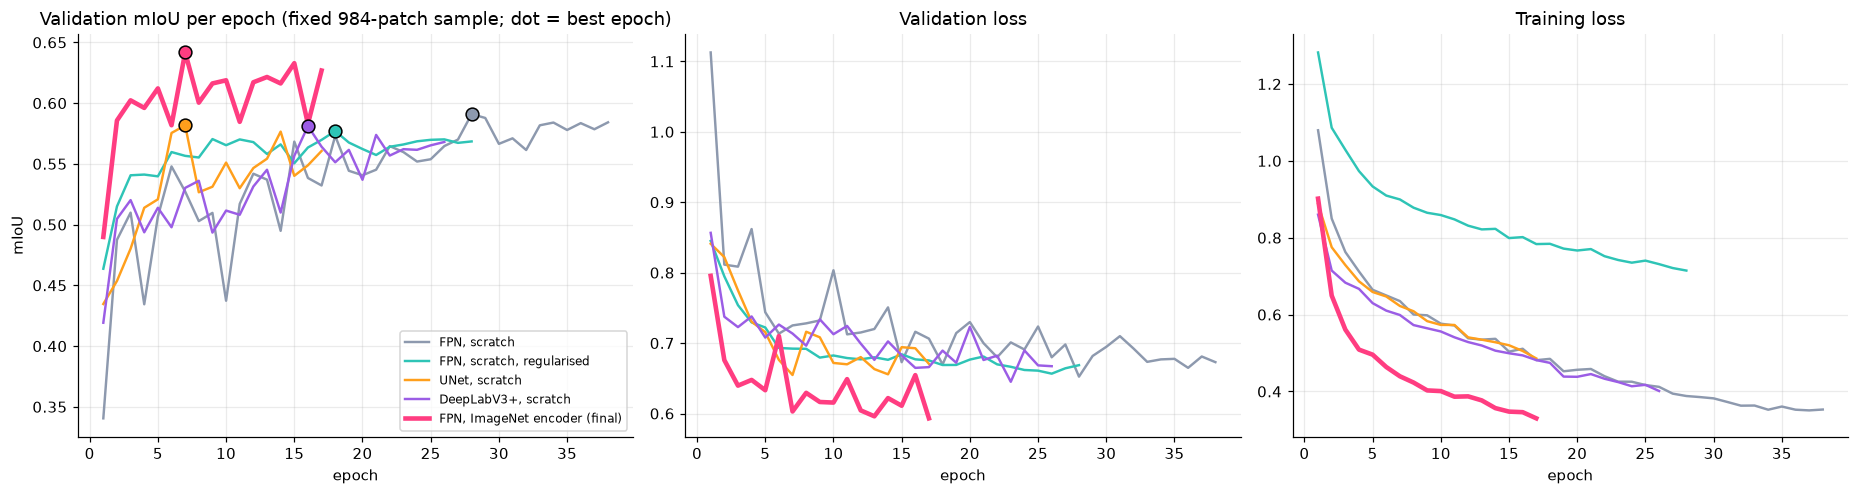

,model,epochs run,best epoch (saved weights),best val mIoU (sample),last-epoch val mIoU
0,"FPN, scratch",38,28,0.591,0.584
1,"FPN, scratch, regularised",28,18,0.577,0.568
2,"UNet, scratch",17,7,0.582,0.561
3,"DeepLabV3+, scratch",26,16,0.581,0.568
4,"FPN, ImageNet encoder (final)",17,7,0.642,0.627


In [34]:
import os
import pandas as pd
import matplotlib.pyplot as plt

WEIGHTS = os.path.expanduser('~/lulc_local/v4_weights')
FIGDIR = 'figures'; os.makedirs(FIGDIR, exist_ok=True)
CLASSES = ['Forest', 'Shrub/Grass', 'Cropland', 'Urban', 'Bare/Arid', 'Water/Wetland']
FINAL = 'v4b_fpn_resnet50_imagenet_ctx'
LABELS = {'v4b_fpn_ctx': 'FPN, scratch', 'v4b_fpn_ctx2': 'FPN, scratch, regularised', 'v4b_unet_ctx': 'UNet, scratch',
          'v4b_deeplabv3p_ctx': 'DeepLabV3+, scratch', FINAL: 'FPN, ImageNet encoder (final)'}
COLORS = {'v4b_fpn_ctx': '#8d99ae', 'v4b_fpn_ctx2': '#2ec4b6', 'v4b_unet_ctx': '#ff9f1c', 'v4b_deeplabv3p_ctx': '#9b5de5', FINAL: '#ff3d81'}
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .25, 'axes.spines.top': False, 'axes.spines.right': False})

hist = {t: pd.read_csv(f'{WEIGHTS}/history_{t}.csv') for t in LABELS if os.path.exists(f'{WEIGHTS}/history_{t}.csv')}
print('histories found:', list(hist))
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for t, h in hist.items():
    lw = 3 if t == FINAL else 1.6; b = h.val_mIoU.idxmax()
    ax[0].plot(h.epoch, h.val_mIoU, color=COLORS[t], lw=lw, label=LABELS[t]); ax[0].scatter(h.epoch[b], h.val_mIoU[b], color=COLORS[t], s=70, zorder=5, edgecolor='k')
    ax[1].plot(h.epoch, h.val_loss, color=COLORS[t], lw=lw); ax[2].plot(h.epoch, h.train_loss, color=COLORS[t], lw=lw)
ax[0].set(title='Validation mIoU per epoch (fixed 984-patch sample; dot = best epoch)', xlabel='epoch', ylabel='mIoU')
ax[1].set(title='Validation loss', xlabel='epoch'); ax[2].set(title='Training loss', xlabel='epoch'); ax[0].legend(fontsize=8)
plt.tight_layout(); fig.savefig(f'{FIGDIR}/training_curves.png', dpi=160, bbox_inches='tight'); plt.show()
pd.DataFrame([{'model': LABELS[t], 'epochs run': len(h), 'best epoch (saved weights)': int(h.epoch[h.val_mIoU.idxmax()]),
               'best val mIoU (sample)': round(h.val_mIoU.max(), 3), 'last-epoch val mIoU': round(h.val_mIoU.iloc[-1], 3)} for t, h in hist.items()])


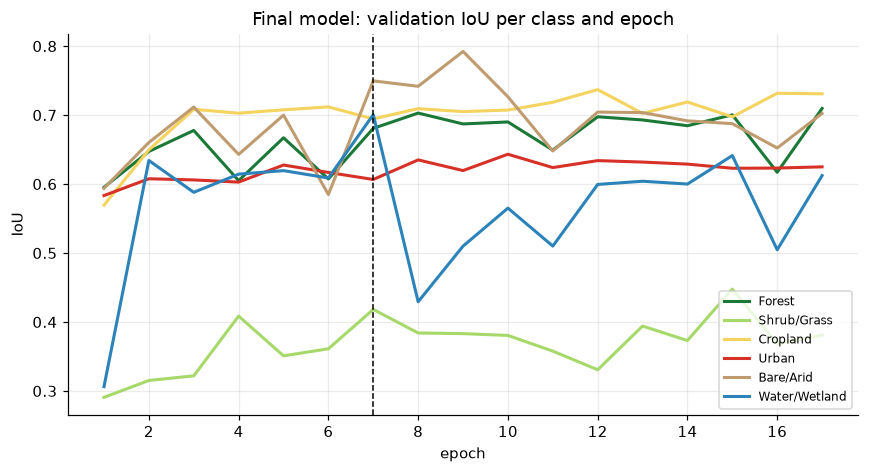

In [35]:
# IoU per class and epoch for the final model (validation sample); the dashed line marks the saved epoch
h = hist[FINAL]; fig, ax = plt.subplots(figsize=(8, 4.4))
for c, col in zip(CLASSES, ['#1b7837', '#a6d96a', '#f4d35e', '#d73027', '#bf9b6f', '#2b83ba']):
    ax.plot(h.epoch, h[f'iou_{c}'], color=col, lw=2, label=c)
ax.axvline(h.epoch[h.val_mIoU.idxmax()], color='k', ls='--', lw=1)
ax.set(title='Final model: validation IoU per class and epoch', xlabel='epoch', ylabel='IoU'); ax.legend(fontsize=8)
plt.tight_layout(); fig.savefig(f'{FIGDIR}/final_model_class_iou_curves.png', dpi=160, bbox_inches='tight'); plt.show()


### Further curves and test results

The cells below read saved files only; they do not train, download or delete anything and do not run the test set again. They reuse the variables of the first cell of this part (`hist`, `WEIGHTS`, `CLASSES`, `FIGDIR`).

- **Generalisation gap:** validation loss minus training loss per epoch. A gap that grows over the epochs is the sign of overfitting.
- **Variant comparison:** full-validation mIoU of the eight model variants with 95% intervals over the 41 validation places. The values are taken from the Part 6 outputs.
- **Test metrics and confusion matrices:** rebuilt from the stored confusion matrices for the test set and the two held-out regions. The printed test result matches the report (OA 0.764, mIoU 0.633).


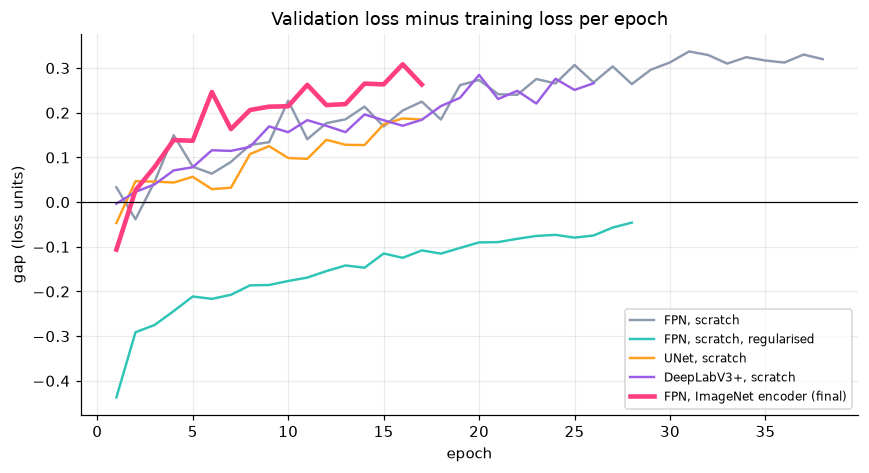

,model,first-epoch gap,last-epoch gap,min val loss,epoch of min val loss
0,"FPN, scratch",0.033,0.320,0.652,28
1,"FPN, scratch, regularised",-0.437,-0.046,0.657,26
2,"UNet, scratch",-0.047,0.185,0.655,7
3,"DeepLabV3+, scratch",-0.003,0.266,0.645,23
4,"FPN, ImageNet encoder (final)",-0.106,0.263,0.593,17


In [36]:
# Generalisation gap per epoch: validation loss minus training loss (a growing gap = overfitting)
# Needs `hist`, `LABELS`, `COLORS`, `FINAL`, `FIGDIR` from the first cell of Part 9.
fig, ax = plt.subplots(figsize=(8, 4.4))
for t, h in hist.items():
    ax.plot(h.epoch, h.val_loss - h.train_loss, color=COLORS[t], lw=3 if t == FINAL else 1.6, label=LABELS[t])
ax.axhline(0, color='k', lw=.8)
ax.set(title='Validation loss minus training loss per epoch', xlabel='epoch', ylabel='gap (loss units)'); ax.legend(fontsize=8)
plt.tight_layout(); fig.savefig(f'{FIGDIR}/generalisation_gap.png', dpi=160, bbox_inches='tight'); plt.show()
pd.DataFrame([{'model': LABELS[t], 'first-epoch gap': round(h.val_loss.iloc[0] - h.train_loss.iloc[0], 3),
               'last-epoch gap': round(h.val_loss.iloc[-1] - h.train_loss.iloc[-1], 3),
               'min val loss': round(h.val_loss.min(), 3), 'epoch of min val loss': int(h.epoch[h.val_loss.idxmin()])} for t, h in hist.items()])


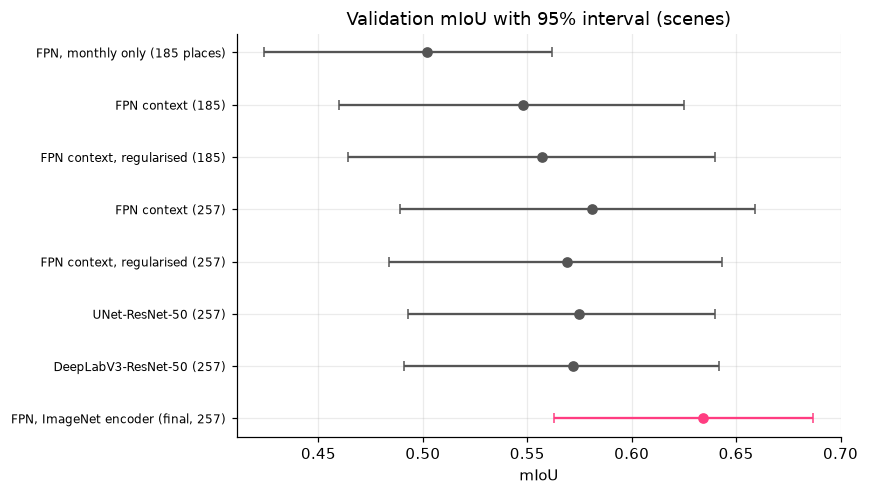

In [37]:
# Full-validation mIoU of the model variants with 95% scene-bootstrap intervals.
# The numbers are copied from the Part 6 outputs / the variant table of the report (41 validation places); nothing is recomputed here.
rows = [('FPN, monthly only (185 places)', .502, .424, .562), ('FPN context (185)', .548, .460, .625),
        ('FPN context, regularised (185)', .557, .464, .640), ('FPN context (257)', .581, .489, .659),
        ('FPN context, regularised (257)', .569, .484, .643), ('UNet-ResNet-50 (257)', .575, .493, .640),
        ('DeepLabV3-ResNet-50 (257)', .572, .491, .642), ('FPN, ImageNet encoder (final, 257)', .634, .563, .687)]
fig, ax = plt.subplots(figsize=(8, 4.6))
for i, (n, m, lo, hi) in enumerate(rows):
    ax.errorbar(m, i, xerr=[[m - lo], [hi - m]], fmt='o', color='#ff3d81' if i == len(rows) - 1 else '#555', capsize=3)
ax.set_yticks(range(len(rows))); ax.set_yticklabels([r[0] for r in rows], fontsize=8); ax.invert_yaxis()
ax.set(title='Validation mIoU with 95% interval (scenes)', xlabel='mIoU')
plt.tight_layout(); fig.savefig(f'{FIGDIR}/variant_miou_intervals.png', dpi=160, bbox_inches='tight'); plt.show()


test OA 0.764, mIoU 0.633   (report: OA 0.764, mIoU 0.633)


,IoU,precision,recall,F1,share %
Forest,0.758,0.857,0.868,0.862,27.447
Shrub/Grass,0.481,0.588,0.725,0.650,23.162
Cropland,0.619,0.840,0.701,0.764,18.114
Urban,0.681,0.712,0.940,0.810,10.301
Bare/Arid,0.528,0.876,0.570,0.691,13.799
Water/Wetland,0.732,0.934,0.772,0.846,7.177


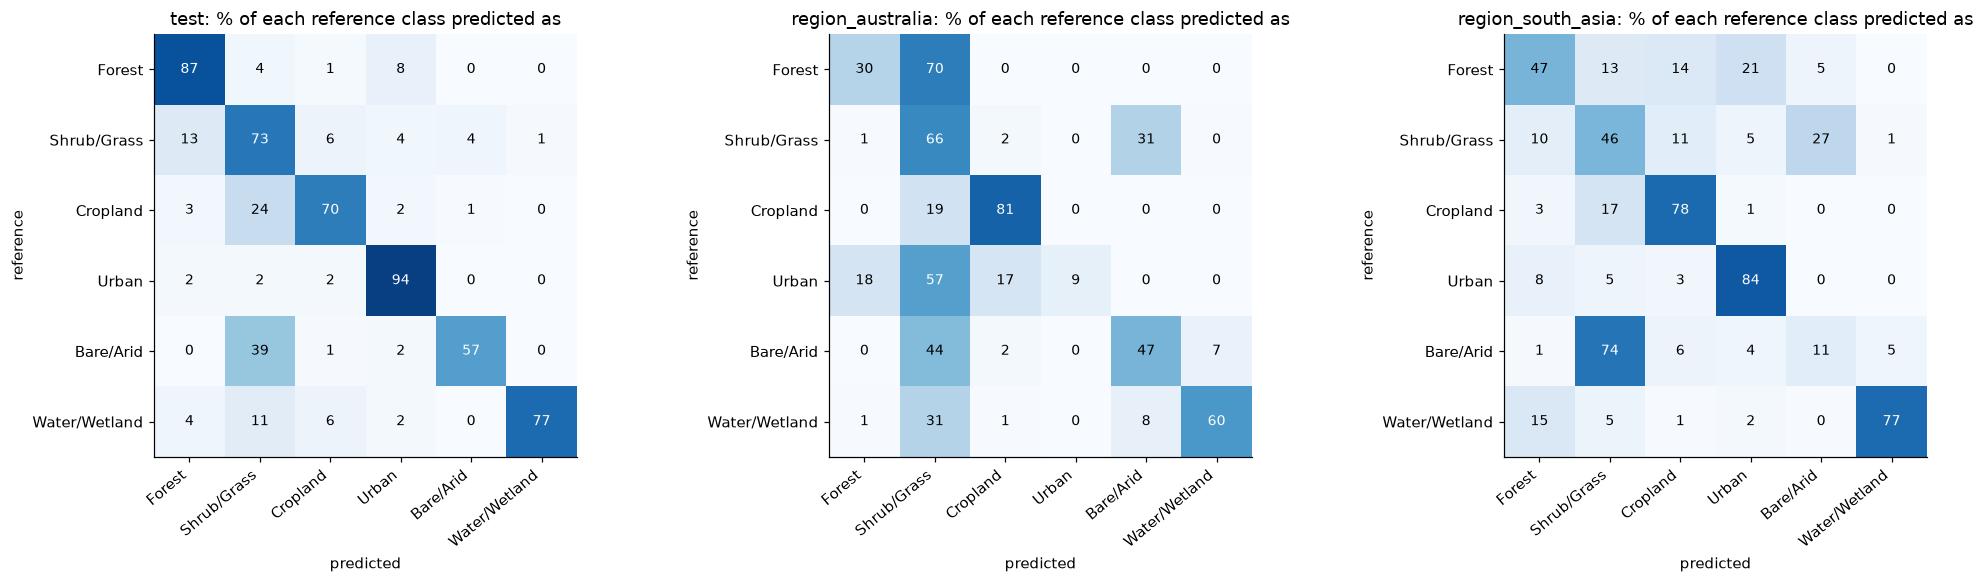

In [38]:
# Test metrics rebuilt from the stored confusion matrices (read-only; no model is run, the test set is not touched again).
import json, numpy as np
f = f'{WEIGHTS}/final_test_v4b.json'
if not os.path.exists(f):
    print('not found:', f)
else:
    splits = json.load(open(f))['splits']
    def metrics(c):
        c = np.asarray(c, float); tp = np.diag(c); fn = c.sum(1) - tp; fp = c.sum(0) - tp
        with np.errstate(divide='ignore', invalid='ignore'):
            iou = tp / (tp + fn + fp); pr = tp / (tp + fp); rc = tp / (tp + fn); f1 = 2 * pr * rc / (pr + rc)
        return dict(oa=tp.sum() / c.sum(), miou=np.nanmean(iou), iou=iou, precision=pr, recall=rc, f1=f1, share=c.sum(1) / c.sum() * 100)
    m = metrics(splits['test']['confusion']['final'])
    print('test OA %.3f, mIoU %.3f   (report: OA 0.764, mIoU 0.633)' % (m['oa'], m['miou']))
    display(pd.DataFrame({'IoU': m['iou'], 'precision': m['precision'], 'recall': m['recall'], 'F1': m['f1'], 'share %': m['share']}, index=CLASSES).round(3))
    sel = [s for s in ['test', 'region_australia', 'region_south_asia'] if s in splits]
    fig, axs = plt.subplots(1, len(sel), figsize=(6.2 * len(sel), 5.4))
    for ax, sp in zip(np.atleast_1d(axs), sel):
        c = np.asarray(splits[sp]['confusion']['final'], float); r = c / np.maximum(c.sum(1, keepdims=True), 1) * 100
        ax.imshow(r, cmap='Blues', vmin=0, vmax=100); ax.set_xticks(range(6)); ax.set_xticklabels(CLASSES, rotation=40, ha='right'); ax.set_yticks(range(6)); ax.set_yticklabels(CLASSES)
        for i in range(6):
            for j in range(6):
                ax.text(j, i, f'{r[i, j]:.0f}', ha='center', va='center', color='white' if r[i, j] > 50 else 'black', fontsize=9)
        ax.set(title=f'{sp}: % of each reference class predicted as', xlabel='predicted', ylabel='reference'); ax.grid(False)
    plt.tight_layout(); fig.savefig(f'{FIGDIR}/confusion_matrices.png', dpi=160, bbox_inches='tight'); plt.show()


## Part 10: Summary of results

| Result | Value |
| --- | --- |
| Places | 370: train 257, validation 41, test 39, Australia 10, South Asia 23 |
| Data | 65.5 GB raw for the first 300 places (27,695 images); the 72 extra places add 6,947 images; training cache 24.4 GB |
| Final model | FPN with a ResNet-50 encoder (ImageNet initialisation), six input channels, 26.1 M parameters; single model; the saved weights are the epoch-7 checkpoint of a run that stopped at epoch 17 |
| Validation (41 places) | OA 0.772, mIoU 0.634 [0.563, 0.687]; scratch twin 0.581 [0.489, 0.659]; gain +0.053 [−0.002, +0.101] |
| Test (39 places) | OA 0.764, mIoU 0.633 [0.545, 0.702], Urban IoU 0.681; an always-Forest guess reaches OA 0.274 |
| Held-out regions | Australia OA 0.587, mIoU 0.291 (constant guess 0.634); South Asia OA 0.666, mIoU 0.417 (constant guess 0.586) |
| Prototype seams | tile by tile: seam excess 17.4 points; whole area: 0.14 points, mIoU +0.0045 |
| False change (82 place-years, whole area) | median raw first-to-last change 2.86%, persistent change 2.58%, largest monthly move 2.55 points (upper bounds) |
| Training exposure | 22,506 of 55,332 patches (40.7%); 8.32 of 16.98 GB of cache; 23.33 of 57.38 GB of raw data |

**Caveats that apply to every number above**

- The test set was looked at **three times** (Part 4: first and second look; Part 6: final). The final model was chosen on validation by rules fixed in advance.
- The validation places also chose the epoch, the architecture and the pipeline, so validation scores are somewhat optimistic.
- Each configuration was trained once (one seed). Most paired differences have intervals that include zero; the direction is reported, not proof. 39 test places give about ±0.07 mIoU.
- The labels are the ESA WorldCover 2021 map (a model product) merged to six classes; the mIoU is not comparable with an 11-class mIoU. The models were trained on 2020 and 2021 imagery.
- The false-change numbers come from places that contain real change, so they are upper bounds.

### Reproducibility notes

Seeds: sampling 2026, training 42, bootstrap 0, sampler replay 43. The cells of Parts 2 to 5 changed data and model files; the cells of Parts 6 to 8 only read them and are safe to re-run with the saved weights. The prototype and its README are in the separate `prototype_v4` folder; the report is a separate document.